# DPL 2026 Hackathon
## Kolkata Knight Riders: Performance Analysis, Player Scouting and Tactical Insights

### 1. Executive Introduction

This notebook presents an end-to-end analysis of the organiser-provided
ball-by-ball dataset, focusing on Kolkata Knight Riders (KKR) across
the 2023 and 2024 seasons.

The analysis combines data-quality assessment, cricket-specific feature
engineering, match and player aggregation, phase-wise performance analysis,
player scouting, tactical analysis, and evidence-based recommendations.

### Analytical Objectives

1. Assess KKR's performance across the two seasons.
2. Identify changes in batting and bowling performance across the
   Powerplay, Middle Overs, and Death Overs.
3. Investigate the relationship between match outcomes and measurable
   team-performance indicators.
4. Identify historical player profiles that could inform scouting.
5. Explore opposition, venue, and in-innings match-state patterns.
6. Translate the findings into practical cricket recommendations.

### Analytical Principles

- Preserve the organiser-provided dataset; do not silently modify
  the raw source data.
- Validate cricket metrics before using them in conclusions.
- Distinguish missing or unavailable information from genuine zeroes.
- Retain incomplete records for appropriate data-quality analysis,
  while excluding them from analyses where completeness is required.
- Use descriptive findings carefully and avoid unsupported causal claims.
- Document assumptions, thresholds, exclusions, and limitations.
- Ensure that the notebook can run from beginning to end without
  depending on variables created in other notebooks.

### Important Dataset Context

The 2024 KKR records include Qualifier 1 and the Final, but omit
KKR's last two league matches. Therefore, the two seasons do not
represent perfectly equivalent sets of fixtures.

This limitation will be considered when comparing season-level
performance and drawing conclusions.


In [92]:
# ============================================================
# 2. Environment and Project Setup
# ============================================================
# This notebook is portable within the submitted project structure.
# It locates the project root, then accepts either the delivery layout
# (sources/) or the prior development layout (data/raw/).
# ============================================================

from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

current_path = Path.cwd().resolve()
candidate_roots = [current_path, *current_path.parents]

PROJECT_ROOT = next(
    (
        root for root in candidate_roots
        if (root / "src").is_dir()
        and ((root / "sources").is_dir() or (root / "data" / "raw").is_dir())
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Run from the project root or notebooks/ directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH_CANDIDATES = [
    PROJECT_ROOT / "sources" / "Data_Premier_League_Prelims_Dataset.csv",
    PROJECT_ROOT / "data" / "raw" / "Data_Premier_League_Prelims_Dataset.csv",
]

DATA_PATH = next((path for path in DATA_PATH_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    expected = " or ".join(str(path.relative_to(PROJECT_ROOT)) for path in DATA_PATH_CANDIDATES)
    raise FileNotFoundError(f"Dataset not found. Expected: {expected}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")
print("Environment setup completed.")


Project root: /Users/soham/MyDocs/Projects/Cricket Analysis/Hackathon - DPL 2026/CodeFiles/Hackathon_DPL2026
Dataset path: /Users/soham/MyDocs/Projects/Cricket Analysis/Hackathon - DPL 2026/CodeFiles/Hackathon_DPL2026/data/raw/Data_Premier_League_Prelims_Dataset.csv
Environment setup completed.


In [93]:
# ============================================================
# 3. Load the Dataset
# ============================================================
# Purpose:
#   Load the raw data without overwriting or modifying the source.
#   Perform basic structural checks before deeper analysis.
# ============================================================

df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]:,}")

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nFirst five records:")
display(df_raw.head())

print("\nData types:")
display(
    df_raw.dtypes
    .astype(str)
    .rename("data_type")
    .to_frame()
)


Dataset loaded successfully.
Rows: 34,967
Columns: 61

Column names:
['row_id', 'p_match', 'inns', 'bat', 'p_bat', 'team_bat', 'bowl', 'p_bowl', 'team_bowl', 'ball', 'ball_id', 'outcome', 'score', 'out', 'dismissal', 'p_out', 'over_num', 'noball', 'wide', 'byes', 'legbyes', 'cur_bat_runs', 'cur_bat_bf', 'cur_bowl_ovr', 'cur_bowl_wkts', 'cur_bowl_runs', 'inns_runs', 'inns_wkts', 'inns_balls', 'inns_runs_rem', 'inns_balls_rem', 'inns_rr', 'inns_rrr', 'target', 'max_balls', 'match_date', 'year', 'ground', 'country', 'winner', 'toss', 'competition', 'bat_hand', 'bowl_style', 'bowl_kind', 'batruns', 'ballfaced', 'bowlruns', 'bat_out', 'wagonx', 'wagony', 'wagonzone', 'line', 'length', 'shot', 'control', 'predscore', 'wprob', 'bowl_speed_category', 'bowl_release_point', 'bowl_type']

First five records:


,row_id,p_match,inns,bat,p_bat,team_bat,bowl,p_bowl,team_bowl,ball,...,wagonzone,line,length,shot,control,predscore,wprob,bowl_speed_category,bowl_release_point,bowl_type
0,225793,1359475,1,Devon Conway,379140,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,1,...,6,ON_THE_STUMPS,SHORT_OF_A_GOOD_LENGTH,DEFENDED,1.0,162,49.42,3.0,2.0,OUTSWINGER
1,225794,1359475,1,Devon Conway,379140,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,2,...,0,ON_THE_STUMPS,SHORT_OF_A_GOOD_LENGTH,FLICK,0.0,161,48.27,3.0,2.0,OUTSWINGER
2,225795,1359475,1,Ruturaj Gaikwad,1060380,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,3,...,5,OUTSIDE_OFFSTUMP,SHORT_OF_A_GOOD_LENGTH,DEFENDED,1.0,160,47.12,2.0,2.0,ANGLED IN
3,225796,1359475,1,Ruturaj Gaikwad,1060380,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,4,...,4,ON_THE_STUMPS,GOOD_LENGTH,ON_DRIVE,1.0,160,47.12,2.0,2.0,OUTSWINGER
4,225797,1359475,1,Devon Conway,379140,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,5,...,5,ON_THE_STUMPS,SHORT_OF_A_GOOD_LENGTH,DEFENDED,1.0,158,44.82,3.0,2.0,INSWINGER



Data types:


,data_type
row_id,int64
p_match,int64
inns,int64
bat,object
p_bat,int64
...,...
predscore,int64
wprob,float64
bowl_speed_category,float64
bowl_release_point,float64


### Data Loading Notes

The raw dataset is retained in `df_raw` as the reference copy.
Subsequent transformations will produce separate DataFrames.

The initial inspection checks the dataset's dimensions, column
structure, data types, and memory footprint. These checks establish
the starting point for the data-quality assessment.

The next section will investigate missingness, duplicate records,
match coverage, and other data-quality concerns before calculating
performance metrics.

## 4. Data Quality Audit

Before analysing team and player performance, we must establish
whether the dataset is structurally reliable and whether its fields
support the metrics we intend to calculate.

The audit covers:

- Missing values and their distribution across columns.
- Duplicate records and delivery identifiers.
- Consistency of player, team, and match identifiers.
- Match and innings coverage.
- Cricket-specific metric inconsistencies.

We will distinguish between issues that require excluding records,
issues that require interpreting a metric cautiously, and issues that
can be retained without affecting the analysis.

In [94]:
# ============================================================
# 4.1 Structural Integrity and Missingness
# ============================================================
# Purpose:
#   Quantify missingness and inspect the dataset's structure.
#   Missing values are not automatically treated as errors:
#   their meaning depends on the column and analytical context.
# ============================================================

# Summarise missingness for every column.
missing_summary = pd.DataFrame({
    "column": df_raw.columns,
    "missing_count": df_raw.isna().sum().values,
    "missing_pct": (
        df_raw.isna().mean().values * 100
    ),
    "data_type": df_raw.dtypes.astype(str).values,
})

missing_summary = (
    missing_summary
    .sort_values(
        ["missing_count", "column"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

print("Dataset dimensions:", df_raw.shape)
print("Total missing cells:", int(df_raw.isna().sum().sum()))
print(
    "Columns containing missing values:",
    int(df_raw.isna().any().sum()),
)

display(
    missing_summary
    .query("missing_count > 0")
    .style.format({"missing_pct": "{:.2f}%"})
)

# Overall missingness by row.
row_missing_count = df_raw.isna().sum(axis=1)

print("\nRows with at least one missing value:",
      int(row_missing_count.gt(0).sum()))

print("Rows with every column populated:",
      int(row_missing_count.eq(0).sum()))

Dataset dimensions: (34967, 61)
Total missing cells: 95530
Columns containing missing values: 11


,column,missing_count,missing_pct,data_type
0,dismissal,33168,94.86%,object
1,inns_rrr,18136,51.87%,float64
2,inns_runs_rem,18136,51.87%,float64
3,target,18136,51.87%,float64
4,bowl_release_point,2379,6.80%,float64
5,bowl_speed_category,2379,6.80%,float64
6,bowl_type,1936,5.54%,object
7,control,963,2.75%,float64
8,shot,194,0.55%,object
9,line,56,0.16%,object



Rows with at least one missing value: 34147
Rows with every column populated: 820


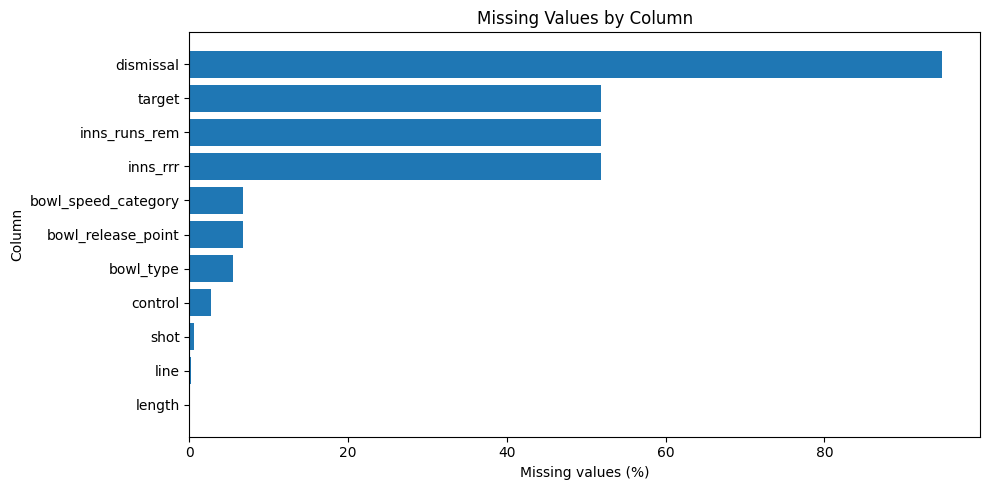

In [95]:
# ============================================================
# 4.2 Missingness Visualisation
# ============================================================
# Purpose:
#   Show which columns have the greatest proportion of missing
#   values, making it easier to prioritise further investigation.
# ============================================================

import matplotlib.pyplot as plt

missing_plot = (
    missing_summary
    .query("missing_count > 0")
    .sort_values("missing_pct", ascending=True)
)

if missing_plot.empty:
    print("No missing values found in the dataset.")
else:
    fig, ax = plt.subplots(figsize=(10, max(5, len(missing_plot) * 0.28)))

    ax.barh(
        missing_plot["column"],
        missing_plot["missing_pct"],
    )

    ax.set_title("Missing Values by Column")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("Column")

    plt.tight_layout()
    plt.show()

In [96]:
# ============================================================
# 4.3 Duplicate Records and Identifier Integrity
# ============================================================
# Purpose:
#   Check for exact duplicate rows and duplicate delivery keys.
#
# A delivery key consists of:
#   p_match + inns + ball_id
#
# The key should uniquely identify a delivery record in this dataset.
# ============================================================

# Exact duplicate rows.
exact_duplicate_count = int(df_raw.duplicated().sum())

# Duplicate delivery identifiers.
delivery_key = ["p_match", "inns", "ball_id"]

missing_key_columns = [
    column
    for column in delivery_key
    if column not in df_raw.columns
]

if missing_key_columns:
    raise KeyError(
        f"Required delivery-key columns are missing: {missing_key_columns}"
    )

missing_delivery_key_count = int(
    df_raw[delivery_key].isna().any(axis=1).sum()
)

duplicate_delivery_key_count = int(
    df_raw.duplicated(subset=delivery_key, keep=False).sum()
)

duplicate_delivery_key_groups = (
    df_raw.loc[
        df_raw.duplicated(subset=delivery_key, keep=False)
    ]
    .sort_values(delivery_key)
)

duplicate_audit = pd.DataFrame({
    "check": [
        "Exact duplicate rows",
        "Rows with incomplete delivery keys",
        "Rows belonging to duplicated delivery keys",
    ],
    "count": [
        exact_duplicate_count,
        missing_delivery_key_count,
        duplicate_delivery_key_count,
    ],
})

display(duplicate_audit)

if not duplicate_delivery_key_groups.empty:
    print("Example records with duplicate delivery keys:")
    display(duplicate_delivery_key_groups.head(10))
else:
    print("No duplicated delivery keys found.")

,check,count
0,Exact duplicate rows,0
1,Rows with incomplete delivery keys,0
2,Rows belonging to duplicated delivery keys,0


No duplicated delivery keys found.


In [97]:
# ============================================================
# 4.4 Player Identifier Consistency
# ============================================================
# Purpose:
#   Verify that a player ID does not map to multiple names.
#   Conflicting mappings can distort player-level aggregation.
# ============================================================

def audit_id_name_mapping(
    data: pd.DataFrame,
    id_column: str,
    name_column: str,
) -> pd.DataFrame:
    """Return IDs associated with more than one distinct name."""

    mapping = (
        data[[id_column, name_column]]
        .dropna(subset=[id_column, name_column])
        .drop_duplicates()
        .groupby(id_column)[name_column]
        .nunique()
    )

    conflicting_ids = mapping[mapping > 1].index

    return (
        data.loc[
            data[id_column].isin(conflicting_ids),
            [id_column, name_column],
        ]
        .drop_duplicates()
        .sort_values([id_column, name_column])
        .reset_index(drop=True)
    )


player_mapping_checks = {
    "Batter ID to batter name": ("p_bat", "bat"),
    "Bowler ID to bowler name": ("p_bowl", "bowl"),
}

for label, (id_column, name_column) in player_mapping_checks.items():
    conflicts = audit_id_name_mapping(
        df_raw,
        id_column,
        name_column,
    )

    print(f"{label}: {len(conflicts)} conflicting mapping rows")

    if not conflicts.empty:
        display(conflicts.head(20))

Batter ID to batter name: 0 conflicting mapping rows
Bowler ID to bowler name: 0 conflicting mapping rows


In [98]:
# ============================================================
# 4.5 Audit Assertions
# ============================================================
# Purpose:
#   Convert key data-quality expectations into executable checks.
#   Assertions make unexpected changes visible when the notebook
#   is rerun against the dataset.
# ============================================================

assert df_raw.shape == (34967, 61), (
    f"Unexpected dataset dimensions: {df_raw.shape}"
)

assert exact_duplicate_count == 0, (
    f"Unexpected exact duplicate count: {exact_duplicate_count}"
)

assert missing_delivery_key_count == 0, (
    f"Rows have incomplete delivery keys: {missing_delivery_key_count}"
)

assert duplicate_delivery_key_count == 0, (
    f"Duplicate delivery-key rows detected: {duplicate_delivery_key_count}"
)

for label, (id_column, name_column) in player_mapping_checks.items():
    conflicts = audit_id_name_mapping(
        df_raw,
        id_column,
        name_column,
    )

    assert conflicts.empty, (
        f"Conflicting player mappings detected: {label}"
    )

print("All structural integrity assertions passed.")

All structural integrity assertions passed.


## 5. Match Coverage and Data Quality

A dataset can have no duplicate records and still contain incomplete
matches or inconsistencies in cricket-specific fields.

This section investigates:

1. Match and season coverage.
2. Represented innings and batting teams per match.
3. The incomplete match.
4. Consistency of match metadata.
5. Bowling-run discrepancies and their implications.

We will retain the original records and document any exclusions
made for subsequent analyses.

In [99]:
# ============================================================
# 5.1 Match-Level Coverage
# ============================================================
# "Represented" means present in the supplied dataset; it does not
# independently establish whether a match was completed in reality.
# ============================================================

required_match_columns = ["p_match", "year", "inns", "team_bat", "team_bowl"]
missing_columns = [column for column in required_match_columns if column not in df_raw.columns]
if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

match_coverage = (
    df_raw.groupby("p_match", dropna=False)
    .agg(
        year=("year", "first"),
        year_values=("year", "nunique"),
        innings_represented=("inns", "nunique"),
        batting_teams_represented=("team_bat", "nunique"),
        bowling_teams_represented=("team_bowl", "nunique"),
        delivery_records=("p_match", "size"),
    )
    .reset_index()
)

match_coverage["year_metadata_conflict"] = match_coverage["year_values"].ne(1)

print("Distinct matches:", match_coverage["p_match"].nunique())
print("\nMatches represented by season:")
display(
    match_coverage.groupby("year", dropna=False)
    .agg(
        matches=("p_match", "nunique"),
        total_delivery_records=("delivery_records", "sum"),
    )
    .reset_index()
)

print("\nRepresented innings per match:")
display(
    match_coverage["innings_represented"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("innings_represented")
    .reset_index(name="matches")
)

print("\nMatches with fewer than two represented innings:")
incomplete_matches = match_coverage.loc[match_coverage["innings_represented"] < 2].copy()
display(incomplete_matches)

print("\nMatches with fewer than two represented batting teams:")
single_batting_team_matches = match_coverage.loc[
    match_coverage["batting_teams_represented"] < 2
].copy()
display(single_batting_team_matches)


Distinct matches: 145

Matches represented by season:


,year,matches,total_delivery_records
0,2023,74,17864
1,2024,71,17103



Represented innings per match:


,innings_represented,matches
0,1,1
1,2,144



Matches with fewer than two represented innings:


,p_match,year,year_values,innings_represented,batting_teams_represented,bowling_teams_represented,delivery_records,year_metadata_conflict
44,1359519,2023,1,1,1,1,119,False



Matches with fewer than two represented batting teams:


,p_match,year,year_values,innings_represented,batting_teams_represented,bowling_teams_represented,delivery_records,year_metadata_conflict
44,1359519,2023,1,1,1,1,119,False


In [100]:
# ============================================================
# 5.2 Incomplete-Match Validation
# ============================================================
# The initial audit identified one match with only one represented
# innings and one represented batting team.
#
# We validate the result here so that any future dataset changes
# become visible instead of being silently ignored.
# ============================================================

print("Incomplete-match count:", len(incomplete_matches))

if not incomplete_matches.empty:
    incomplete_match_ids = incomplete_matches["p_match"].tolist()

    print("Incomplete match IDs:", incomplete_match_ids)

    display(
        df_raw.loc[
            df_raw["p_match"].isin(incomplete_match_ids)
        ]
        .sort_values(["p_match", "inns", "ball_id"])
        .head(20)
    )

assert len(match_coverage) == 145, (
    f"Expected 145 represented matches; found {len(match_coverage)}"
)

assert len(incomplete_matches) == 1, (
    f"Expected one match with fewer than two represented innings; "
    f"found {len(incomplete_matches)}"
)

assert len(single_batting_team_matches) == 1, (
    f"Expected one match with fewer than two represented batting teams; "
    f"found {len(single_batting_team_matches)}"
)

print("Match coverage checks passed.")

Incomplete-match count: 1
Incomplete match IDs: [1359519]


,row_id,p_match,inns,bat,p_bat,team_bat,bowl,p_bowl,team_bowl,ball,...,wagonzone,line,length,shot,control,predscore,wprob,bowl_speed_category,bowl_release_point,bowl_type
10798,236589,1359519,1,Manan Vohra,532856,Lucknow Super Giants,Deepak Chahar,447261,Chennai Super Kings,1,...,2,ON_THE_STUMPS,GOOD_LENGTH,FLICK,1.0,174,60.28,3.0,2.0,ANGLED IN
10799,236590,1359519,1,Kyle Mayers,348056,Lucknow Super Giants,Deepak Chahar,447261,Chennai Super Kings,2,...,4,ON_THE_STUMPS,GOOD_LENGTH,DEFENDED,0.0,173,59.18,3.0,2.0,INSWINGER
10800,236591,1359519,1,Kyle Mayers,348056,Lucknow Super Giants,Deepak Chahar,447261,Chennai Super Kings,3,...,0,OUTSIDE_OFFSTUMP,FULL,COVER_DRIVE,0.0,171,56.96,3.0,2.0,OUTSWINGER
10801,236592,1359519,1,Kyle Mayers,348056,Lucknow Super Giants,Deepak Chahar,447261,Chennai Super Kings,4,...,0,ON_THE_STUMPS,GOOD_LENGTH,DEFENDED,0.0,170,55.83,3.0,2.0,OUTSWINGER
10802,236593,1359519,1,Kyle Mayers,348056,Lucknow Super Giants,Deepak Chahar,447261,Chennai Super Kings,5,...,3,WIDE_OUTSIDE_OFFSTUMP,FULL_TOSS,COVER_DRIVE,1.0,168,53.57,3.0,2.0,OUTSWINGER
10803,236594,1359519,1,Kyle Mayers,348056,Lucknow Super Giants,Deepak Chahar,447261,Chennai Super Kings,6,...,3,OUTSIDE_OFFSTUMP,SHORT_OF_A_GOOD_LENGTH,CUT_SHOT,1.0,170,55.83,3.0,2.0,OUTSWINGER
10804,236595,1359519,1,Manan Vohra,532856,Lucknow Super Giants,Tushar Deshpande,822553,Chennai Super Kings,1,...,7,OUTSIDE_OFFSTUMP,SHORT_OF_A_GOOD_LENGTH,PUSH,1.0,169,54.70,2.0,2.0,OUTSWINGER
10805,236596,1359519,1,Manan Vohra,532856,Lucknow Super Giants,Tushar Deshpande,822553,Chennai Super Kings,2,...,5,OUTSIDE_OFFSTUMP,GOOD_LENGTH,ON_DRIVE,1.0,168,53.57,2.0,2.0,OUTSWINGER
10806,236597,1359519,1,Kyle Mayers,348056,Lucknow Super Giants,Tushar Deshpande,822553,Chennai Super Kings,3,...,5,ON_THE_STUMPS,SHORT_OF_A_GOOD_LENGTH,REVERSE_SWEEP,1.0,167,52.43,2.0,2.0,INSWINGER
10807,236598,1359519,1,Kyle Mayers,348056,Lucknow Super Giants,Tushar Deshpande,822553,Chennai Super Kings,4,...,3,ON_THE_STUMPS,SHORT_OF_A_GOOD_LENGTH,COVER_DRIVE,1.0,165,50.14,2.0,2.0,INSWINGER


Match coverage checks passed.


## 6. Cricket-Specific Metric Validation

### 6.1 Bowling Runs

Bowling runs conceded must be handled carefully because the source
contains records where `bowlruns` differs from a candidate
reconstruction using batter runs, wides, and no-ball extras.

We will:

- Preserve the source `bowlruns` field.
- Calculate a candidate value solely for comparison.
- Identify the affected records and their associated extras.
- Quantify the impact on KKR's bowling analysis.
- Avoid silently replacing the source field.

In [101]:
# ============================================================
# 6.1 Bowling-Run Reconciliation
# ============================================================
# Purpose:
#   Compare the source bowling-run field with a candidate formula.
#
# IMPORTANT:
#   This is a diagnostic check, not an instruction to overwrite
#   the source data.
# ============================================================

bowling_run_columns = [
    "bowlruns",
    "batruns",
    "wide",
    "noball",
    "byes",
    "legbyes",
    "p_match",
    "inns",
    "ball_id",
    "team_bat",
    "team_bowl",
    "bat",
    "bowl",
    "year",
]

missing_columns = [
    column
    for column in bowling_run_columns
    if column not in df_raw.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns required for bowling-run analysis: {missing_columns}"
    )

bowling_audit = df_raw.copy()

# Fill missing extra values with zero only for this diagnostic formula.
# The original columns in df_raw remain unchanged.
for column in ["batruns", "wide", "noball"]:
    bowling_audit[f"{column}_diagnostic"] = (
        pd.to_numeric(bowling_audit[column], errors="coerce")
        .fillna(0)
    )

bowling_audit["candidate_bowlruns"] = (
    bowling_audit["batruns_diagnostic"]
    + bowling_audit["wide_diagnostic"]
    + bowling_audit["noball_diagnostic"]
)

bowling_audit["bowlruns_difference"] = (
    bowling_audit["candidate_bowlruns"]
    - pd.to_numeric(bowling_audit["bowlruns"], errors="coerce")
)

bowling_run_mismatches = bowling_audit.loc[
    bowling_audit["bowlruns_difference"].notna()
    & ~np.isclose(
        bowling_audit["candidate_bowlruns"],
        pd.to_numeric(bowling_audit["bowlruns"], errors="coerce"),
    )
].copy()

print("Delivery records:", len(bowling_audit))
print("Bowling-run mismatches:", len(bowling_run_mismatches))

print("\nMismatch magnitude:")
display(
    bowling_run_mismatches["bowlruns_difference"]
    .value_counts()
    .sort_index()
    .rename_axis("candidate_minus_source")
    .reset_index(name="records")
)

print("\nMismatch records:")
display(
    bowling_run_mismatches[
        [
            "p_match",
            "year",
            "inns",
            "ball_id",
            "team_bat",
            "team_bowl",
            "bat",
            "bowl",
            "batruns",
            "wide",
            "noball",
            "byes",
            "legbyes",
            "bowlruns",
            "candidate_bowlruns",
            "bowlruns_difference",
        ]
    ].sort_values(["year", "p_match", "inns", "ball_id"])
)

assert len(bowling_run_mismatches) == 14, (
    f"Expected 14 bowling-run mismatches; found "
    f"{len(bowling_run_mismatches)}"
)

print("Bowling-run reconciliation check passed.")

Delivery records: 34967
Bowling-run mismatches: 14

Mismatch magnitude:


,candidate_minus_source,records
0,1,8
1,4,6



Mismatch records:


,p_match,year,inns,ball_id,team_bat,team_bowl,bat,bowl,batruns,wide,noball,byes,legbyes,bowlruns,candidate_bowlruns,bowlruns_difference
1452,1359480,2023,2,19.02,Lucknow Super Giants,Chennai Super Kings,Krishnappa Gowtham,Tushar Deshpande,0,0,1,0,1,0,1,1
1813,1359482,2023,1,18.04,Punjab Kings,Rajasthan Royals,M Shahrukh Khan,KM Asif,0,0,1,1,0,0,1,1
4565,1359493,2023,2,9.04,Kolkata Knight Riders,Sunrisers Hyderabad,Nitish Rana,Marco Jansen,0,0,1,0,1,0,1,1
4951,1359495,2023,1,10.05,Lucknow Super Giants,Punjab Kings,Krunal Pandya,Sikandar Raza,0,0,1,0,4,-3,1,4
9151,1359512,2023,1,15.05,Lucknow Super Giants,Punjab Kings,Marcus Stoinis,Kagiso Rabada,0,0,1,0,1,0,1,1
13024,1359528,2023,2,12.03,Mumbai Indians,Royal Challengers Bengaluru,Nehal Wadhera,Harshal Patel,0,0,1,0,4,-3,1,4
15180,1359537,2023,2,18.04,Mumbai Indians,Lucknow Super Giants,Tim David,Naveen-ul-Haq,0,0,1,4,0,-3,1,4
17044,1370350,2023,1,19.04,Chennai Super Kings,Gujarat Titans,Moeen Ali,Mohammed Shami,0,0,1,1,0,0,1,1
20870,1422131,2024,1,5.02,Delhi Capitals,Chennai Super Kings,David Warner,Mustafizur Rahman,0,0,1,0,1,0,1,1
21786,1422134,2024,2,14.03,Delhi Capitals,Kolkata Knight Riders,Tristan Stubbs,Varun Chakravarthy,0,0,1,4,0,-3,1,4


Bowling-run reconciliation check passed.


In [102]:
# ============================================================
# 6.2 Investigate the Context of Bowling-Run Mismatches
# ============================================================
# Purpose:
#   Determine whether mismatches share a common pattern in their
#   extras fields. This helps explain why a simple reconstruction
#   may not agree with the supplied bowling-run value.
# ============================================================

extra_pattern_columns = [
    "wide",
    "noball",
    "byes",
    "legbyes",
]

mismatch_extra_summary = (
    bowling_run_mismatches[extra_pattern_columns]
    .fillna(0)
    .groupby(extra_pattern_columns, dropna=False)
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)

display(mismatch_extra_summary)

print("\nMismatch records with a no-ball and non-zero byes or leg-byes:")

mismatch_no_ball_and_byes = bowling_run_mismatches.loc[
    bowling_run_mismatches["noball"].fillna(0).ne(0)
    & (
        bowling_run_mismatches["byes"].fillna(0).ne(0)
        | bowling_run_mismatches["legbyes"].fillna(0).ne(0)
    )
]

display(
    mismatch_no_ball_and_byes[
        [
            "p_match",
            "year",
            "inns",
            "ball_id",
            "team_bat",
            "team_bowl",
            "bat",
            "bowl",
            "batruns",
            "noball",
            "byes",
            "legbyes",
            "bowlruns",
            "candidate_bowlruns",
            "bowlruns_difference",
        ]
    ]
)

assert len(mismatch_no_ball_and_byes) == 14, (
    "The previously observed extra-related mismatch pattern has changed."
)

,wide,noball,byes,legbyes,records
0,0,1,0,1,6
3,0,1,4,0,4
1,0,1,0,4,2
2,0,1,1,0,2



Mismatch records with a no-ball and non-zero byes or leg-byes:


,p_match,year,inns,ball_id,team_bat,team_bowl,bat,bowl,batruns,noball,byes,legbyes,bowlruns,candidate_bowlruns,bowlruns_difference
1452,1359480,2023,2,19.02,Lucknow Super Giants,Chennai Super Kings,Krishnappa Gowtham,Tushar Deshpande,0,1,0,1,0,1,1
1813,1359482,2023,1,18.04,Punjab Kings,Rajasthan Royals,M Shahrukh Khan,KM Asif,0,1,1,0,0,1,1
4565,1359493,2023,2,9.04,Kolkata Knight Riders,Sunrisers Hyderabad,Nitish Rana,Marco Jansen,0,1,0,1,0,1,1
4951,1359495,2023,1,10.05,Lucknow Super Giants,Punjab Kings,Krunal Pandya,Sikandar Raza,0,1,0,4,-3,1,4
9151,1359512,2023,1,15.05,Lucknow Super Giants,Punjab Kings,Marcus Stoinis,Kagiso Rabada,0,1,0,1,0,1,1
13024,1359528,2023,2,12.03,Mumbai Indians,Royal Challengers Bengaluru,Nehal Wadhera,Harshal Patel,0,1,0,4,-3,1,4
15180,1359537,2023,2,18.04,Mumbai Indians,Lucknow Super Giants,Tim David,Naveen-ul-Haq,0,1,4,0,-3,1,4
17044,1370350,2023,1,19.04,Chennai Super Kings,Gujarat Titans,Moeen Ali,Mohammed Shami,0,1,1,0,0,1,1
20870,1422131,2024,1,5.02,Delhi Capitals,Chennai Super Kings,David Warner,Mustafizur Rahman,0,1,0,1,0,1,1
21786,1422134,2024,2,14.03,Delhi Capitals,Kolkata Knight Riders,Tristan Stubbs,Varun Chakravarthy,0,1,4,0,-3,1,4


In [103]:
# ============================================================
# 6.3 Potential Impact on KKR Bowling Metrics
# ============================================================
# Purpose:
#   Compare source and candidate runs for KKR's bowlers.
#
# Legal deliveries determine the denominator for economy rate.
# This comparison changes only the runs-conceded numerator.
# ============================================================

kkr_bowlers = ["Vaibhav Arora", "Varun Chakravarthy"]

kkr_bowling_audit = bowling_audit.loc[
    bowling_audit["bowl"].isin(kkr_bowlers)
].copy()

# A legal delivery is neither a wide nor a no-ball.
kkr_bowling_audit["legal_delivery"] = (
    kkr_bowling_audit["wide"].fillna(0).eq(0)
    & kkr_bowling_audit["noball"].fillna(0).eq(0)
)

kkr_bowling_impact = (
    kkr_bowling_audit.groupby("bowl")
    .agg(
        source_runs=("bowlruns", "sum"),
        candidate_runs=("candidate_bowlruns", "sum"),
        legal_balls=("legal_delivery", "sum"),
        deliveries=("ball_id", "size"),
    )
    .reset_index()
)

kkr_bowling_impact["source_economy"] = (
    kkr_bowling_impact["source_runs"]
    / (kkr_bowling_impact["legal_balls"] / 6)
)

kkr_bowling_impact["candidate_economy"] = (
    kkr_bowling_impact["candidate_runs"]
    / (kkr_bowling_impact["legal_balls"] / 6)
)

kkr_bowling_impact["economy_difference"] = (
    kkr_bowling_impact["candidate_economy"]
    - kkr_bowling_impact["source_economy"]
)

display(
    kkr_bowling_impact.style.format({
        "source_runs": "{:.0f}",
        "candidate_runs": "{:.0f}",
        "legal_balls": "{:.0f}",
        "source_economy": "{:.3f}",
        "candidate_economy": "{:.3f}",
        "economy_difference": "{:+.3f}",
    })
)

,bowl,source_runs,candidate_runs,legal_balls,deliveries,source_economy,candidate_economy,economy_difference
0,Vaibhav Arora,418,422,276,308,9.087,9.174,+0.087
1,Varun Chakravarthy,827,831,616,632,8.055,8.094,+0.039


### Data Quality Findings and Analytical Decisions

The audit establishes several important constraints for the remainder
of the analysis:

1. The dataset contains 34,967 delivery records across 145 represented
   matches in the 2023 and 2024 seasons.

2. No exact duplicate rows or duplicate delivery identifiers were
   detected in the supplied dataset.

3. One match has only one represented innings and one represented
   batting team. It must be excluded from analyses that require
   complete match coverage, but its available records can still be
   useful for appropriate delivery-level analyses.

4. Fourteen records have a discrepancy between the source `bowlruns`
   value and a candidate reconstruction. The source values are retained,
   and the discrepancies are documented rather than silently corrected.

5. Cricket metrics must use explicit definitions. In particular,
   legal deliveries, batter-facing balls, bowling dots, and
   bowler-credited wickets are distinct concepts.

6. KKR's 2024 represented matches include Qualifier 1 and the Final
   but omit two league matches. Season-level comparisons therefore
   require this qualification.

These constraints will inform feature engineering, aggregation,
visualisation, tactical analysis, and the final recommendations.

## 7. Feature Engineering: Cricket Metric Definitions

This section implements the cricket-specific metric functions used
throughout the analysis.

All functions are defined within this notebook. The analytical
workflow therefore does not depend on custom Python modules or
functions defined in other notebooks.

We distinguish between:

- Legal deliveries and balls faced.
- Batting dot balls and bowling dot balls.
- Boundary balls and boundary runs.
- Wicket events and bowler-credited wickets.
- Wides, no-ball extras, and combined extras.
- Powerplay, Middle Overs, and Death Overs.

The functions preserve the definitions established during the
earlier analysis and are validated before being used downstream.

In [104]:
# ============================================================
# 7.1 Legal Deliveries and Dot Balls
# ============================================================

def derive_legal_delivery(df: pd.DataFrame) -> pd.Series:
    """
    Identify legal deliveries.

    A delivery is legal when it is neither a wide nor a no-ball.

    Parameters
    ----------
    df : pd.DataFrame
        Ball-by-ball dataset containing 'wide' and 'noball'.

    Returns
    -------
    pd.Series
        Boolean Series indicating legal deliveries.
    """
    return (
        df["wide"].eq(0)
        & df["noball"].eq(0)
    ).fillna(False).astype(bool)


def derive_batting_dot(df: pd.DataFrame) -> pd.Series:
    """
    Identify batting dot balls.

    A batting dot is a batter-facing delivery on which the batter
    scores zero runs off the bat.

    This definition does not require the delivery to be legal.
    """
    return (
        df["ballfaced"].eq(1)
        & df["batruns"].eq(0)
    ).fillna(False).astype(bool)


def derive_bowling_dot(
    df: pd.DataFrame,
    legal_delivery=None,
) -> pd.Series:
    """
    Identify bowling dot balls.

    A bowling dot is a legal delivery on which the source 'score'
    field records zero runs.

    Parameters
    ----------
    df : pd.DataFrame
        Ball-by-ball dataset.
    legal_delivery : pd.Series, optional
        Boolean Series identifying legal deliveries.
        If not provided, it is derived from df.

    Returns
    -------
    pd.Series
        Boolean Series indicating bowling dot balls.
    """
    if legal_delivery is None:
        legal_delivery = derive_legal_delivery(df)

    return (
        legal_delivery
        & df["score"].eq(0)
    ).fillna(False).astype(bool)

In [105]:
# ============================================================
# 7.2 Wickets and Match Phases
# ============================================================

def derive_bowler_credited_wicket(df: pd.DataFrame) -> pd.Series:
    """
    Identify wicket events credited to the bowler.

    Uses the source 'out' field and the established list of
    bowler-credited dismissal types.
    """
    bowler_credited_dismissals = {
        "caught",
        "bowled",
        "leg before wicket",
        "stumped",
        "hit wicket",
    }

    return (
        df["out"].eq(True)
        & df["dismissal"].isin(bowler_credited_dismissals)
    ).fillna(False).astype(bool)


def derive_match_phase(over_num: pd.Series) -> pd.Series:
    """
    Assign each one-based over number to a match phase.

    Powerplay: overs 1–6
    Middle:    overs 7–15
    Death:     overs 16–20

    Values outside these ranges are returned as missing.
    """
    phase = pd.Series(
        pd.NA,
        index=over_num.index,
        dtype="string",
    )

    phase.loc[over_num.between(1, 6)] = "Powerplay"
    phase.loc[over_num.between(7, 15)] = "Middle"
    phase.loc[over_num.between(16, 20)] = "Death"

    return phase

In [106]:
# ============================================================
# 7.3 Boundaries and Extras
# ============================================================

def derive_boundary_ball(df: pd.DataFrame) -> pd.Series:
    """
    Identify batter-facing deliveries resulting in four or six
    runs off the bat.
    """
    return (
        df["ballfaced"].eq(1)
        & df["batruns"].isin([4, 6])
    ).fillna(False).astype(bool)


def derive_boundary_runs(df: pd.DataFrame) -> pd.Series:
    """
    Count runs scored off the bat through fours and sixes.

    This metric is not the total runs conceded on every delivery
    that produces a boundary.
    """
    return df["batruns"].where(
        df["batruns"].isin([4, 6]),
        0,
    )


def derive_wides(df: pd.DataFrame) -> pd.Series:
    """Return wides, treating missing values as zero."""
    return df["wide"].fillna(0)


def derive_noball_extras(df: pd.DataFrame) -> pd.Series:
    """Return no-ball extras, treating missing values as zero."""
    return df["noball"].fillna(0)


def derive_wide_noball_extras(df: pd.DataFrame) -> pd.Series:
    """Return combined wides and no-ball extras."""
    return (
        derive_wides(df)
        + derive_noball_extras(df)
    )

In [107]:
# ============================================================
# 7.4 Apply All Metric Definitions
# ============================================================

def add_metric_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Return a copy of the input DataFrame with analytical features.

    The source DataFrame is not modified.
    """
    result = df.copy()

    result["legal_delivery"] = derive_legal_delivery(result)
    result["batting_dot"] = derive_batting_dot(result)

    result["bowling_dot"] = derive_bowling_dot(
        result,
        legal_delivery=result["legal_delivery"],
    )

    result["bowler_credited_wicket"] = (
        derive_bowler_credited_wicket(result)
    )

    result["match_phase"] = derive_match_phase(
        result["over_num"]
    )

    result["boundary_ball"] = derive_boundary_ball(result)
    result["boundary_runs"] = derive_boundary_runs(result)

    result["wides"] = derive_wides(result)
    result["noball_extras"] = derive_noball_extras(result)

    result["wide_noball_extras"] = (
        derive_wide_noball_extras(result)
    )

    return result

In [108]:
# ============================================================
# 7.5 Create the Feature-Enriched Dataset
# ============================================================

df_features = add_metric_features(df_raw)

print("Raw dataset shape:", df_raw.shape)
print("Feature-enriched dataset shape:", df_features.shape)

new_columns = [
    column
    for column in df_features.columns
    if column not in df_raw.columns
]

print("\nDerived features:")
print(new_columns)

display(df_features.head())

Raw dataset shape: (34967, 61)
Feature-enriched dataset shape: (34967, 71)

Derived features:
['legal_delivery', 'batting_dot', 'bowling_dot', 'bowler_credited_wicket', 'match_phase', 'boundary_ball', 'boundary_runs', 'wides', 'noball_extras', 'wide_noball_extras']


,row_id,p_match,inns,bat,p_bat,team_bat,bowl,p_bowl,team_bowl,ball,...,legal_delivery,batting_dot,bowling_dot,bowler_credited_wicket,match_phase,boundary_ball,boundary_runs,wides,noball_extras,wide_noball_extras
0,225793,1359475,1,Devon Conway,379140,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,1,...,True,True,True,False,Powerplay,False,0,0,0,0
1,225794,1359475,1,Devon Conway,379140,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,2,...,True,True,False,False,Powerplay,False,0,0,0,0
2,225795,1359475,1,Ruturaj Gaikwad,1060380,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,3,...,True,True,True,False,Powerplay,False,0,0,0,0
3,225796,1359475,1,Ruturaj Gaikwad,1060380,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,4,...,True,False,False,False,Powerplay,False,0,0,0,0
4,225797,1359475,1,Devon Conway,379140,Chennai Super Kings,Mohammed Shami,481896,Gujarat Titans,5,...,True,True,True,False,Powerplay,False,0,0,0,0


In [109]:
# ============================================================
# 7.6 Validate Derived Features
# ============================================================

# Independently reconstruct expected legal deliveries.
expected_legal = (
    df_features["wide"].eq(0)
    & df_features["noball"].eq(0)
).fillna(False)

assert (
    df_features["legal_delivery"]
    == expected_legal
).all()

# Validate the match-phase boundaries.
# Validate match-phase boundaries.
test_overs = pd.Series([1, 6, 7, 15, 16, 20, 21])

actual_phases = derive_match_phase(test_overs)

expected_phases = [
    "Powerplay",
    "Powerplay",
    "Middle",
    "Middle",
    "Death",
    "Death",
    pd.NA,
]

# Compare valid phase labels individually.
assert actual_phases.iloc[:6].tolist() == expected_phases[:6]

# The invalid over should produce a missing value.
assert pd.isna(actual_phases.iloc[6])

print("Match-phase boundary validation passed.")

# Validate boundary balls.
expected_boundary_ball = (
    df_features["ballfaced"].eq(1)
    & df_features["batruns"].isin([4, 6])
).fillna(False)

assert (
    df_features["boundary_ball"]
    == expected_boundary_ball
).all()

# Validate boundary runs.
expected_boundary_runs = df_features["batruns"].where(
    df_features["batruns"].isin([4, 6]),
    0,
)

assert np.allclose(
    df_features["boundary_runs"],
    expected_boundary_runs,
    equal_nan=True,
)

# Validate bowler-credited wickets.
expected_bowler_wickets = (
    df_features["out"].eq(True)
    & df_features["dismissal"].isin(
        [
            "caught",
            "bowled",
            "leg before wicket",
            "stumped",
            "hit wicket",
        ]
    )
)

assert (
    df_features["bowler_credited_wicket"]
    == expected_bowler_wickets
).all()

print("All feature-definition assertions passed.")

Match-phase boundary validation passed.
All feature-definition assertions passed.


In [110]:
# ============================================================
# 7.7 Reconcile Feature Totals
# ============================================================

metric_totals = pd.DataFrame({
    "metric": [
        "Boundary balls",
        "Boundary runs",
        "Wides",
        "No-ball extras",
        "Combined wides and no-ball extras",
    ],
    "observed_total": [
        int(df_features["boundary_ball"].sum()),
        int(df_features["boundary_runs"].sum()),
        int(df_features["wides"].sum()),
        int(df_features["noball_extras"].sum()),
        int(df_features["wide_noball_extras"].sum()),
    ],
    "expected_total": [
        6735,
        31710,
        1591,
        175,
        1766,
    ],
})

metric_totals["difference"] = (
    metric_totals["observed_total"]
    - metric_totals["expected_total"]
)

display(metric_totals)

assert metric_totals["difference"].eq(0).all()

print("All feature totals reconcile.")

,metric,observed_total,expected_total,difference
0,Boundary balls,6735,6735,0
1,Boundary runs,31710,31710,0
2,Wides,1591,1591,0
3,No-ball extras,175,175,0
4,Combined wides and no-ball extras,1766,1766,0


All feature totals reconcile.


## 8. Aggregation Layer

The feature-enriched delivery dataset contains ball-by-ball records.
For meaningful analysis, we need to aggregate these records into
different analytical grains.

We will create the following datasets:

1. Match summary: one row per match.
2. Team-match summary: one row per represented team per match.
3. Player-season batting: one row per batter per season.
4. Player-season bowling: one row per bowler per season.
5. Player-season-phase batting: one row per batter, season, and phase.
6. Player-season-phase bowling: one row per bowler, season, and phase.

Each aggregation has a defined grain, documented metric definitions,
and validation checks.

The source dataset remains unchanged. All aggregation functions
operate on the feature-enriched dataset and return new DataFrames.

In [111]:
# ============================================================
# 8.1 Team Name Standardisation
# ============================================================
# Purpose:
#   Standardise known team-name variations before aggregation.
#
# This is applied to a copy of the feature-enriched data.
# The original source data remains unchanged.
# ============================================================

TEAM_NAME_MAPPING = {
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
}


def standardise_team_names(df):
    """
    Return a copy with known team-name aliases standardised.
    """
    result = df.copy()

    for column in ["team_bat", "team_bowl", "winner", "toss"]:
        if column in result.columns:
            result[column] = result[column].replace(
                TEAM_NAME_MAPPING
            )

    return result


df_analysis = standardise_team_names(df_features)

print("Team-name standardisation completed.")

display(
    pd.DataFrame({
        "field": ["team_bat", "team_bowl"],
        "unique_names_before": [
            df_features["team_bat"].nunique(),
            df_features["team_bowl"].nunique(),
        ],
        "unique_names_after": [
            df_analysis["team_bat"].nunique(),
            df_analysis["team_bowl"].nunique(),
        ],
    })
)

Team-name standardisation completed.


,field,unique_names_before,unique_names_after
0,team_bat,10,10
1,team_bowl,10,10


In [112]:
# ============================================================
# 8.2 Match-Level Summary
# ============================================================
# Grain: one row per p_match.
#
# Purpose:
#   Summarise the represented coverage of each match and identify
#   metadata conflicts without silently selecting conflicting values.
# ============================================================

def build_match_summary(df):
    """
    Build one summary row per match.

    Returns represented innings, batting teams, bowling teams,
    metadata consistency flags, and a basic result classification.
    """
    required_columns = [
        "p_match",
        "year",
        "match_date",
        "ground",
        "country",
        "winner",
        "toss",
        "inns",
        "team_bat",
        "team_bowl",
    ]

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            "Missing columns for match summary: "
            + ", ".join(missing_columns)
        )

    records = []

    for match_id, group in df.groupby("p_match", dropna=False):
        def distinct_non_null_count(column):
            return group[column].dropna().nunique()

        def single_metadata_value(column):
            values = group[column].dropna().unique()
            return values[0] if len(values) == 1 else pd.NA

        metadata_columns = [
            "year",
            "match_date",
            "ground",
            "country",
            "winner",
            "toss",
        ]

        metadata_conflict = any(
            distinct_non_null_count(column) > 1
            for column in metadata_columns
        )

        represented_innings = distinct_non_null_count("inns")
        represented_batting_teams = distinct_non_null_count("team_bat")
        represented_bowling_teams = distinct_non_null_count("team_bowl")

        winner = single_metadata_value("winner")

        if pd.isna(winner) or winner == "-":
            result_class = "Unclassified"
        elif represented_batting_teams < 2:
            result_class = "Incomplete coverage"
        else:
            result_class = "Winner recorded"

        records.append({
            "p_match": match_id,
            "year": single_metadata_value("year"),
            "match_date": single_metadata_value("match_date"),
            "ground": single_metadata_value("ground"),
            "country": single_metadata_value("country"),
            "winner": winner,
            "toss": single_metadata_value("toss"),
            "represented_batting_teams": represented_batting_teams,
            "represented_bowling_teams": represented_bowling_teams,
            "represented_innings": represented_innings,
            "metadata_conflict_flag": metadata_conflict,
            "single_batting_team_flag": represented_batting_teams < 2,
            "result_class": result_class,
        })

    result = pd.DataFrame(records)

    if result["p_match"].duplicated().any():
        raise ValueError("Match summary contains duplicate match IDs.")

    return result

In [113]:
match_summary = build_match_summary(df_analysis)

print("Match summary shape:", match_summary.shape)
print("Unique match IDs:", match_summary["p_match"].nunique())

display(match_summary.head())

Match summary shape: (145, 13)
Unique match IDs: 145


,p_match,year,match_date,ground,country,winner,toss,represented_batting_teams,represented_bowling_teams,represented_innings,metadata_conflict_flag,single_batting_team_flag,result_class
0,1359475,2023,3/31/2023,"Narendra Modi Stadium, Ahmedabad",India,Gujarat Titans,Gujarat Titans,2,2,2,False,False,Winner recorded
1,1359476,2023,4/1/2023,"Punjab Cricket Association IS Bindra Stadium, ...",India,Punjab Kings,Kolkata Knight Riders,2,2,2,False,False,Winner recorded
2,1359477,2023,4/1/2023,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,India,Lucknow Super Giants,Delhi Capitals,2,2,2,False,False,Winner recorded
3,1359478,2023,4/2/2023,"Rajiv Gandhi International Stadium, Uppal, Hyd...",India,Rajasthan Royals,Sunrisers Hyderabad,2,2,2,False,False,Winner recorded
4,1359479,2023,4/2/2023,"M Chinnaswamy Stadium, Bengaluru",India,Royal Challengers Bengaluru,Royal Challengers Bengaluru,2,2,2,False,False,Winner recorded


In [114]:
assert match_summary["p_match"].is_unique
assert len(match_summary) == 145
assert match_summary["single_batting_team_flag"].sum() == 1

print("Match-summary validation passed.")

Match-summary validation passed.


### 8.3 Team-Match Summary

The team-match dataset contains one record for each team represented
in each match.

For each represented team, we calculate:

- Runs scored.
- Batter-facing balls.
- Legal deliveries bowled by the opposition.
- Match outcome classification.

A team-match record is marked as a win or loss only when the supplied
winner identifies that team or its opponent. Incomplete coverage and
unclassified results must not be silently converted into losses.

In [115]:
# ============================================================
# 8.3 Team-Match Aggregation
# ============================================================

def build_team_match(df):
    """
    Build one row per represented team per match.

    The batting team's score is calculated using the source 'score'
    field, preserving the source's definition of delivery runs.

    Outcome labels are based on the supplied winner field.
    """
    required_columns = [
        "p_match",
        "year",
        "team_bat",
        "winner",
        "score",
        "ballfaced",
        "legal_delivery",
    ]

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            "Missing columns for team-match aggregation: "
            + ", ".join(missing_columns)
        )

    # Aggregate runs and batter-facing balls for each batting team.
    batting = (
        df.groupby(
            ["p_match", "year", "team_bat", "winner"],
            dropna=False,
        )
        .agg(
            team_runs=("score", "sum"),
            balls_faced=("ballfaced", "sum"),
        )
        .reset_index()
        .rename(columns={"team_bat": "team"})
    )

    # Aggregate legal balls bowled by each bowling team.
    bowling = (
        df.groupby(
            ["p_match", "year", "team_bowl"],
            dropna=False,
        )
        .agg(
            legal_balls_bowled=("legal_delivery", "sum"),
        )
        .reset_index()
        .rename(columns={"team_bowl": "team"})
    )

    result = batting.merge(
        bowling,
        on=["p_match", "year", "team"],
        how="outer",
        validate="one_to_one",
    )

    # Classify outcomes without treating unknown results as losses.
    result["outcome"] = "Unclassified"

    known_winner = (
        result["winner"].notna()
        & result["winner"].ne("-")
    )

    result.loc[
        known_winner & result["team"].eq(result["winner"]),
        "outcome",
    ] = "Win"

    result.loc[
        known_winner & result["team"].ne(result["winner"]),
        "outcome",
    ] = "Loss"

    return result

In [116]:
team_match = build_team_match(df_analysis)

print("Team-match shape:", team_match.shape)
print("Distinct matches:", team_match["p_match"].nunique())

display(team_match.head())

Team-match shape: (290, 8)
Distinct matches: 145


,p_match,year,team,winner,team_runs,balls_faced,legal_balls_bowled,outcome
0,1359475,2023,Chennai Super Kings,Gujarat Titans,178.0,121.0,116.0,Loss
1,1359475,2023,Gujarat Titans,Gujarat Titans,182.0,118.0,120.0,Win
2,1359476,2023,Kolkata Knight Riders,Punjab Kings,146.0,98.0,120.0,Loss
3,1359476,2023,Punjab Kings,Punjab Kings,191.0,121.0,96.0,Win
4,1359477,2023,Delhi Capitals,Lucknow Super Giants,143.0,121.0,120.0,Loss


In [117]:
assert not team_match.duplicated(
    subset=["p_match", "team"]
).any()

assert len(team_match) == 290

display(
    team_match.groupby("outcome")
    .size()
    .rename("team_match_records")
    .reset_index()
)

print("Team-match validation passed.")

,outcome,team_match_records
0,Loss,144
1,Unclassified,2
2,Win,144


Team-match validation passed.


## 8.4 Player-Season Batting Aggregation

This aggregation produces one record per batter per season.

The metrics include:
- Runs scored off the bat.
- Balls faced.
- Batter dismissals, using the source `bat_out` field rather than all
  wicket events in the innings.
- Fours and sixes.
- Strike rate.
- Dot-ball percentage.
- Boundary-ball percentage.
- Powerplay, Middle Overs, and Death Overs performance will be
  analysed separately in the phase-level aggregation.

Strike rate is calculated as runs scored off the bat divided by
balls faced, multiplied by 100.

A batter with zero balls faced has an undefined strike rate rather
than a strike rate of zero.


In [118]:
# ============================================================
# 8.4 Player-Season Batting Aggregation
# ============================================================

def build_player_season_batting(df):
    """Build one record per batter per season using source batting fields."""
    required_columns = [
        "year", "p_bat", "bat", "batruns", "ballfaced", "bat_out",
        "boundary_ball", "batting_dot",
    ]
    missing_columns = [col for col in required_columns if col not in df.columns]
    if missing_columns:
        raise KeyError("Missing columns for batting aggregation: " + ", ".join(missing_columns))

    data = df.copy()
    data["four"] = data["batruns"].eq(4).astype(int)
    data["six"] = data["batruns"].eq(6).astype(int)

    result = (
        data.groupby(["year", "p_bat", "bat"], dropna=False)
        .agg(
            runs=("batruns", "sum"),
            balls_faced=("ballfaced", "sum"),
            dismissals=("bat_out", "sum"),
            fours=("four", "sum"),
            sixes=("six", "sum"),
            dot_balls=("batting_dot", "sum"),
            boundary_balls=("boundary_ball", "sum"),
        )
        .reset_index()
    )

    result["strike_rate"] = np.where(
        result["balls_faced"] > 0, 100 * result["runs"] / result["balls_faced"], np.nan
    )
    result["dot_ball_pct"] = np.where(
        result["balls_faced"] > 0, 100 * result["dot_balls"] / result["balls_faced"], np.nan
    )
    result["boundary_ball_pct"] = np.where(
        result["balls_faced"] > 0, 100 * result["boundary_balls"] / result["balls_faced"], np.nan
    )
    return result


In [119]:
player_season_batting = build_player_season_batting(df_analysis)

print("Player-season batting shape:", player_season_batting.shape)
print(
    "Unique player-season combinations:",
    player_season_batting[["year", "p_bat"]].drop_duplicates().shape[0],
)

display(
    player_season_batting
    .sort_values(["year", "runs"], ascending=[True, False])
    .head(10)
)

Player-season batting shape: (347, 13)
Unique player-season combinations: 347


,year,p_bat,bat,runs,balls_faced,dismissals,fours,sixes,dot_balls,boundary_balls,strike_rate,dot_ball_pct,boundary_ball_pct
130,2023,1070173,Shubman Gill,890,564,581,85,33,150,118,157.801418,26.595745,20.921986
10,2023,44828,Faf du Plessis,730,475,483,60,36,133,96,153.684211,28.000000,20.210526
49,2023,379140,Devon Conway,672,481,492,77,18,164,95,139.708940,34.095634,19.750520
18,2023,253802,Virat Kohli,639,457,473,65,16,130,81,139.824945,28.446389,17.724289
151,2023,1151278,Yashasvi Jaiswal,625,382,397,83,26,152,109,163.612565,39.790576,28.534031
65,2023,446507,Suryakumar Yadav,605,334,340,65,28,92,93,181.137725,27.544910,27.844311
127,2023,1060380,Ruturaj Gaikwad,590,400,411,46,30,134,76,147.500000,33.500000,19.000000
11,2023,219889,David Warner,516,392,406,69,10,157,79,131.632653,40.051020,20.153061
102,2023,723105,Rinku Singh,474,317,333,31,29,101,60,149.526814,31.861199,18.927445
100,2023,720471,Ishan Kishan,454,318,325,54,18,130,72,142.767296,40.880503,22.641509


In [120]:
# Grain must be unique.
assert not player_season_batting.duplicated(subset=["year", "p_bat"]).any()

assert np.isclose(df_analysis["batruns"].sum(), player_season_batting["runs"].sum())
assert np.isclose(df_analysis["ballfaced"].sum(), player_season_batting["balls_faced"].sum())
assert np.isclose(df_analysis["bat_out"].sum(), player_season_batting["dismissals"].sum())

print("Player-season batting validation passed.")
print("Total batting runs:", player_season_batting["runs"].sum())
print("Total balls faced:", player_season_batting["balls_faced"].sum())
print("Total batter dismissals:", player_season_batting["dismissals"].sum())


Player-season batting validation passed.
Total batting runs: 49085
Total balls faced: 33612
Total batter dismissals: 34915


## 8.5 Player-Season Bowling Aggregation

This aggregation produces one record per bowler per season.

The metrics include:
- Runs conceded according to the source `bowlruns` field.
- Legal balls bowled.
- Overs bowled, expressed as legal balls divided by six.
- Bowler-credited wickets.
- Bowling economy rate.
- Bowling dot-ball percentage.
- Wickets per 100 legal balls.
- Boundary balls conceded per 100 legal balls.
- Extras conceded per 20 overs.

The source 'bowlruns' field is retained because our audit identified
14 discrepancies against a candidate reconstruction. Those values
are not silently overwritten.

In [121]:
# ============================================================
# 8.5 Player-Season Bowling Aggregation
# ============================================================

def build_player_season_bowling(df):
    """
    Build one record per bowler per season.

    Runs conceded use the source 'bowlruns' field.
    Overs are calculated from legal balls, not delivery count.
    """

    required_columns = [
        "year",
        "p_bowl",
        "bowl",
        "bowlruns",
        "legal_delivery",
        "bowling_dot",
        "bowler_credited_wicket",
        "boundary_ball",
        "wides",
        "noball_extras",
    ]

    missing_columns = [
        col for col in required_columns if col not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            "Missing columns for bowling aggregation: "
            + ", ".join(missing_columns)
        )

    data = df.copy()

    # A boundary ball is an event faced by the batter.
    # Here it is aggregated from the bowler's perspective.
    result = (
        data.groupby(
            ["year", "p_bowl", "bowl"],
            dropna=False,
        )
        .agg(
            runs_conceded=("bowlruns", "sum"),
            legal_balls=("legal_delivery", "sum"),
            dot_balls=("bowling_dot", "sum"),
            wickets=("bowler_credited_wicket", "sum"),
            boundary_balls=("boundary_ball", "sum"),
            wides_conceded=("wides", "sum"),
            noball_extras_conceded=("noball_extras", "sum"),
        )
        .reset_index()
    )

    result["overs_bowled"] = result["legal_balls"] / 6

    result["economy_rate"] = np.where(
        result["legal_balls"] > 0,
        result["runs_conceded"] / result["overs_bowled"],
        np.nan,
    )

    result["bowling_dot_pct"] = np.where(
        result["legal_balls"] > 0,
        100 * result["dot_balls"] / result["legal_balls"],
        np.nan,
    )

    result["wickets_per_100_balls"] = np.where(
        result["legal_balls"] > 0,
        100 * result["wickets"] / result["legal_balls"],
        np.nan,
    )

    result["boundary_balls_per_100_legal_balls"] = np.where(
        result["legal_balls"] > 0,
        100 * result["boundary_balls"] / result["legal_balls"],
        np.nan,
    )

    result["wide_noball_extras_conceded"] = (
        result["wides_conceded"]
        + result["noball_extras_conceded"]
    )

    result["extras_per_20_overs"] = np.where(
        result["legal_balls"] > 0,
        result["wide_noball_extras_conceded"]
        / result["legal_balls"] * 120,
        np.nan,
    )

    return result

In [122]:
player_season_bowling = build_player_season_bowling(df_analysis)

print("Player-season bowling shape:", player_season_bowling.shape)

display(
    player_season_bowling
    .sort_values(["year", "wickets"], ascending=[True, False])
    .head(10)
)

Player-season bowling shape: (273, 17)


,year,p_bowl,bowl,runs_conceded,legal_balls,dot_balls,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,wide_noball_extras_conceded,extras_per_20_overs
48,2023,481896,Mohammed Shami,521,390,184,28,77,17,2,65.000000,8.015385,47.179487,7.179487,19.743590,19,5.846154
55,2023,537119,Mohit Sharma,361,265,86,27,44,3,0,44.166667,8.173585,32.452830,10.188679,16.603774,3,1.358491
76,2023,793463,Rashid Khan,552,402,129,27,66,5,0,67.000000,8.238806,32.089552,6.716418,16.417910,5,1.492537
4,2023,32966,Piyush Chawla,495,366,120,22,61,5,0,61.000000,8.114754,32.786885,6.010929,16.666667,5,1.639344
41,2023,430246,Yuzvendra Chahal,432,317,95,21,46,9,0,52.833333,8.176656,29.968454,6.624606,14.511041,9,3.406940
79,2023,822553,Tushar Deshpande,563,341,128,21,82,23,4,56.833333,9.906158,37.536657,6.158358,24.046921,27,9.501466
9,2023,234675,Ravindra Jadeja,431,342,106,20,41,11,0,57.000000,7.561404,30.994152,5.847953,11.988304,11,3.859649
100,2023,1108375,Varun Chakravarthy,429,316,115,20,55,12,0,52.666667,8.145570,36.392405,6.329114,17.405063,12,4.556962
87,2023,940973,Mohammed Siraj,375,300,151,19,55,32,2,50.000000,7.500000,50.333333,6.333333,18.333333,34,13.600000
122,2023,1194795,Matheesha Pathirana,371,279,96,19,36,41,1,46.500000,7.978495,34.408602,6.810036,12.903226,42,18.064516


In [123]:
# Each bowler must appear at most once per season.
assert not player_season_bowling.duplicated(
    subset=["year", "p_bowl"]
).any()

# Reconcile runs conceded with the source field.
assert np.isclose(
    df_analysis["bowlruns"].sum(),
    player_season_bowling["runs_conceded"].sum(),
)

# Reconcile legal balls.
assert np.isclose(
    df_analysis["legal_delivery"].sum(),
    player_season_bowling["legal_balls"].sum(),
)

# Reconcile bowler-credited wickets.
assert np.isclose(
    df_analysis["bowler_credited_wicket"].sum(),
    player_season_bowling["wickets"].sum(),
)

print("Player-season bowling validation passed.")

print(
    "Source runs conceded:",
    df_analysis["bowlruns"].sum(),
)

print(
    "Aggregated runs conceded:",
    player_season_bowling["runs_conceded"].sum(),
)

print(
    "Legal balls:",
    player_season_bowling["legal_balls"].sum(),
)

Player-season bowling validation passed.
Source runs conceded: 50819
Aggregated runs conceded: 50819
Legal balls: 33437


### Player-Season Aggregation Validation

The batting and bowling aggregates are reconciled against their
delivery-level inputs.

This confirms that aggregation has not lost or duplicated runs,
balls, or bowler-credited wickets.

Rates are calculated after aggregation rather than averaging
individual delivery-level rates.

These player-season datasets will support overall performance
analysis and provide the basis for phase-specific player profiles.

## 8.6 Player-Season-Phase Batting Aggregation

This dataset contains one record per batter, season, and match phase.

The three phases are:
- Powerplay: overs 1–6.
- Middle Overs: overs 7–15.
- Death Overs: overs 16–20.

For each batter, we calculate runs, balls faced, dot balls, boundary
balls, boundary runs, and strike rate within each phase.

These metrics allow us to compare players operating in different
phases without treating an overall strike rate as a complete
description of batting performance.

In [124]:
# ============================================================
# 8.6 Player-Season-Phase Batting Aggregation
# ============================================================

def build_player_season_phase_batting(df):
    """
    Build one record per batter, season, and match phase.

    Runs are credited using batruns.
    Balls faced use ballfaced.
    Strike rate is calculated after aggregation.
    """

    required_columns = [
        "year",
        "p_bat",
        "bat",
        "match_phase",
        "batruns",
        "ballfaced",
        "batting_dot",
        "boundary_ball",
        "boundary_runs",
    ]

    missing_columns = [
        col for col in required_columns if col not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            "Missing columns for phase batting aggregation: "
            + ", ".join(missing_columns)
        )

    # Invalid or unclassified phases cannot contribute to phase metrics.
    data = df.loc[df["match_phase"].notna()].copy()

    result = (
        data.groupby(
            ["year", "p_bat", "bat", "match_phase"],
            dropna=False,
        )
        .agg(
            runs=("batruns", "sum"),
            balls_faced=("ballfaced", "sum"),
            dot_balls=("batting_dot", "sum"),
            boundary_balls=("boundary_ball", "sum"),
            boundary_runs=("boundary_runs", "sum"),
        )
        .reset_index()
    )

    result["strike_rate"] = np.where(
        result["balls_faced"] > 0,
        100 * result["runs"] / result["balls_faced"],
        np.nan,
    )

    result["dot_ball_pct"] = np.where(
        result["balls_faced"] > 0,
        100 * result["dot_balls"] / result["balls_faced"],
        np.nan,
    )

    result["boundary_ball_pct"] = np.where(
        result["balls_faced"] > 0,
        100 * result["boundary_balls"] / result["balls_faced"],
        np.nan,
    )

    result["boundary_run_pct"] = np.where(
        result["runs"] > 0,
        100 * result["boundary_runs"] / result["runs"],
        np.nan,
    )

    return result

In [125]:
player_season_phase_batting = build_player_season_phase_batting(
    df_analysis
)

print(
    "Player-season-phase batting shape:",
    player_season_phase_batting.shape,
)

display(
    player_season_phase_batting
    .sort_values(
        ["year", "match_phase", "runs"],
        ascending=[True, True, False],
    )
    .head(15)
)

Player-season-phase batting shape: (733, 13)


,year,p_bat,bat,match_phase,runs,balls_faced,dot_balls,boundary_balls,boundary_runs,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_run_pct
225,2023,723105,Rinku Singh,Death,280,150,48,41,208,186.666667,32.000000,27.333333,74.285714
204,2023,670025,Shimron Hetmyer,Death,193,110,32,24,126,175.454545,29.090909,21.818182,65.284974
255,2023,892749,Tim David,Death,187,104,26,24,122,179.807692,25.000000,23.076923,65.240642
183,2023,604302,Nicholas Pooran,Death,175,100,28,23,116,175.000000,28.000000,23.000000,66.285714
35,2023,234675,Ravindra Jadeja,Death,164,111,29,18,88,147.747748,26.126126,16.216216,53.658537
139,2023,436757,Heinrich Klaasen,Death,163,87,17,22,110,187.356322,19.540230,25.287356,67.484663
174,2023,554691,Axar Patel,Death,158,90,21,20,100,175.555556,23.333333,22.222222,63.291139
197,2023,662973,Sam Curran,Death,146,75,20,21,104,194.666667,26.666667,28.000000,71.232877
83,2023,321777,David Miller,Death,145,97,28,18,86,149.484536,28.865979,18.556701,59.310345
217,2023,719719,M Shahrukh Khan,Death,143,80,21,20,96,178.750000,26.250000,25.000000,67.132867


In [126]:
# One record per batter-season-phase combination.
assert not player_season_phase_batting.duplicated(
    subset=["year", "p_bat", "match_phase"]
).any()

# All records must have a valid phase.
assert player_season_phase_batting["match_phase"].isin(
    ["Powerplay", "Middle", "Death"]
).all()

# Reconcile runs for records with a valid phase.
valid_phase_batting = df_analysis.loc[
    df_analysis["match_phase"].notna()
]

assert np.isclose(
    valid_phase_batting["batruns"].sum(),
    player_season_phase_batting["runs"].sum(),
)

assert np.isclose(
    valid_phase_batting["ballfaced"].sum(),
    player_season_phase_batting["balls_faced"].sum(),
)

print("Phase-level batting validation passed.")
print("Aggregated runs:", player_season_phase_batting["runs"].sum())
print("Aggregated balls faced:", player_season_phase_batting["balls_faced"].sum())

Phase-level batting validation passed.
Aggregated runs: 49085
Aggregated balls faced: 33612


## 8.7 Player-Season-Phase Bowling Aggregation

This dataset contains one record per bowler, season, and match phase.

Metrics include:
- Runs conceded using the source bowlruns field.
- Legal balls bowled.
- Bowler-credited wickets.
- Bowling dot balls.
- Boundary balls conceded.
- Wides and no-ball extras.
- Economy rate.
- Bowling dot-ball percentage.
- Wickets per 100 legal balls.
- Boundary balls conceded per 100 legal balls.
- Extras per 20 overs.

Using legal balls as the denominator is essential when comparing
bowling rates across players and phases.

The source bowlruns field is preserved, including the documented
discrepancies identified during the data-quality audit.

In [127]:
# ============================================================
# 8.7 Player-Season-Phase Bowling Aggregation
# ============================================================

def build_player_season_phase_bowling(df):
    """
    Build one record per bowler, season, and match phase.

    Bowling runs use the source bowlruns field.
    Overs are calculated as legal balls divided by six.
    """

    required_columns = [
        "year",
        "p_bowl",
        "bowl",
        "match_phase",
        "bowlruns",
        "legal_delivery",
        "bowling_dot",
        "bowler_credited_wicket",
        "boundary_ball",
        "wides",
        "noball_extras",
    ]

    missing_columns = [
        col for col in required_columns if col not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            "Missing columns for phase bowling aggregation: "
            + ", ".join(missing_columns)
        )

    data = df.loc[df["match_phase"].notna()].copy()

    result = (
        data.groupby(
            ["year", "p_bowl", "bowl", "match_phase"],
            dropna=False,
        )
        .agg(
            runs_conceded=("bowlruns", "sum"),
            legal_balls=("legal_delivery", "sum"),
            dot_balls=("bowling_dot", "sum"),
            wickets=("bowler_credited_wicket", "sum"),
            boundary_balls=("boundary_ball", "sum"),
            wides_conceded=("wides", "sum"),
            noball_extras_conceded=("noball_extras", "sum"),
        )
        .reset_index()
    )

    result["overs_bowled"] = result["legal_balls"] / 6

    result["economy_rate"] = np.where(
        result["legal_balls"] > 0,
        result["runs_conceded"] / result["overs_bowled"],
        np.nan,
    )

    result["bowling_dot_pct"] = np.where(
        result["legal_balls"] > 0,
        100 * result["dot_balls"] / result["legal_balls"],
        np.nan,
    )

    result["wickets_per_100_balls"] = np.where(
        result["legal_balls"] > 0,
        100 * result["wickets"] / result["legal_balls"],
        np.nan,
    )

    result["boundary_balls_per_100_legal_balls"] = np.where(
        result["legal_balls"] > 0,
        100 * result["boundary_balls"] / result["legal_balls"],
        np.nan,
    )

    result["wide_noball_extras_conceded"] = (
        result["wides_conceded"]
        + result["noball_extras_conceded"]
    )

    result["extras_per_20_overs"] = np.where(
        result["legal_balls"] > 0,
        120 * result["wide_noball_extras_conceded"]
        / result["legal_balls"],
        np.nan,
    )

    return result

In [128]:
player_season_phase_bowling = build_player_season_phase_bowling(
    df_analysis
)

print(
    "Player-season-phase bowling shape:",
    player_season_phase_bowling.shape,
)

display(
    player_season_phase_bowling
    .sort_values(
        ["year", "match_phase", "wickets"],
        ascending=[True, True, False],
    )
    .head(15)
)

Player-season-phase bowling shape: (672, 18)


,year,p_bowl,bowl,match_phase,runs_conceded,legal_balls,dot_balls,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,wide_noball_extras_conceded,extras_per_20_overs
316,2023,1194795,Matheesha Pathirana,Death,236,177,63,18,24,26,1,29.500000,8.000000,35.593220,10.169492,13.559322,27,18.305085
139,2023,537119,Mohit Sharma,Death,168,115,35,14,20,2,0,19.166667,8.765217,30.434783,12.173913,17.391304,2,2.086957
89,2023,390481,Harshal Patel,Death,231,126,29,11,30,12,3,21.000000,11.000000,23.015873,8.730159,23.809524,15,14.285714
103,2023,430246,Yuzvendra Chahal,Death,112,84,30,11,12,3,0,14.000000,8.000000,35.714286,13.095238,14.285714,3,4.285714
204,2023,822553,Tushar Deshpande,Death,293,137,36,11,43,17,1,22.833333,12.832117,26.277372,8.029197,31.386861,18,15.766423
196,2023,793463,Rashid Khan,Death,114,78,26,10,13,1,0,13.000000,8.769231,33.333333,12.820513,16.666667,1,1.538462
65,2023,326016,Bhuvneshwar Kumar,Death,173,114,32,9,22,8,0,19.000000,9.105263,28.070175,7.894737,19.298246,8,8.421053
122,2023,481896,Mohammed Shami,Death,146,90,23,9,19,1,1,15.000000,9.733333,25.555556,10.000000,21.111111,2,2.666667
106,2023,438362,Sandeep Sharma,Death,144,90,25,8,18,5,1,15.000000,9.600000,27.777778,8.888889,20.000000,6,8.000000
199,2023,802575,T Natarajan,Death,214,132,32,8,28,1,0,22.000000,9.727273,24.242424,6.060606,21.212121,1,0.909091


In [129]:
# One record per bowler-season-phase combination.
assert not player_season_phase_bowling.duplicated(
    subset=["year", "p_bowl", "match_phase"]
).any()

assert player_season_phase_bowling["match_phase"].isin(
    ["Powerplay", "Middle", "Death"]
).all()

valid_phase_bowling = df_analysis.loc[
    df_analysis["match_phase"].notna()
]

# Runs conceded must reconcile to the source field.
assert np.isclose(
    valid_phase_bowling["bowlruns"].sum(),
    player_season_phase_bowling["runs_conceded"].sum(),
)

# Legal balls must reconcile.
assert np.isclose(
    valid_phase_bowling["legal_delivery"].sum(),
    player_season_phase_bowling["legal_balls"].sum(),
)

# Bowler-credited wickets must reconcile.
assert np.isclose(
    valid_phase_bowling["bowler_credited_wicket"].sum(),
    player_season_phase_bowling["wickets"].sum(),
)

print("Phase-level bowling validation passed.")

Phase-level bowling validation passed.


In [130]:
# ============================================================
# 8.8 Aggregation Inventory and Grain Validation
# ============================================================

aggregation_inventory = pd.DataFrame({
    "dataset": [
        "match_summary",
        "team_match",
        "player_season_batting",
        "player_season_bowling",
        "player_season_phase_batting",
        "player_season_phase_bowling",
    ],
    "rows": [
        len(match_summary),
        len(team_match),
        len(player_season_batting),
        len(player_season_bowling),
        len(player_season_phase_batting),
        len(player_season_phase_bowling),
    ],
    "columns": [
        match_summary.shape[1],
        team_match.shape[1],
        player_season_batting.shape[1],
        player_season_bowling.shape[1],
        player_season_phase_batting.shape[1],
        player_season_phase_bowling.shape[1],
    ],
})

display(aggregation_inventory)

print("All aggregation functions have been executed.")

,dataset,rows,columns
0,match_summary,145,13
1,team_match,290,8
2,player_season_batting,347,13
3,player_season_bowling,273,17
4,player_season_phase_batting,733,13
5,player_season_phase_bowling,672,18


All aggregation functions have been executed.


# 9. Kolkata Knight Riders: Overall Performance Analysis

This section evaluates KKR's performance across the 2023 and 2024
seasons using match outcomes, innings scores, and batting-order
patterns.

The analysis addresses four questions:

1. How did KKR's represented match results change between seasons?
2. How did the team's scoring distribution change?
3. Did batting first or chasing produce different results?
4. What limitations must be considered when comparing the seasons?

The analysis uses the validated match and player aggregations developed
earlier in this notebook.

### Season-comparison caveat

KKR has 14 represented matches in each season. However, the 2024
records include Qualifier 1 and the Final while omitting KKR's last
two league matches.

Consequently, the comparison is descriptive rather than a perfectly
like-for-like comparison of league fixtures.

In [131]:
# ============================================================
# 9.1 Identify KKR's Represented Matches
# ============================================================

KKR = "Kolkata Knight Riders"

# Matches in which KKR appears as either batting or bowling team.
kkr_match_ids = df_analysis.loc[
    df_analysis["team_bat"].eq(KKR)
    | df_analysis["team_bowl"].eq(KKR),
    "p_match",
].dropna().unique()

kkr_matches = match_summary.loc[
    match_summary["p_match"].isin(kkr_match_ids)
].copy()

print("KKR represented matches:", len(kkr_matches))

display(
    kkr_matches.groupby("year")
    .agg(
        represented_matches=("p_match", "nunique"),
        incomplete_matches=("single_batting_team_flag", "sum"),
    )
    .reset_index()
)

assert len(kkr_matches) == 28
assert kkr_matches.groupby("year")["p_match"].nunique().to_dict() == {
    2023: 14,
    2024: 14,
}

print("KKR match-coverage validation passed.")

KKR represented matches: 28


,year,represented_matches,incomplete_matches
0,2023,14,0
1,2024,14,0


KKR match-coverage validation passed.


## 9.2 Match Outcomes by Season

We classify KKR's represented matches using the supplied winner field.

A match is counted as:
- A win if KKR is the recorded winner.
- A loss if another team is the recorded winner.
- Unclassified if the result is missing or cannot be classified.

The win percentage uses classified matches as its denominator.

In [132]:
# ============================================================
# 9.2 KKR Match Outcomes
# ============================================================

kkr_outcomes = kkr_matches.copy()

kkr_outcomes["outcome"] = np.select(
    [
        kkr_outcomes["winner"].eq(KKR),
        kkr_outcomes["winner"].notna()
        & kkr_outcomes["winner"].ne(KKR)
        & kkr_outcomes["winner"].ne("-"),
    ],
    [
        "Win",
        "Loss",
    ],
    default="Unclassified",
)

outcome_summary = (
    kkr_outcomes.groupby(["year", "outcome"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for column in ["Win", "Loss", "Unclassified"]:
    if column not in outcome_summary.columns:
        outcome_summary[column] = 0

outcome_summary["classified_matches"] = (
    outcome_summary["Win"] + outcome_summary["Loss"]
)

outcome_summary["represented_matches"] = (
    outcome_summary["classified_matches"]
    + outcome_summary["Unclassified"]
)

outcome_summary["win_pct"] = np.where(
    outcome_summary["classified_matches"] > 0,
    100 * outcome_summary["Win"]
    / outcome_summary["classified_matches"],
    np.nan,
)

outcome_summary = outcome_summary[
    [
        "year",
        "represented_matches",
        "Win",
        "Loss",
        "Unclassified",
        "classified_matches",
        "win_pct",
    ]
].sort_values("year")

display(
    outcome_summary.style.format({
        "win_pct": "{:.2f}%",
    })
)

outcome,year,represented_matches,Win,Loss,Unclassified,classified_matches,win_pct
0,2023,14,6,8,0,14,42.86%
1,2024,14,11,3,0,14,78.57%


In [133]:
expected_outcomes = {
    2023: {"Win": 6, "Loss": 8, "win_pct": 42.86},
    2024: {"Win": 11, "Loss": 3, "win_pct": 78.57},
}

for year, expected in expected_outcomes.items():
    actual = outcome_summary.loc[
        outcome_summary["year"].eq(year)
    ].iloc[0]

    assert int(actual["Win"]) == expected["Win"]
    assert int(actual["Loss"]) == expected["Loss"]
    assert np.isclose(actual["win_pct"], expected["win_pct"], atol=0.01)

print("KKR outcome validation passed.")

KKR outcome validation passed.


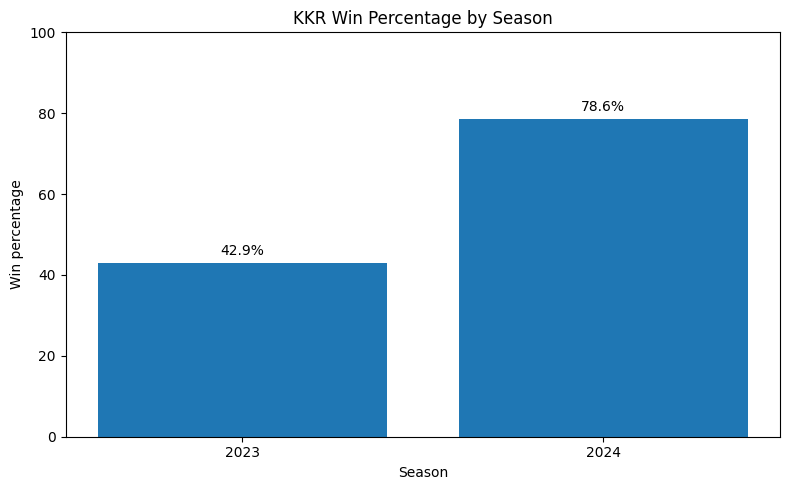

In [134]:
# ============================================================
# 9.3 Visualise KKR Win Percentage
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    outcome_summary["year"].astype(str),
    outcome_summary["win_pct"],
)

ax.set_title("KKR Win Percentage by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Win percentage")
ax.set_ylim(0, 100)

for position, value in enumerate(outcome_summary["win_pct"]):
    ax.text(
        position,
        value + 2,
        f"{value:.1f}%",
        ha="center",
    )

plt.tight_layout()
plt.show()

## 9.4 KKR Innings Score Distribution

Match outcomes alone do not explain how a team performs.

We compare KKR's innings scores across seasons using:
- Mean and median score.
- Standard deviation.
- Minimum and maximum score.
- Number of innings reaching 180 and 200 runs.

The median and standard deviation are included because unusually
high scores can influence the mean substantially.

Only matches with two represented innings are included in this
scorecard analysis.

In [135]:
# ============================================================
# 9.4 Construct KKR Innings Scores
# ============================================================

# Require both innings and both batting teams to be represented.
complete_match_ids = match_summary.loc[
    match_summary["represented_innings"].eq(2)
    & match_summary["represented_batting_teams"].eq(2),
    "p_match",
]

kkr_innings_scores = (
    df_analysis.loc[
        df_analysis["p_match"].isin(complete_match_ids)
        & df_analysis["team_bat"].eq(KKR)
    ]
    .groupby(["p_match", "year", "team_bat"], as_index=False)
    .agg(
        innings_score=("score", "sum"),
    )
)

print("KKR innings represented:", len(kkr_innings_scores))

display(kkr_innings_scores.head())

KKR innings represented: 28


,p_match,year,team_bat,innings_score
0,1359476,2023,Kolkata Knight Riders,146
1,1359483,2023,Kolkata Knight Riders,204
2,1359487,2023,Kolkata Knight Riders,207
3,1359493,2023,Kolkata Knight Riders,204
4,1359496,2023,Kolkata Knight Riders,185


In [136]:
# ============================================================
# 9.5 Summarise KKR Innings Scores
# ============================================================

score_summary = (
    kkr_innings_scores.groupby("year")
    .agg(
        innings=("innings_score", "count"),
        mean_score=("innings_score", "mean"),
        median_score=("innings_score", "median"),
        std_score=("innings_score", "std"),
        min_score=("innings_score", "min"),
        max_score=("innings_score", "max"),
        scores_180_plus=(
            "innings_score",
            lambda s: int(s.ge(180).sum()),
        ),
        scores_200_plus=(
            "innings_score",
            lambda s: int(s.ge(200).sum()),
        ),
    )
    .reset_index()
)

display(
    score_summary.style.format({
        "mean_score": "{:.2f}",
        "median_score": "{:.2f}",
        "std_score": "{:.2f}",
    })
)

,year,innings,mean_score,median_score,std_score,min_score,max_score,scores_180_plus,scores_200_plus
0,2023,14,175.86,180.50,25.16,127,207,7,4
1,2024,14,190.14,177.50,47.01,114,272,7,6


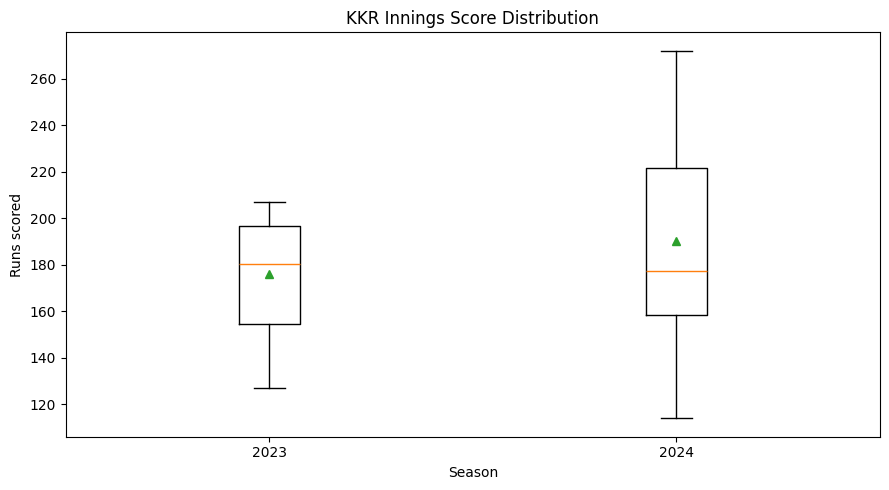

In [137]:
# ============================================================
# 9.6 Compare Innings Score Distributions
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

score_data = [
    kkr_innings_scores.loc[
        kkr_innings_scores["year"].eq(year),
        "innings_score",
    ].values
    for year in sorted(kkr_innings_scores["year"].unique())
]

score_labels = [
    str(year)
    for year in sorted(kkr_innings_scores["year"].unique())
]

ax.boxplot(
    score_data,
    tick_labels=score_labels,
    showmeans=True,
)

ax.set_title("KKR Innings Score Distribution")
ax.set_xlabel("Season")
ax.set_ylabel("Runs scored")

plt.tight_layout()
plt.show()

In [138]:
expected_score_stats = {
    2023: {
        "mean_score": 175.86,
        "median_score": 180.5,
        "max_score": 207,
    },
    2024: {
        "mean_score": 190.14,
        "median_score": 177.5,
        "max_score": 272,
    },
}

for year, expected in expected_score_stats.items():
    actual = score_summary.loc[
        score_summary["year"].eq(year)
    ].iloc[0]

    assert int(actual["innings"]) == 14
    assert np.isclose(actual["mean_score"], expected["mean_score"], atol=0.02)
    assert np.isclose(actual["median_score"], expected["median_score"], atol=0.01)
    assert int(actual["max_score"]) == expected["max_score"]

print("KKR innings-score validation passed.")

KKR innings-score validation passed.


## 9.7 Batting First Versus Chasing

The toss and innings order can influence match strategy.

We compare KKR's outcomes and scores when:
- Batting first.
- Chasing a target.

The analysis uses complete matches and identifies KKR's innings order
from the represented innings number.

These results are descriptive. The number of matches in each group is
small, and the 2024 sample includes knockout matches.

In [139]:
# ============================================================
# 9.7 Determine KKR's Batting Order
# ============================================================

kkr_team_innings = (
    df_analysis.loc[
        df_analysis["p_match"].isin(complete_match_ids)
        & (
            df_analysis["team_bat"].eq(KKR)
            | df_analysis["team_bowl"].eq(KKR)
        )
    ]
    .groupby(["p_match", "year", "inns", "team_bat"], as_index=False)
    .agg(
        innings_score=("score", "sum"),
    )
)

kkr_batting_order = (
    kkr_team_innings.loc[
        kkr_team_innings["team_bat"].eq(KKR)
    ]
    .copy()
)

kkr_batting_order["situation"] = np.where(
    kkr_batting_order["inns"].eq(1),
    "Batted first",
    "Chased",
)

# Attach match winners.
kkr_batting_order = kkr_batting_order.merge(
    kkr_matches[["p_match", "winner"]],
    on="p_match",
    how="left",
    validate="many_to_one",
)

kkr_batting_order["outcome"] = np.select(
    [
        kkr_batting_order["winner"].eq(KKR),
        kkr_batting_order["winner"].notna()
        & kkr_batting_order["winner"].ne(KKR)
        & kkr_batting_order["winner"].ne("-"),
    ],
    ["Win", "Loss"],
    default="Unclassified",
)

display(
    kkr_batting_order[
        ["p_match", "year", "inns", "situation", "innings_score", "winner", "outcome"]
    ].head(10)
)

,p_match,year,inns,situation,innings_score,winner,outcome
0,1359476,2023,2,Chased,146,Punjab Kings,Loss
1,1359483,2023,1,Batted first,204,Kolkata Knight Riders,Win
2,1359487,2023,2,Chased,207,Kolkata Knight Riders,Win
3,1359493,2023,2,Chased,204,Sunrisers Hyderabad,Loss
4,1359496,2023,1,Batted first,185,Mumbai Indians,Loss
5,1359502,2023,1,Batted first,127,Delhi Capitals,Loss
6,1359507,2023,2,Chased,186,Chennai Super Kings,Loss
7,1359510,2023,1,Batted first,200,Kolkata Knight Riders,Win
8,1359513,2023,1,Batted first,179,Gujarat Titans,Loss
9,1359521,2023,1,Batted first,171,Kolkata Knight Riders,Win


In [140]:
# ============================================================
# 9.8 Batting Order and Match Outcomes
# ============================================================

batting_order_summary = (
    kkr_batting_order.groupby(["year", "situation"])
    .agg(
        matches=("p_match", "nunique"),
        wins=("outcome", lambda s: int(s.eq("Win").sum())),
        losses=("outcome", lambda s: int(s.eq("Loss").sum())),
        mean_kkr_score=("innings_score", "mean"),
    )
    .reset_index()
)

batting_order_summary["win_pct"] = np.where(
    (batting_order_summary["wins"] + batting_order_summary["losses"]) > 0,
    100 * batting_order_summary["wins"]
    / (batting_order_summary["wins"] + batting_order_summary["losses"]),
    np.nan,
)

display(
    batting_order_summary.style.format({
        "mean_kkr_score": "{:.2f}",
        "win_pct": "{:.2f}%",
    })
)

,year,situation,matches,wins,losses,mean_kkr_score,win_pct
0,2023,Batted first,7,3,4,173.57,42.86%
1,2023,Chased,7,3,4,178.14,42.86%
2,2024,Batted first,9,6,3,208.89,66.67%
3,2024,Chased,5,5,0,156.40,100.00%


# 10. Phase-Wise KKR Performance Analysis

Cricket performance changes considerably across an innings.

The Powerplay provides opportunities for aggressive scoring but also
introduces wicket risk. The Middle Overs require a balance between
maintaining momentum and preserving wickets. The Death Overs provide
opportunities for acceleration, but scoring opportunities depend on
the number of balls remaining and the wickets in hand.

This section compares KKR's batting and bowling performance across
the Powerplay, Middle Overs, and Death Overs in 2023 and 2024.

We use scoring rates, strike rates, dot-ball percentages, boundary
frequencies, and bowling effectiveness to identify changes in
performance.

The results are descriptive and must be interpreted alongside
differences in match coverage and opportunities.

In [141]:
# ============================================================
# 10.1 KKR Batting Performance by Phase
# ============================================================

KKR = "Kolkata Knight Riders"

kkr_batting_phase = (
    df_analysis.loc[
        df_analysis["team_bat"].eq(KKR)
        & df_analysis["match_phase"].notna()
    ]
    .groupby(["year", "match_phase"])
    .agg(
        runs=("batruns", "sum"),
        balls_faced=("ballfaced", "sum"),
        dot_balls=("batting_dot", "sum"),
        boundary_balls=("boundary_ball", "sum"),
        boundary_runs=("boundary_runs", "sum"),
        matches=("p_match", "nunique"),
    )
    .reset_index()
)

kkr_batting_phase["strike_rate"] = np.where(
    kkr_batting_phase["balls_faced"] > 0,
    100 * kkr_batting_phase["runs"]
    / kkr_batting_phase["balls_faced"],
    np.nan,
)

kkr_batting_phase["runs_per_over"] = np.where(
    kkr_batting_phase["balls_faced"] > 0,
    6 * kkr_batting_phase["runs"]
    / kkr_batting_phase["balls_faced"],
    np.nan,
)

kkr_batting_phase["dot_ball_pct"] = np.where(
    kkr_batting_phase["balls_faced"] > 0,
    100 * kkr_batting_phase["dot_balls"]
    / kkr_batting_phase["balls_faced"],
    np.nan,
)

kkr_batting_phase["boundary_ball_pct"] = np.where(
    kkr_batting_phase["balls_faced"] > 0,
    100 * kkr_batting_phase["boundary_balls"]
    / kkr_batting_phase["balls_faced"],
    np.nan,
)

kkr_batting_phase["boundary_run_pct"] = np.where(
    kkr_batting_phase["runs"] > 0,
    100 * kkr_batting_phase["boundary_runs"]
    / kkr_batting_phase["runs"],
    np.nan,
)

phase_order = ["Powerplay", "Middle", "Death"]

kkr_batting_phase["match_phase"] = pd.Categorical(
    kkr_batting_phase["match_phase"],
    categories=phase_order,
    ordered=True,
)

kkr_batting_phase = kkr_batting_phase.sort_values(
    ["year", "match_phase"]
)

display(
    kkr_batting_phase.style.format({
        "strike_rate": "{:.2f}",
        "runs_per_over": "{:.2f}",
        "dot_ball_pct": "{:.2f}%",
        "boundary_ball_pct": "{:.2f}%",
        "boundary_run_pct": "{:.2f}%",
    })
)

,year,match_phase,runs,balls_faced,dot_balls,boundary_balls,boundary_runs,matches,strike_rate,runs_per_over,dot_ball_pct,boundary_ball_pct,boundary_run_pct
2,2023,Powerplay,651,507,264,109,494,14,128.40,7.70,52.07%,21.50%,75.88%
1,2023,Middle,1065,760,233,130,626,14,140.13,8.41,30.66%,17.11%,58.78%
0,2023,Death,622,390,146,88,438,14,159.49,9.57,37.44%,22.56%,70.42%
5,2024,Powerplay,849,507,231,153,702,14,167.46,10.05,45.56%,30.18%,82.69%
4,2024,Middle,1114,725,224,149,712,14,153.66,9.22,30.90%,20.55%,63.91%
3,2024,Death,518,275,83,77,384,12,188.36,11.30,30.18%,28.00%,74.13%


In [142]:
# Confirm that phase-level runs and balls reconcile with delivery-level data.
kkr_batting_source = df_analysis.loc[
    df_analysis["team_bat"].eq(KKR)
    & df_analysis["match_phase"].notna()
]

assert np.isclose(
    kkr_batting_source["batruns"].sum(),
    kkr_batting_phase["runs"].sum(),
)

assert np.isclose(
    kkr_batting_source["ballfaced"].sum(),
    kkr_batting_phase["balls_faced"].sum(),
)

assert set(kkr_batting_phase["match_phase"].astype(str)) == {
    "Powerplay", "Middle", "Death"
}

print("KKR phase-wise batting validation passed.")

KKR phase-wise batting validation passed.


### 10.2 Batting Scoring Rates

Scoring rate is calculated as runs scored off the bat per six
balls faced:

    Runs per over = (Runs scored off the bat / Balls faced) × 6

This allows us to compare KKR's scoring tempo across phases.

It is not the same as the official innings run rate, which uses
the appropriate legal-delivery denominator and includes runs
scored from extras.

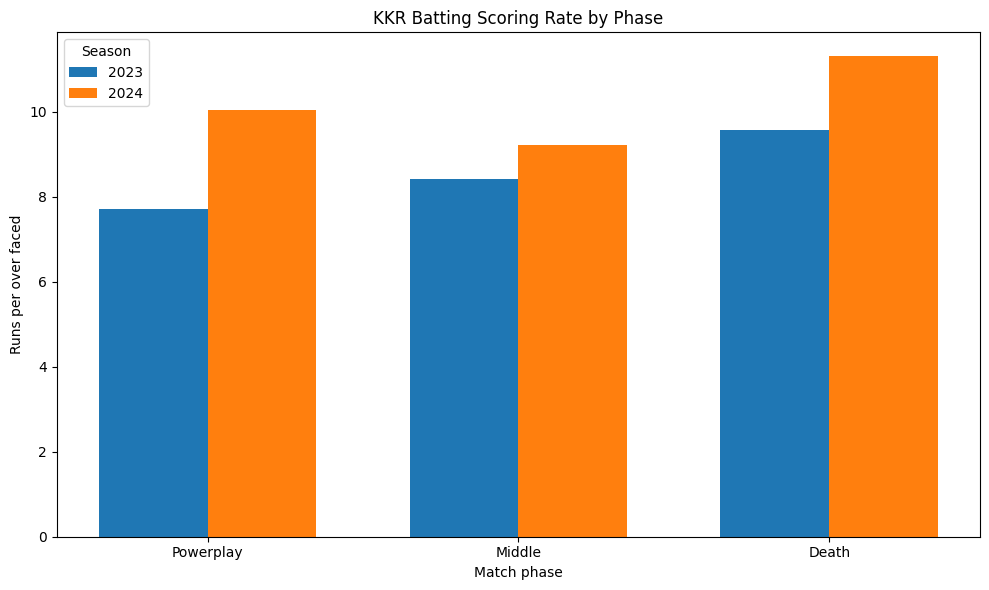

In [143]:
# ============================================================
# 10.2 Visualise KKR Batting Scoring Rates
# ============================================================

plot_data = kkr_batting_phase.copy()
plot_data["match_phase"] = plot_data["match_phase"].astype(str)

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(phase_order))
width = 0.35

for index, year in enumerate([2023, 2024]):
    year_data = (
        plot_data.loc[plot_data["year"].eq(year)]
        .set_index("match_phase")
        .reindex(phase_order)
    )

    ax.bar(
        x + (index - 0.5) * width,
        year_data["runs_per_over"],
        width,
        label=str(year),
    )

ax.set_title("KKR Batting Scoring Rate by Phase")
ax.set_xlabel("Match phase")
ax.set_ylabel("Runs per over faced")
ax.set_xticks(x)
ax.set_xticklabels(phase_order)
ax.legend(title="Season")

plt.tight_layout()
plt.show()

In [144]:
expected_batting_rates = {
    (2023, "Powerplay"): 7.70,
    (2024, "Powerplay"): 10.05,
    (2023, "Middle"): 8.41,
    (2024, "Middle"): 9.22,
    (2023, "Death"): 9.57,
    (2024, "Death"): 11.30,
}

for (year, phase), expected_rate in expected_batting_rates.items():
    actual_rate = kkr_batting_phase.loc[
        kkr_batting_phase["year"].eq(year)
        & kkr_batting_phase["match_phase"].astype(str).eq(phase),
        "runs_per_over",
    ].iloc[0]

    assert np.isclose(actual_rate, expected_rate, atol=0.02), (
        f"Unexpected scoring rate for {year}, {phase}: {actual_rate}"
    )

print("KKR batting scoring-rate validation passed.")

KKR batting scoring-rate validation passed.


## KKR Bowling Effectiveness by Phase: 2023 vs 2024

This analysis compares KKR's aggregate bowling effectiveness across the
Powerplay (overs 1–6), Middle Overs (7–15), and Death Overs (16–20).

Two metrics are evaluated:

- **Economy rate:** Total runs conceded per six legal balls.
- **Wicket-taking rate:** Bowler-credited wickets per 20 legal overs.

Grouped bar charts compare the two seasons within each phase.

Lower economy indicates better run prevention, while a higher wicket-taking
rate indicates greater wicket-taking frequency. These metrics should be
interpreted together because bowling roles and phase-specific workloads differ.

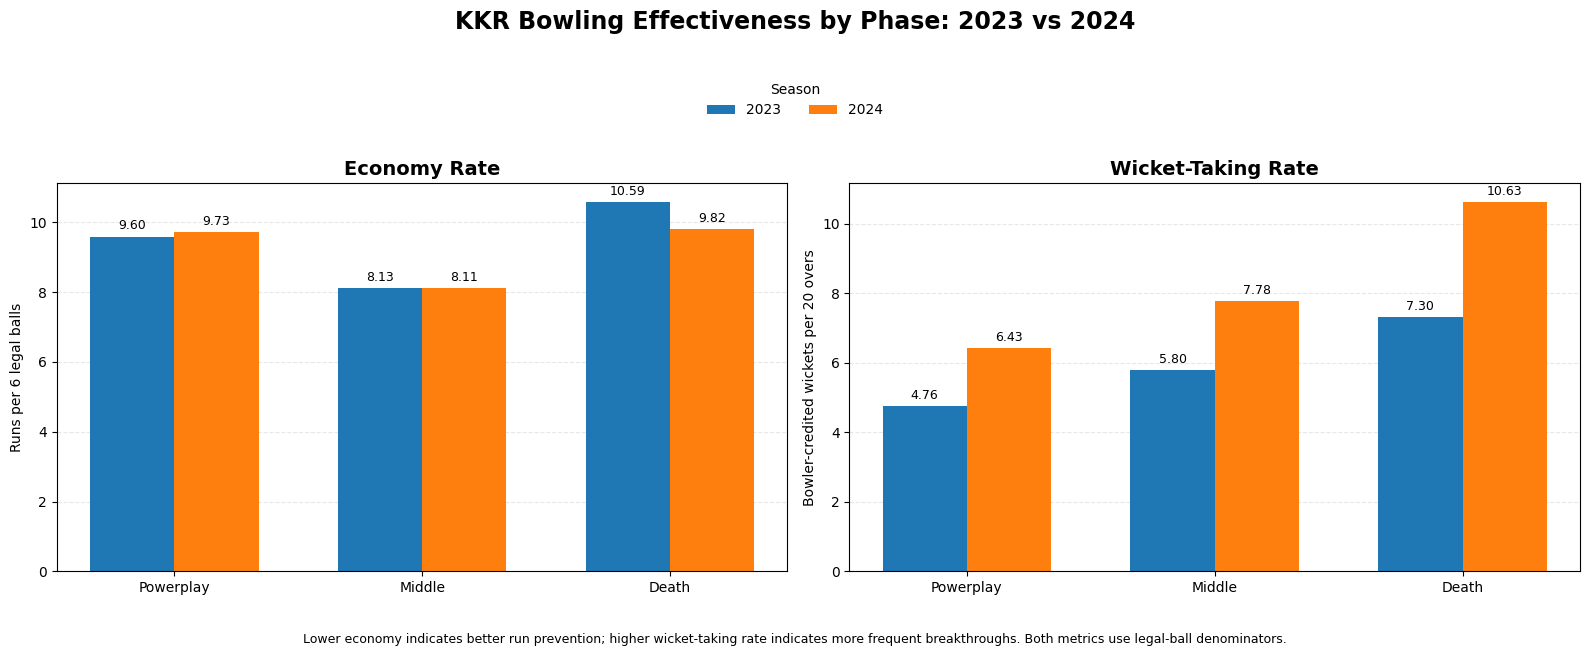

In [185]:
# ============================================================
# KKR BOWLING EFFECTIVENESS BY PHASE — COMBINED FIGURE
# 2023 vs 2024
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEASON_COLORS = {
    2023: "tab:blue",
    2024: "tab:orange",
}

PHASE_ORDER = [
    "Powerplay",
    "Middle",
    "Death",
]

bar_width = 0.34
x = np.arange(len(PHASE_ORDER))

# ------------------------------------------------------------
# 2. Prepare data
# ------------------------------------------------------------

data_2023 = (
    kkr_phase_bowling.loc[
        kkr_phase_bowling["year"].eq(2023)
    ]
    .set_index("match_phase")
    .reindex(PHASE_ORDER)
)

data_2024 = (
    kkr_phase_bowling.loc[
        kkr_phase_bowling["year"].eq(2024)
    ]
    .set_index("match_phase")
    .reindex(PHASE_ORDER)
)

# ------------------------------------------------------------
# 3. Create one figure with two panels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 6),
)

ax_economy, ax_wickets = axes

# ============================================================
# PANEL 1: ECONOMY RATE
# ============================================================

bars_2023_economy = ax_economy.bar(
    x - bar_width / 2,
    data_2023["economy_rate"],
    width=bar_width,
    color=SEASON_COLORS[2023],
    label="2023",
)

bars_2024_economy = ax_economy.bar(
    x + bar_width / 2,
    data_2024["economy_rate"],
    width=bar_width,
    color=SEASON_COLORS[2024],
    label="2024",
)

ax_economy.bar_label(
    bars_2023_economy,
    fmt="%.2f",
    padding=3,
    fontsize=9,
)

ax_economy.bar_label(
    bars_2024_economy,
    fmt="%.2f",
    padding=3,
    fontsize=9,
)

ax_economy.set_title(
    "Economy Rate",
    fontsize=14,
    fontweight="bold",
)

ax_economy.set_ylabel(
    "Runs per 6 legal balls"
)

ax_economy.set_xticks(x)
ax_economy.set_xticklabels(PHASE_ORDER)

ax_economy.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

ax_economy.set_axisbelow(True)

# ============================================================
# PANEL 2: WICKET-TAKING RATE
# ============================================================

bars_2023_wickets = ax_wickets.bar(
    x - bar_width / 2,
    data_2023["wickets_per_20_overs"],
    width=bar_width,
    color=SEASON_COLORS[2023],
    label="2023",
)

bars_2024_wickets = ax_wickets.bar(
    x + bar_width / 2,
    data_2024["wickets_per_20_overs"],
    width=bar_width,
    color=SEASON_COLORS[2024],
    label="2024",
)

ax_wickets.bar_label(
    bars_2023_wickets,
    fmt="%.2f",
    padding=3,
    fontsize=9,
)

ax_wickets.bar_label(
    bars_2024_wickets,
    fmt="%.2f",
    padding=3,
    fontsize=9,
)

ax_wickets.set_title(
    "Wicket-Taking Rate",
    fontsize=14,
    fontweight="bold",
)

ax_wickets.set_ylabel(
    "Bowler-credited wickets per 20 overs"
)

ax_wickets.set_xticks(x)
ax_wickets.set_xticklabels(PHASE_ORDER)

ax_wickets.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

ax_wickets.set_axisbelow(True)

# ------------------------------------------------------------
# 4. Shared legend
# ------------------------------------------------------------

handles, labels = ax_economy.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Season",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=2,
    frameon=False,
)

# ------------------------------------------------------------
# 5. Overall title and layout
# ------------------------------------------------------------

fig.suptitle(
    "KKR Bowling Effectiveness by Phase: 2023 vs 2024",
    fontsize=17,
    fontweight="bold",
    y=1.04,
)

fig.text(
    0.5,
    -0.015,
    (
        "Lower economy indicates better run prevention; "
        "higher wicket-taking rate indicates more frequent breakthroughs. "
        "Both metrics use legal-ball denominators."
    ),
    ha="center",
    fontsize=9,
)

plt.tight_layout(
    rect=[0, 0.04, 1, 0.88]
)

plt.show()

### 10.5 Phase-Wise Performance: Initial Findings

The phase-level results provide a more detailed explanation of KKR's
performance than win percentage alone.

**Batting**
- The Powerplay showed the largest improvement in scoring tempo.
- The Middle Overs also improved, although less dramatically.
- Death Overs scoring increased, indicating a higher scoring tempo
  in the final phase.

**Bowling**
- Powerplay economy increased slightly despite more wickets and dots.
- Middle Overs economy remained broadly stable while wicket output
  increased.
- Death Overs economy improved, and bowler-credited wicket output
  increased despite fewer legal balls bowled in the phase.

These are descriptive comparisons. They do not establish that any
single tactical change caused KKR's improved match results.

## 11. Performance Indicators Associated with Match Outcomes

This section investigates how KKR's batting and bowling performance
differed between wins and losses.

We consider:
- KKR's final score.
- Batting scoring rate.
- Opponent score.
- Bowling economy.
- Bowling dot-ball percentage.
- Bowler-credited wickets.
- Boundary runs scored per over faced.

The analysis excludes the incomplete match and the two 2024 knockout
matches. This produces a more comparable sample of complete league
matches across the two seasons.

These comparisons are descriptive. They identify associations
between performance indicators and outcomes; they do not establish
causation.

In [148]:
# Exclude the two 2024 KKR knockout matches from the league-stage analysis.
KNOCKOUT_MATCH_IDS = {1426309, 1426312}

# Identify matches in which KKR participated, either batting or bowling.
kkr_match_ids = set(
    df_analysis.loc[
        df_analysis["team_bat"].eq(KKR)
        | df_analysis["team_bowl"].eq(KKR),
        "p_match",
    ].dropna().unique()
)

# Retain only KKR matches with both innings and both batting teams represented,
# excluding the two knockout matches.
complete_league_match_ids = set(
    match_summary.loc[
        match_summary["p_match"].isin(kkr_match_ids)
        & match_summary["represented_innings"].eq(2)
        & match_summary["represented_batting_teams"].eq(2)
        & ~match_summary["p_match"].isin(KNOCKOUT_MATCH_IDS),
        "p_match",
    ]
)

league_matches = match_summary.loc[
    match_summary["p_match"].isin(complete_league_match_ids)
].copy()

print("Complete KKR league matches:", len(league_matches))

display(
    league_matches.groupby("year")
    .agg(matches=("p_match", "nunique"))
    .reset_index()
)

# Expected: 14 KKR league matches in 2023 and 12 in 2024.
assert len(league_matches) == 26
assert (
    league_matches.groupby("year")["p_match"]
    .nunique()
    .to_dict()
    == {2023: 14, 2024: 12}
)

print("Validation passed.")

Complete KKR league matches: 26


,year,matches
0,2023,14
1,2024,12


Validation passed.


In [149]:
# ============================================================
# 11.2 Build KKR Match-Level Performance Indicators
# ============================================================

league_deliveries = df_analysis.loc[
    df_analysis["p_match"].isin(complete_league_match_ids)
].copy()

# KKR batting indicators.
kkr_batting_match = (
    league_deliveries.loc[
        league_deliveries["team_bat"].eq(KKR)
    ]
    .groupby(["p_match", "year"], as_index=False)
    .agg(
        kkr_score=("score", "sum"),
        kkr_batting_runs=("batruns", "sum"),
        kkr_balls_faced=("ballfaced", "sum"),
        kkr_batting_dots=("batting_dot", "sum"),
        kkr_boundary_runs=("boundary_runs", "sum"),
    )
)

kkr_batting_match["kkr_batting_runs_per_over"] = np.where(
    kkr_batting_match["kkr_balls_faced"] > 0,
    6 * kkr_batting_match["kkr_batting_runs"]
    / kkr_batting_match["kkr_balls_faced"],
    np.nan,
)

kkr_batting_match["kkr_boundary_runs_per_over"] = np.where(
    kkr_batting_match["kkr_balls_faced"] > 0,
    6 * kkr_batting_match["kkr_boundary_runs"]
    / kkr_batting_match["kkr_balls_faced"],
    np.nan,
)

# Opponent batting indicators.
opponent_batting_match = (
    league_deliveries.loc[
        ~league_deliveries["team_bat"].eq(KKR)
    ]
    .groupby(["p_match", "year"], as_index=False)
    .agg(
        opponent_score=("score", "sum"),
    )
)

# Runs conceded by KKR's bowlers, using the source bowlruns field.
kkr_bowling_match = (
    league_deliveries.loc[
        league_deliveries["team_bowl"].eq(KKR)
    ]
    .groupby(["p_match", "year"], as_index=False)
    .agg(
        kkr_runs_conceded=("bowlruns", "sum"),
        kkr_legal_balls=("legal_delivery", "sum"),
        kkr_bowling_dots=("bowling_dot", "sum"),
        kkr_bowler_wickets=("bowler_credited_wicket", "sum"),
    )
)

kkr_bowling_match["kkr_bowling_economy"] = np.where(
    kkr_bowling_match["kkr_legal_balls"] > 0,
    6 * kkr_bowling_match["kkr_runs_conceded"]
    / kkr_bowling_match["kkr_legal_balls"],
    np.nan,
)

kkr_bowling_match["kkr_bowling_dot_pct"] = np.where(
    kkr_bowling_match["kkr_legal_balls"] > 0,
    100 * kkr_bowling_match["kkr_bowling_dots"]
    / kkr_bowling_match["kkr_legal_balls"],
    np.nan,
)

# Combine the match-level indicators.
kkr_match_analysis = (
    kkr_batting_match
    .merge(
        opponent_batting_match,
        on=["p_match", "year"],
        how="inner",
        validate="one_to_one",
    )
    .merge(
        kkr_bowling_match,
        on=["p_match", "year"],
        how="inner",
        validate="one_to_one",
    )
    .merge(
        league_matches[["p_match", "winner"]],
        on="p_match",
        how="left",
        validate="one_to_one",
    )
)

kkr_match_analysis["outcome"] = np.where(
    kkr_match_analysis["winner"].eq(KKR),
    "Win",
    "Loss",
)

# Determine whether KKR batted first or chased.
kkr_innings_order = (
    league_deliveries.loc[
        league_deliveries["team_bat"].eq(KKR)
    ]
    .groupby("p_match")["inns"]
    .min()
)

kkr_match_analysis["kkr_innings"] = (
    kkr_match_analysis["p_match"].map(kkr_innings_order)
)

kkr_match_analysis["situation"] = np.where(
    kkr_match_analysis["kkr_innings"].eq(1),
    "Batted first",
    "Chased",
)

print("Match-level analysis shape:", kkr_match_analysis.shape)

display(kkr_match_analysis.head())

Match-level analysis shape: (26, 20)


,p_match,year,kkr_score,kkr_batting_runs,kkr_balls_faced,kkr_batting_dots,kkr_boundary_runs,kkr_batting_runs_per_over,kkr_boundary_runs_per_over,opponent_score,kkr_runs_conceded,kkr_legal_balls,kkr_bowling_dots,kkr_bowler_wickets,kkr_bowling_economy,kkr_bowling_dot_pct,winner,outcome,kkr_innings,situation
0,1359476,2023,146,140,98,37,94,8.571429,5.755102,191,190,120,42,5,9.500000,35.000000,Punjab Kings,Loss,2,Chased
1,1359483,2023,204,181,123,49,126,8.829268,6.146341,123,118,106,48,10,6.679245,45.283019,Kolkata Knight Riders,Win,1,Batted first
2,1359487,2023,207,203,120,43,150,10.150000,7.500000,204,199,120,29,4,9.950000,24.166667,Kolkata Knight Riders,Win,2,Chased
3,1359493,2023,204,195,122,44,138,9.590164,6.786885,228,228,120,30,4,11.400000,25.000000,Sunrisers Hyderabad,Loss,2,Chased
4,1359496,2023,185,171,120,44,108,8.550000,5.400000,186,186,106,38,5,10.528302,35.849057,Mumbai Indians,Loss,1,Batted first


In [150]:
assert kkr_match_analysis["p_match"].is_unique
assert len(kkr_match_analysis) == 26
assert set(kkr_match_analysis["outcome"]) == {"Win", "Loss"}

print("Match-level performance indicators validated.")

Match-level performance indicators validated.


### 11.3 What Differentiated Wins from Losses?

We compare average performance indicators across wins and losses,
separately by season and batting order.

The sample sizes are small, so differences should be interpreted as
descriptive patterns rather than statistically established effects.

In [151]:
# ============================================================
# 11.3 Summarise Performance Indicators by Outcome
# ============================================================

performance_metrics = [
    "kkr_score",
    "kkr_batting_runs_per_over",
    "opponent_score",
    "kkr_bowling_economy",
    "kkr_bowling_dot_pct",
    "kkr_bowler_wickets",
    "kkr_boundary_runs_per_over",
]

outcome_performance = (
    kkr_match_analysis
    .groupby(["year", "situation", "outcome"])
    .agg(
        matches=("p_match", "nunique"),
        **{
            f"mean_{metric}": (metric, "mean")
            for metric in performance_metrics
        },
    )
    .reset_index()
)

display(outcome_performance)

,year,situation,outcome,matches,mean_kkr_score,mean_kkr_batting_runs_per_over,mean_opponent_score,mean_kkr_bowling_economy,mean_kkr_bowling_dot_pct,mean_kkr_bowler_wickets,mean_kkr_boundary_runs_per_over
0,2023,Batted first,Loss,4,160.000000,7.600000,161.250000,9.487696,34.673652,3.500000,4.800000
1,2023,Batted first,Win,3,191.666667,8.831887,156.000000,7.809748,34.538784,8.333333,5.954791
2,2023,Chased,Loss,4,177.750000,8.815398,207.500000,10.300000,31.875000,5.250000,6.110497
3,2023,Chased,Win,3,178.666667,8.760714,175.666667,8.583333,32.777778,5.666667,5.790476
4,2024,Batted first,Loss,3,207.000000,9.498627,209.000000,10.982165,31.133199,3.666667,6.854424
5,2024,Batted first,Win,6,209.833333,10.134114,167.333333,8.955654,39.699508,8.833333,7.309930
6,2024,Chased,Win,3,168.000000,9.332737,165.333333,8.183333,38.611111,7.000000,6.604230


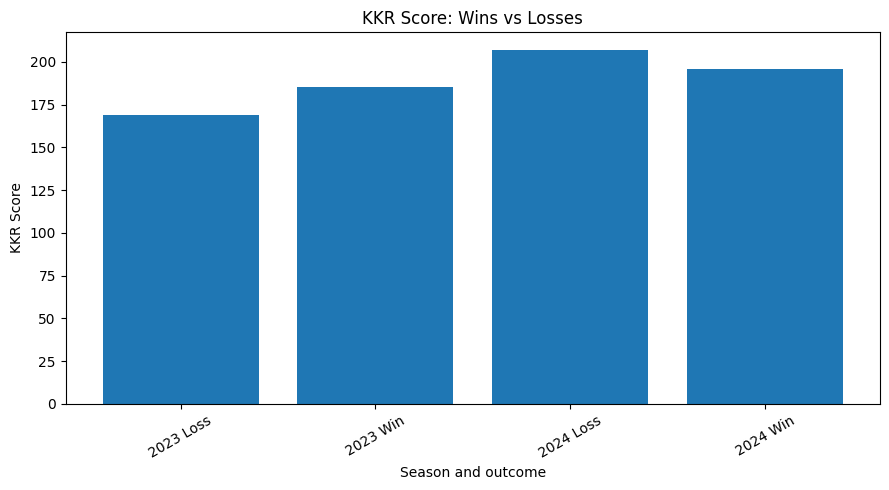

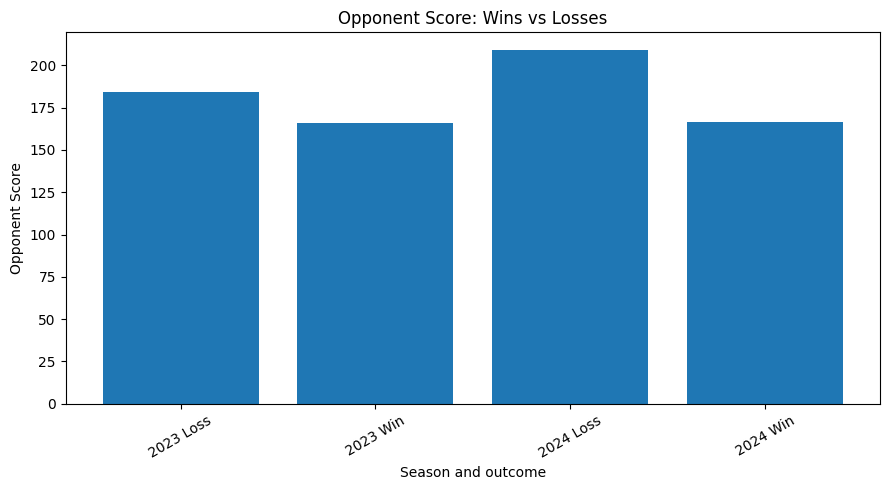

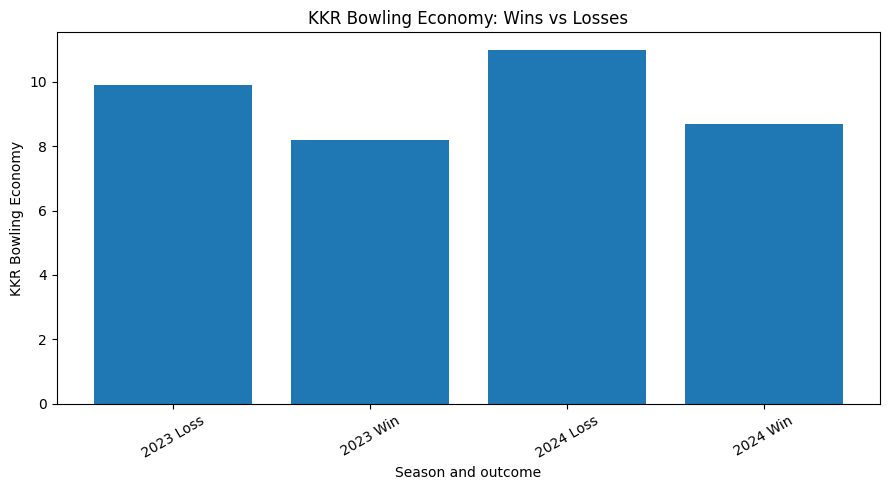

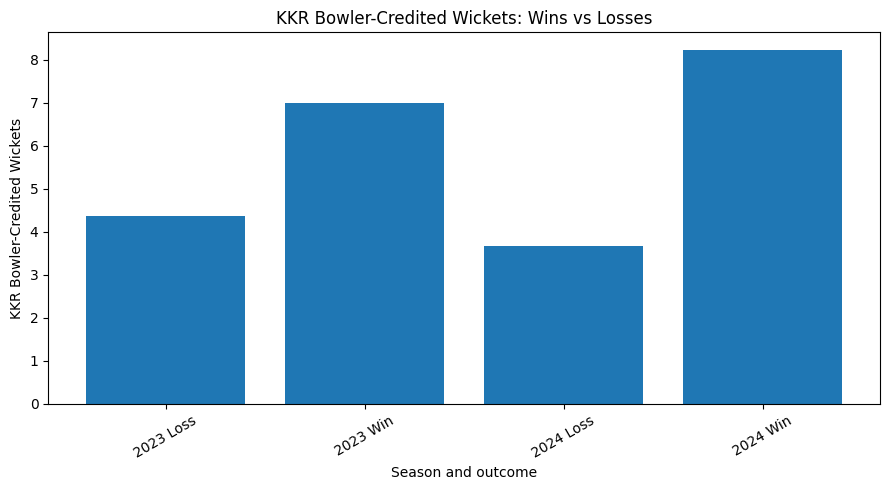

In [152]:
# ============================================================
# 11.4 Compare Selected Indicators Across Wins and Losses
# ============================================================

metrics_to_plot = [
    ("kkr_score", "KKR Score"),
    ("opponent_score", "Opponent Score"),
    ("kkr_bowling_economy", "KKR Bowling Economy"),
    ("kkr_bowler_wickets", "KKR Bowler-Credited Wickets"),
]

for metric, title in metrics_to_plot:
    plot_data = (
        kkr_match_analysis
        .groupby(["year", "outcome"])[metric]
        .mean()
        .reset_index()
    )

    plot_data["group"] = (
        plot_data["year"].astype(str)
        + " "
        + plot_data["outcome"]
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(
        plot_data["group"],
        plot_data[metric],
    )

    ax.set_title(f"{title}: Wins vs Losses")
    ax.set_xlabel("Season and outcome")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()

### 11.5 Interpretation and Limitations

The outcome analysis should be interpreted in conjunction with the
phase-level findings.

Questions to consider include:

- Were KKR's wins associated with stronger batting output?
- Did lower opponent scoring or higher wicket-taking output
  accompany successful bowling performances?
- Were the patterns similar when batting first and when chasing?
- Did the patterns differ between 2023 and 2024?

The analysis does not establish that any indicator independently
caused a win. Match conditions, opposition quality, wickets in hand,
target size, and other contextual variables can influence the
observed relationships.

The small sample sizes also limit the reliability of comparisons
between individual groups.

## 12. Player Scouting and Recruitment Intelligence

### 12.1 Objective

This section evaluates IPL player performance during the 2023 and
2024 seasons to identify potential recruitment opportunities for
Kolkata Knight Riders (KKR).

The objective is to identify players who demonstrate the performance
characteristics required for specific batting and bowling roles, rather
than selecting candidates using aggregate statistics alone.

### Scouting dimensions

Players will be evaluated across five dimensions:

1. Production: total runs, wickets, and other measurable contributions.
2. Efficiency: strike rate, dot-ball percentage, economy, and other
   role-appropriate efficiency measures.
3. Role effectiveness: performance during the Powerplay, Middle overs,
   and Death overs.
4. Evidence strength: balls faced, legal balls bowled, wickets, and
   other indicators of statistical reliability.
5. Consistency and development: changes in performance between seasons
   where sufficient observations exist.

### Recruitment roles

Batting:
- Top-order run scorer
- Middle-order batter
- Death-overs aggressor

Bowling:
- Powerplay wicket-taker
- Middle-overs wicket-taking and control option
- Death-overs specialist

### Methodological principles

- Compare players performing similar roles.
- Retain season and workload information alongside performance metrics.
- Apply minimum-opportunity thresholds before creating shortlists.
- Do not interpret a small sample as conclusive evidence of ability.
- Distinguish observed performance from inferred recruitment suitability.
- Treat this dataset as evidence about IPL 2023–2024, not as a complete
  assessment of current player availability, price, fitness, or future
  performance.
- Document data-quality limitations, including the identified
  inconsistencies in the source bowling-runs field.

The output will be a role-specific scouting shortlist, supported by
comparative tables, visualisations, and explicit selection criteria.

### 12.2 Scouting Data Preparation

The existing player-season and player-phase datasets form the foundation
of the scouting analysis.

The preparation stage will:

1. Verify the required fields in each dataset.
2. Standardise player names and numeric fields where necessary.
3. Remove records that cannot support the relevant calculation.
4. Retain opportunity measures for all shortlisted players.
5. Create separate candidate pools for batting and bowling roles.

The scouting analysis will not silently impute missing performance
statistics. Missing values will remain missing unless a documented
transformation provides a defensible alternative.

In [153]:
# Step 37.2: Validate scouting datasets.

scouting_datasets = {
    "player_season_batting": player_season_batting,
    "player_season_bowling": player_season_bowling,
    "player_season_phase_batting": player_season_phase_batting,
    "player_season_phase_bowling": player_season_phase_bowling,
}

for dataset_name, dataset in scouting_datasets.items():
    print(f"\n{dataset_name}")
    print(f"Shape: {dataset.shape}")
    print(f"Duplicate rows: {dataset.duplicated().sum()}")
    print(f"Missing values: {dataset.isna().sum().sum()}")

    display(dataset.head(3))


player_season_batting
Shape: (347, 13)
Duplicate rows: 0
Missing values: 0


,year,p_bat,bat,runs,balls_faced,dismissals,fours,sixes,dot_balls,boundary_balls,strike_rate,dot_ball_pct,boundary_ball_pct
0,2023,8917,Moeen Ali,124,91,92,12,6,37,18,136.263736,40.659341,19.780220
1,2023,26421,Ravichandran Ashwin,67,51,55,5,3,19,8,131.372549,37.254902,15.686275
2,2023,28081,MS Dhoni,104,57,63,3,10,16,13,182.456140,28.070175,22.807018



player_season_bowling
Shape: (273, 17)
Duplicate rows: 0
Missing values: 0


,year,p_bowl,bowl,runs_conceded,legal_balls,dot_balls,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,wide_noball_extras_conceded,extras_per_20_overs
0,2023,8917,Moeen Ali,195,156,54,9,20,1,0,26.0,7.500000,34.615385,5.769231,12.820513,1,0.769231
1,2023,26421,Ravichandran Ashwin,368,294,88,14,34,16,0,49.0,7.510204,29.931973,4.761905,11.564626,16,6.530612
2,2023,30288,Karn Sharma,223,129,37,10,29,3,0,21.5,10.372093,28.682171,7.751938,22.480620,3,2.790698



player_season_phase_batting
Shape: (733, 13)
Duplicate rows: 0
Missing values: 40


,year,p_bat,bat,match_phase,runs,balls_faced,dot_balls,boundary_balls,boundary_runs,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_run_pct
0,2023,8917,Moeen Ali,Death,39,24,7,5,26,162.500000,29.166667,20.833333,66.666667
1,2023,8917,Moeen Ali,Middle,62,50,19,8,36,124.000000,38.000000,16.000000,58.064516
2,2023,8917,Moeen Ali,Powerplay,23,17,11,5,22,135.294118,64.705882,29.411765,95.652174



player_season_phase_bowling
Shape: (672, 18)
Duplicate rows: 0
Missing values: 0


,year,p_bowl,bowl,match_phase,runs_conceded,legal_balls,dot_balls,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,wide_noball_extras_conceded,extras_per_20_overs
0,2023,8917,Moeen Ali,Death,3,6,3,1,0,0,0,1.0,3.000000,50.000000,16.666667,0.000000,0,0.000000
1,2023,8917,Moeen Ali,Middle,182,138,45,6,20,1,0,23.0,7.913043,32.608696,4.347826,14.492754,1,0.869565
2,2023,8917,Moeen Ali,Powerplay,10,12,6,2,0,0,0,2.0,5.000000,50.000000,16.666667,0.000000,0,0.000000


### 12.3 Batting Scouting

Batting candidates will be assessed using both production and efficiency.

#### Core metrics

- Runs: total runs scored off the bat.
- Balls faced: batting opportunity.
- Strike rate: runs scored per 100 balls faced.
- Dot-ball percentage: proportion of batting opportunities that produce
  zero runs off the bat.
- Boundary runs: runs scored from fours and sixes.
- Boundary runs per over: boundary runs normalised to six balls faced.

#### Candidate pools

1. Overall batting candidates.
2. Top-order candidates.
3. Middle-order candidates.
4. Death-overs candidates.

The death-overs pool will use deliveries from overs 16–20.

A minimum workload threshold will be applied separately to each pool.
The threshold is a screening rule, not a universal definition of player
quality.

Players will be compared within their relevant roles, and their
opportunity measures will be displayed alongside their performance.

In [154]:
# Step 38.2: Prepare overall and phase-specific batting scouting tables.

batting_scouting = player_season_batting.copy()

batting_scouting["strike_rate"] = (
    100
    * batting_scouting["runs"]
    / batting_scouting["balls_faced"].replace(0, np.nan)
)

batting_scouting["dot_ball_pct"] = (
    100
    * batting_scouting["dot_balls"]
    / batting_scouting["balls_faced"].replace(0, np.nan)
)

batting_scouting["boundary_runs"] = (
    4 * batting_scouting["fours"]
    + 6 * batting_scouting["sixes"]
)

batting_scouting["boundary_runs_per_over"] = (
    6
    * batting_scouting["boundary_runs"]
    / batting_scouting["balls_faced"].replace(0, np.nan)
)

phase_batting_scouting = player_season_phase_batting.copy()

phase_batting_scouting["strike_rate"] = (
    100
    * phase_batting_scouting["runs"]
    / phase_batting_scouting["balls_faced"].replace(0, np.nan)
)

phase_batting_scouting["dot_ball_pct"] = (
    100
    * phase_batting_scouting["dot_balls"]
    / phase_batting_scouting["balls_faced"].replace(0, np.nan)
)

phase_batting_scouting["boundary_runs_per_over"] = (
    6
    * phase_batting_scouting["boundary_runs"]
    / phase_batting_scouting["balls_faced"].replace(0, np.nan)
)

assert batting_scouting["strike_rate"].notna().any()
assert phase_batting_scouting["strike_rate"].notna().any()

print("Overall batting scouting dataset:", batting_scouting.shape)
print("Phase batting scouting dataset:", phase_batting_scouting.shape)

display(batting_scouting.head())
display(phase_batting_scouting.head())

Overall batting scouting dataset: (347, 15)
Phase batting scouting dataset: (733, 14)


,year,p_bat,bat,runs,balls_faced,dismissals,fours,sixes,dot_balls,boundary_balls,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_runs,boundary_runs_per_over
0,2023,8917,Moeen Ali,124,91,92,12,6,37,18,136.263736,40.659341,19.780220,84,5.538462
1,2023,26421,Ravichandran Ashwin,67,51,55,5,3,19,8,131.372549,37.254902,15.686275,38,4.470588
2,2023,28081,MS Dhoni,104,57,63,3,10,16,13,182.456140,28.070175,22.807018,72,7.578947
3,2023,28235,Shikhar Dhawan,373,261,274,49,12,108,61,142.911877,41.379310,23.371648,268,6.160920
4,2023,30045,Dinesh Karthik,140,104,105,13,5,35,18,134.615385,33.653846,17.307692,82,4.730769


,year,p_bat,bat,match_phase,runs,balls_faced,dot_balls,boundary_balls,boundary_runs,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_run_pct,boundary_runs_per_over
0,2023,8917,Moeen Ali,Death,39,24,7,5,26,162.500000,29.166667,20.833333,66.666667,6.500000
1,2023,8917,Moeen Ali,Middle,62,50,19,8,36,124.000000,38.000000,16.000000,58.064516,4.320000
2,2023,8917,Moeen Ali,Powerplay,23,17,11,5,22,135.294118,64.705882,29.411765,95.652174,7.764706
3,2023,26421,Ravichandran Ashwin,Death,35,19,3,5,22,184.210526,15.789474,26.315789,62.857143,6.947368
4,2023,26421,Ravichandran Ashwin,Middle,32,28,12,3,16,114.285714,42.857143,10.714286,50.000000,3.428571


### 12.4 Batting Candidate Selection

The screening thresholds are:

- Overall batting: at least 150 balls faced in a season.
- Phase-specific batting: at least 60 balls faced in that phase in a season.

The higher phase threshold reduces the risk that a short burst of scoring is
mistaken for a reliable role profile. Candidates still receive an evidence flag
based on workload and whether they are observed in both seasons.

Role rankings combine production, scoring speed, dot-ball avoidance, workload,
and cross-season evidence. They are screening scores, not estimates of player
value or future performance.


In [155]:
# Step 38.4: Create batting candidate pools with stronger phase evidence.

MIN_OVERALL_BALLS = 150
MIN_PHASE_BALLS = 60

overall_batting_candidates = batting_scouting.loc[
    batting_scouting["balls_faced"].ge(MIN_OVERALL_BALLS)
].copy()
phase_batting_candidates = phase_batting_scouting.loc[
    phase_batting_scouting["balls_faced"].ge(MIN_PHASE_BALLS)
].copy()

print("Overall batting candidates:", len(overall_batting_candidates))
print("Phase-specific batting candidates (>= 60 balls):", len(phase_batting_candidates))

display(
    overall_batting_candidates.sort_values(["strike_rate", "runs"], ascending=[False, False])[
        ["year", "bat", "runs", "balls_faced", "strike_rate", "dot_ball_pct", "boundary_runs", "boundary_runs_per_over"]
    ].head(20)
)

for phase in ["Powerplay", "Middle", "Death"]:
    print(f"\n{phase}-overs batting candidates")
    display(
        phase_batting_candidates.loc[phase_batting_candidates["match_phase"].eq(phase)]
        .sort_values(["strike_rate", "runs"], ascending=[False, False])[
            ["year", "bat", "match_phase", "runs", "balls_faced", "strike_rate", "dot_ball_pct", "boundary_runs_per_over"]
        ].head(15)
    )


Overall batting candidates: 94
Phase-specific batting candidates (>= 60 balls): 200


,year,bat,runs,balls_faced,strike_rate,dot_ball_pct,boundary_runs,boundary_runs_per_over
296,2024,Abhishek Sharma,484,237,204.219409,33.755274,396,10.025316
240,2024,Travis Head,567,296,191.554054,31.081081,448,9.081081
247,2024,Tristan Stubbs,378,198,190.909091,21.212121,252,7.636364
182,2024,Dinesh Karthik,326,174,187.356322,28.735632,240,8.275862
40,2023,Glenn Maxwell,400,218,183.486239,33.027523,302,8.311927
257,2024,Phil Salt,435,239,182.008368,36.401674,344,8.635983
65,2023,Suryakumar Yadav,605,334,181.137725,27.544910,428,7.688623
189,2024,Sunil Narine,488,270,180.740741,40.370370,398,8.844444
250,2024,Nicholas Pooran,499,280,178.214286,29.285714,356,7.628571
277,2024,Rajat Patidar,395,223,177.130045,30.941704,282,7.587444



Powerplay-overs batting candidates


,year,bat,match_phase,runs,balls_faced,strike_rate,dot_ball_pct,boundary_runs_per_over
688,2024,Jake Fraser-McGurk,Powerplay,266,106,250.943396,36.792453,14.150943
53,2023,Ajinkya Rahane,Powerplay,125,60,208.333333,23.333333,9.000000
518,2024,Travis Head,Powerplay,402,193,208.290155,33.160622,10.569948
632,2024,Abhishek Sharma,Powerplay,343,169,202.958580,34.911243,10.011834
558,2024,Phil Salt,Powerplay,296,160,185.000000,40.625000,9.225000
328,2023,Yashasvi Jaiswal,Powerplay,361,206,175.242718,46.601942,9.087379
293,2023,Cameron Green,Powerplay,167,96,173.958333,31.250000,7.875000
406,2024,Sunil Narine,Powerplay,281,165,170.303030,46.060606,8.509091
26,2023,Faf du Plessis,Powerplay,359,213,168.544601,34.741784,7.605634
575,2024,Ishan Kishan,Powerplay,239,148,161.486486,43.918919,7.864865



Middle-overs batting candidates


,year,bat,match_phase,runs,balls_faced,strike_rate,dot_ball_pct,boundary_runs_per_over
631,2024,Abhishek Sharma,Middle,141,68,207.352941,30.882353,10.058824
405,2024,Sunil Narine,Middle,177,93,190.322581,31.182796,8.774194
148,2023,Suryakumar Yadav,Middle,450,246,182.926829,25.203252,7.707317
594,2024,Rajat Patidar,Middle,312,172,181.395349,28.488372,7.534884
440,2024,Rilee Rossouw,Middle,114,63,180.952381,28.571429,7.809524
90,2023,Glenn Maxwell,Middle,249,141,176.595745,29.078014,7.319149
557,2024,Phil Salt,Middle,134,76,176.315789,27.631579,7.421053
540,2024,Nicholas Pooran,Middle,247,143,172.727273,23.776224,6.881119
399,2024,Faf du Plessis,Middle,126,73,172.602740,10.958904,5.095890
184,2023,Nicholas Pooran,Middle,176,104,169.230769,37.500000,7.961538



Death-overs batting candidates


,year,bat,match_phase,runs,balls_faced,strike_rate,dot_ball_pct,boundary_runs_per_over
531,2024,Tristan Stubbs,Death,252,96,262.500000,11.458333,12.000000
460,2024,Shashank Singh,Death,135,61,221.311475,19.672131,10.032787
386,2024,MS Dhoni,Death,161,73,220.547945,30.136986,11.013699
390,2024,Dinesh Karthik,Death,249,116,214.655172,27.586207,10.137931
487,2024,Heinrich Klaasen,Death,195,91,214.285714,23.076923,8.967033
419,2024,Andre Russell,Death,135,64,210.937500,29.687500,10.312500
341,2023,Tilak Varma,Death,126,61,206.557377,36.065574,9.836066
698,2024,Abdul Samad,Death,121,60,201.666667,23.333333,8.800000
349,2023,Dhruv Jurel,Death,140,70,200.000000,15.714286,8.057143
567,2024,Shivam Dube,Death,177,89,198.876404,34.831461,9.438202


### 12.5 Bowling Scouting

Bowling candidates will be evaluated using production, control, and
role-specific effectiveness.

#### Core metrics

- Runs conceded: total runs recorded in the source bowlruns field.
- Legal balls: number of legal deliveries bowled.
- Wickets: wickets credited to the bowler under the established
  dismissal rules.
- Economy: runs conceded per six legal balls.
- Bowling dot-ball percentage: proportion of legal deliveries on which
  the batting side scores zero total runs.
- Wickets per 100 legal balls: wicket-taking frequency.
- Boundary balls per 100 legal balls: frequency of boundary balls.

#### Role-specific evaluation

- Powerplay: wicket-taking and scoring control.
- Middle overs: wicket-taking combined with control.
- Death overs: wicket-taking, economy, and boundary prevention.

The source bowling-runs field will be retained for consistency with
the existing aggregation tables. Its known anomalies will be disclosed
and considered when interpreting candidates.

Bowling candidates will be screened using minimum legal-ball thresholds
before being compared.

In [156]:
# Step 39.2: Prepare overall and phase-specific bowling scouting tables.

bowling_scouting = player_season_bowling.copy()

phase_bowling_scouting = player_season_phase_bowling.copy()

# Standardise scouting metric names for readability.
bowling_scouting = bowling_scouting.rename(
    columns={
        "economy_rate": "economy",
        "dot_balls": "bowling_dots",
        "boundary_balls_per_100_legal_balls":
            "boundary_balls_per_100",
    }
)

phase_bowling_scouting = phase_bowling_scouting.rename(
    columns={
        "economy_rate": "economy",
        "dot_balls": "bowling_dots",
        "boundary_balls_per_100_legal_balls":
            "boundary_balls_per_100",
    }
)

# Retain the existing validated wickets-per-100-balls metric.
# No need to recalculate it.
required_overall_columns = [
    "year",
    "p_bowl",
    "bowl",
    "runs_conceded",
    "legal_balls",
    "wickets",
    "economy",
    "wickets_per_100_balls",
    "bowling_dot_pct",
    "boundary_balls_per_100",
]

required_phase_columns = [
    "year",
    "p_bowl",
    "bowl",
    "match_phase",
    "runs_conceded",
    "legal_balls",
    "wickets",
    "economy",
    "wickets_per_100_balls",
    "bowling_dot_pct",
    "boundary_balls_per_100",
]

assert set(required_overall_columns).issubset(
    bowling_scouting.columns
)

assert set(required_phase_columns).issubset(
    phase_bowling_scouting.columns
)

assert bowling_scouting["economy"].notna().any()
assert phase_bowling_scouting["economy"].notna().any()

print("Overall bowling scouting dataset:", bowling_scouting.shape)
print("Phase-specific bowling scouting dataset:",
      phase_bowling_scouting.shape)

print("\nOverall bowling scouting preview:")
display(bowling_scouting[required_overall_columns].head())

print("\nPhase-specific bowling scouting preview:")
display(phase_bowling_scouting[required_phase_columns].head())

print("\nStep 39.2 validation passed.")

Overall bowling scouting dataset: (273, 17)
Phase-specific bowling scouting dataset: (672, 18)

Overall bowling scouting preview:


,year,p_bowl,bowl,runs_conceded,legal_balls,wickets,economy,wickets_per_100_balls,bowling_dot_pct,boundary_balls_per_100
0,2023,8917,Moeen Ali,195,156,9,7.500000,5.769231,34.615385,12.820513
1,2023,26421,Ravichandran Ashwin,368,294,14,7.510204,4.761905,29.931973,11.564626
2,2023,30288,Karn Sharma,223,129,10,10.372093,7.751938,28.682171,22.480620
3,2023,31107,Amit Mishra,149,114,7,7.842105,6.140351,26.315789,14.035088
4,2023,32966,Piyush Chawla,495,366,22,8.114754,6.010929,32.786885,16.666667



Phase-specific bowling scouting preview:


,year,p_bowl,bowl,match_phase,runs_conceded,legal_balls,wickets,economy,wickets_per_100_balls,bowling_dot_pct,boundary_balls_per_100
0,2023,8917,Moeen Ali,Death,3,6,1,3.000000,16.666667,50.000000,0.000000
1,2023,8917,Moeen Ali,Middle,182,138,6,7.913043,4.347826,32.608696,14.492754
2,2023,8917,Moeen Ali,Powerplay,10,12,2,5.000000,16.666667,50.000000,0.000000
3,2023,26421,Ravichandran Ashwin,Death,25,30,2,5.000000,6.666667,33.333333,3.333333
4,2023,26421,Ravichandran Ashwin,Middle,232,186,11,7.483871,5.913978,27.956989,10.215054



Step 39.2 validation passed.


### 12.6 Bowling Candidate Selection

The screening thresholds are:

- Overall bowling: at least 120 legal balls in a season.
- Phase-specific bowling: at least 60 legal balls in that phase in a season.

Overall candidates are compared using economy, wickets per 100 legal balls,
bowling dot-ball percentage, and boundary frequency. Phase-specific rankings
also retain workload and cross-season evidence, so a very short spell cannot
outrank a sustained role record on wicket frequency alone.


In [157]:
# Step 39.4: Create bowling candidate pools with stronger phase evidence.

MIN_OVERALL_LEGAL_BALLS = 120
MIN_PHASE_LEGAL_BALLS = 60

overall_bowling_candidates = bowling_scouting.loc[
    bowling_scouting["legal_balls"].ge(MIN_OVERALL_LEGAL_BALLS)
].copy()
phase_bowling_candidates = phase_bowling_scouting.loc[
    phase_bowling_scouting["legal_balls"].ge(MIN_PHASE_LEGAL_BALLS)
].copy()

print("Overall bowling candidates:", len(overall_bowling_candidates))
print("Phase-specific bowling candidates (>= 60 legal balls):", len(phase_bowling_candidates))

display(
    overall_bowling_candidates.sort_values(["wickets_per_100_balls", "economy"], ascending=[False, True])[
        ["year", "bowl", "runs_conceded", "legal_balls", "wickets", "economy", "wickets_per_100_balls", "bowling_dot_pct", "boundary_balls_per_100"]
    ].head(20)
)

for phase in ["Powerplay", "Middle", "Death"]:
    print(f"\n{phase}-overs bowling candidates")
    display(
        phase_bowling_candidates.loc[phase_bowling_candidates["match_phase"].eq(phase)]
        .sort_values(["wickets_per_100_balls", "economy"], ascending=[False, True])[
            ["year", "bowl", "match_phase", "runs_conceded", "legal_balls", "wickets", "economy", "wickets_per_100_balls", "bowling_dot_pct", "boundary_balls_per_100"]
        ].head(15)
    )


Overall bowling candidates: 116
Phase-specific bowling candidates (>= 60 legal balls): 204


,year,bowl,runs_conceded,legal_balls,wickets,economy,wickets_per_100_balls,bowling_dot_pct,boundary_balls_per_100
148,2024,Andre Russell,295,176,19,10.056818,10.795455,34.090909,22.727273
55,2023,Mohit Sharma,361,265,27,8.173585,10.188679,32.452830,16.603774
13,2023,Mitchell Marsh,170,121,12,8.429752,9.917355,28.099174,13.223140
260,2024,Matheesha Pathirana,169,132,13,7.681818,9.848485,37.121212,14.393939
123,2023,Akash Madhwal,219,153,14,8.588235,9.150327,32.679739,16.339869
163,2024,Harshal Patel,477,294,24,9.734694,8.163265,27.210884,20.068027
212,2024,Mukesh Kumar,368,213,17,10.366197,7.981221,31.455399,27.699531
2,2023,Karn Sharma,223,129,10,10.372093,7.751938,28.682171,22.480620
269,2024,Harshit Rana,383,253,19,9.083004,7.509881,36.758893,20.553360
48,2023,Mohammed Shami,521,390,28,8.015385,7.179487,47.179487,19.743590



Powerplay-overs bowling candidates


,year,bowl,match_phase,runs_conceded,legal_balls,wickets,economy,wickets_per_100_balls,bowling_dot_pct,boundary_balls_per_100
471,2024,Sandeep Warrier,Powerplay,104,60,6,10.400000,10.000000,46.666667,28.333333
547,2024,Nuwan Thushara,Powerplay,124,78,6,9.538462,7.692308,41.025641,26.923077
211,2023,Nathan Ellis,Powerplay,73,60,4,7.300000,6.666667,40.000000,18.333333
551,2024,Nandre Burger,Powerplay,99,60,4,9.900000,6.666667,48.333333,30.000000
370,2024,Ishant Sharma,Powerplay,167,108,7,9.277778,6.481481,47.222222,24.074074
124,2023,Mohammed Shami,Powerplay,330,264,17,7.500000,6.439394,55.681818,19.696970
43,2023,Trent Boult,Powerplay,177,156,10,6.807692,6.410256,55.769231,19.230769
494,2024,Avesh Khan,Powerplay,134,78,5,10.307692,6.410256,29.487179,26.923077
385,2024,Mitchell Starc,Powerplay,292,174,11,10.068966,6.321839,41.954023,28.160920
652,2024,Vaibhav Arora,Powerplay,207,144,9,8.625000,6.250000,43.750000,20.833333



Middle-overs bowling candidates


,year,bowl,match_phase,runs_conceded,legal_balls,wickets,economy,wickets_per_100_balls,bowling_dot_pct,boundary_balls_per_100
644,2024,Matheesha Pathirana,Middle,71,66,8,6.454545,12.121212,45.454545,9.090909
484,2024,Sam Curran,Middle,95,60,6,9.500000,10.000000,28.333333,21.666667
377,2024,Andre Russell,Middle,205,120,12,10.250000,10.000000,30.833333,23.333333
140,2023,Mohit Sharma,Middle,165,132,13,7.500000,9.848485,33.333333,14.393939
666,2024,Harshit Rana,Middle,115,84,7,8.214286,8.333333,33.333333,16.666667
509,2024,Naveen-ul-Haq,Middle,83,60,5,8.300000,8.333333,35.000000,15.000000
537,2024,Mohammed Siraj,Middle,93,60,5,9.300000,8.333333,23.333333,15.000000
294,2023,Harpreet Brar,Middle,93,90,7,6.200000,7.777778,37.777778,10.000000
33,2023,Mitchell Marsh,Middle,125,90,7,8.333333,7.777778,25.555556,11.111111
619,2024,Rasikh Salam,Middle,137,78,6,10.538462,7.692308,24.358974,21.794872



Death-overs bowling candidates


,year,bowl,match_phase,runs_conceded,legal_balls,wickets,economy,wickets_per_100_balls,bowling_dot_pct,boundary_balls_per_100
103,2023,Yuzvendra Chahal,Death,112,84,11,8.000000,13.095238,35.714286,14.285714
196,2023,Rashid Khan,Death,114,78,10,8.769231,12.820513,33.333333,16.666667
408,2024,Harshal Patel,Death,218,126,16,10.380952,12.698413,28.571429,21.428571
139,2023,Mohit Sharma,Death,168,115,14,8.765217,12.173913,30.434783,17.391304
480,2024,Jasprit Bumrah,Death,109,101,11,6.475248,10.891089,34.653465,9.900990
542,2024,Khaleel Ahmed,Death,134,66,7,12.181818,10.606061,34.848485,27.272727
520,2024,Tushar Deshpande,Death,159,96,10,9.937500,10.416667,33.333333,20.833333
223,2023,Mohammed Siraj,Death,133,78,8,10.230769,10.256410,30.769231,21.794872
586,2024,Arshdeep Singh,Death,198,98,10,12.122449,10.204082,32.653061,28.571429
316,2023,Matheesha Pathirana,Death,236,177,18,8.000000,10.169492,35.593220,13.559322


### 12.7 Season-to-Season Performance

For players appearing in both seasons, compare their performance metrics
between 2023 and 2024.

Batting comparisons:
- Runs
- Balls faced
- Strike rate
- Dot-ball percentage

Bowling comparisons:
- Wickets
- Legal balls
- Economy
- Wickets per 100 legal balls

A comparison will be reported only where the relevant player-season
records and denominators support the calculation.

Changes in workload will be displayed alongside changes in performance.
An increase in total runs or wickets alone does not necessarily indicate
improved efficiency.

This dataset does not establish why a player's performance changed.

In [158]:
# Step 40.2: Compare batting metrics for players observed in both seasons.

batting_2023 = batting_scouting.loc[
    batting_scouting["year"].eq(2023)
].copy()

batting_2024 = batting_scouting.loc[
    batting_scouting["year"].eq(2024)
].copy()

batting_year_comparison = batting_2023.merge(
    batting_2024,
    on=["p_bat", "bat"],
    how="inner",
    suffixes=("_2023", "_2024"),
    validate="one_to_one",
)

for metric in ["runs", "balls_faced", "strike_rate", "dot_ball_pct"]:
    batting_year_comparison[f"{metric}_change"] = (
        batting_year_comparison[f"{metric}_2024"]
        - batting_year_comparison[f"{metric}_2023"]
    )

display(
    batting_year_comparison.sort_values(
        "runs_2024",
        ascending=False,
    )[
        [
            "bat",
            "runs_2023",
            "runs_2024",
            "runs_change",
            "balls_faced_2023",
            "balls_faced_2024",
            "strike_rate_2023",
            "strike_rate_2024",
            "strike_rate_change",
            "dot_ball_pct_2023",
            "dot_ball_pct_2024",
            "dot_ball_pct_change",
        ]
    ].head(25)
)

,bat,runs_2023,runs_2024,runs_change,balls_faced_2023,balls_faced_2024,strike_rate_2023,strike_rate_2024,strike_rate_change,dot_ball_pct_2023,dot_ball_pct_2024,dot_ball_pct_change
14,Virat Kohli,639,741,102,457,479,139.824945,154.697286,14.872341,28.446389,30.897704,2.451314
82,Ruturaj Gaikwad,590,583,-7,400,413,147.500000,141.162228,-6.337772,33.500000,30.992736,-2.507264
88,Riyan Parag,78,573,495,66,384,118.181818,149.218750,31.036932,42.424242,31.770833,-10.653409
37,Sanju Samson,362,531,169,236,346,153.389831,153.468208,0.078378,34.745763,28.612717,-6.133046
101,Sai Sudharsan,362,527,165,256,373,141.406250,141.286863,-0.119387,29.687500,28.418231,-1.269269
35,KL Rahul,274,520,246,242,382,113.223140,136.125654,22.902514,38.016529,32.198953,-5.817576
53,Nicholas Pooran,358,499,141,207,280,172.946860,178.214286,5.267426,32.850242,29.285714,-3.564527
10,Sunil Narine,21,488,467,25,270,84.000000,180.740741,96.740741,60.000000,40.370370,-19.629630
86,Abhishek Sharma,226,484,258,157,237,143.949045,204.219409,60.270365,35.031847,33.755274,-1.276573
38,Heinrich Klaasen,448,479,31,253,280,177.075099,171.071429,-6.003670,19.367589,27.142857,7.775268


In [159]:
# Step 40.3: Compare bowling metrics for players observed in both seasons.

bowling_2023 = bowling_scouting.loc[
    bowling_scouting["year"].eq(2023)
].copy()

bowling_2024 = bowling_scouting.loc[
    bowling_scouting["year"].eq(2024)
].copy()

bowling_year_comparison = bowling_2023.merge(
    bowling_2024,
    on=["p_bowl", "bowl"],
    how="inner",
    suffixes=("_2023", "_2024"),
    validate="one_to_one",
)

for metric in [
    "runs_conceded",
    "legal_balls",
    "wickets",
    "economy",
    "wickets_per_100_balls",
]:
    bowling_year_comparison[f"{metric}_change"] = (
        bowling_year_comparison[f"{metric}_2024"]
        - bowling_year_comparison[f"{metric}_2023"]
    )

display(
    bowling_year_comparison.sort_values(
        "wickets_2024",
        ascending=False,
    )[
        [
            "bowl",
            "wickets_2023",
            "wickets_2024",
            "wickets_change",
            "legal_balls_2023",
            "legal_balls_2024",
            "economy_2023",
            "economy_2024",
            "economy_change",
            "wickets_per_100_balls_2023",
            "wickets_per_100_balls_2024",
            "wickets_per_100_balls_change",
        ]
    ].head(25)
)

,bowl,wickets_2023,wickets_2024,wickets_change,legal_balls_2023,legal_balls_2024,economy_2023,economy_2024,economy_change,wickets_per_100_balls_2023,wickets_per_100_balls_2024,wickets_per_100_balls_change
19,Harshal Patel,14,24,10,282,294,9.574468,9.734694,0.160226,4.964539,8.163265,3.198726
64,Varun Chakravarthy,20,21,1,316,300,8.145570,7.960000,-0.185570,6.329114,7.000000,0.670886
48,T Natarajan,10,19,9,270,308,9.111111,9.058442,-0.052670,3.703704,6.168831,2.465127
42,Avesh Khan,8,19,11,174,329,9.758621,9.592705,-0.165916,4.597701,5.775076,1.177375
67,Arshdeep Singh,17,19,2,305,302,9.698361,10.033113,0.334752,5.573770,6.291391,0.717620
10,Andre Russell,7,19,12,91,176,11.340659,10.056818,-1.283841,7.692308,10.795455,3.103147
87,Harshit Rana,5,19,14,102,253,8.647059,9.083004,0.435945,4.901961,7.509881,2.607921
23,Yuzvendra Chahal,21,18,-3,317,348,8.176656,9.413793,1.237137,6.624606,5.172414,-1.452192
49,Tushar Deshpande,21,17,-4,341,288,9.906158,8.833333,-1.072825,6.158358,5.902778,-0.255580
5,Sunil Narine,11,17,6,288,330,7.979167,6.690909,-1.288258,3.819444,5.151515,1.332071


### 12.8 KKR Recruitment-Gap Assessment

Recruitment priorities will be assessed by comparing KKR's observed
player profiles with external candidates.

The assessment will consider:

1. KKR's existing production and efficiency in each role.
2. The workload and performance of existing players.
3. External candidates' performance in the corresponding role.
4. Evidence strength and consistency across seasons.
5. The degree to which a candidate's profile addresses a plausible gap.

The available dataset does not establish current squad membership,
auction price, contractual status, availability, injuries, or team
management priorities. Therefore, this section identifies performance-
based scouting candidates rather than confirmed acquisition targets.

A recruitment recommendation will state both the evidence supporting
the candidate and the limitations of that evidence.

In [160]:
# Step 41.2: Identify players represented in KKR's 2023–2024 records.

kkr_batting_players = set(
    df_analysis.loc[
        df_analysis["team_bat"].eq(KKR),
        "p_bat",
    ].dropna().unique()
)

kkr_bowling_players = set(
    df_analysis.loc[
        df_analysis["team_bowl"].eq(KKR),
        "p_bowl",
    ].dropna().unique()
)

overall_batting_candidates["is_kkr_player"] = (
    overall_batting_candidates["p_bat"].isin(kkr_batting_players)
)

phase_batting_candidates["is_kkr_player"] = (
    phase_batting_candidates["p_bat"].isin(kkr_batting_players)
)

overall_bowling_candidates["is_kkr_player"] = (
    overall_bowling_candidates["p_bowl"].isin(kkr_bowling_players)
)

phase_bowling_candidates["is_kkr_player"] = (
    phase_bowling_candidates["p_bowl"].isin(kkr_bowling_players)
)

print("KKR batting players represented:", len(kkr_batting_players))
print("KKR bowling players represented:", len(kkr_bowling_players))

print("\nKKR batting candidates")
display(
    overall_batting_candidates.loc[
        overall_batting_candidates["is_kkr_player"]
    ].sort_values("runs", ascending=False).head(20)
)

print("\nKKR bowling candidates")
display(
    overall_bowling_candidates.loc[
        overall_bowling_candidates["is_kkr_player"]
    ].sort_values("wickets", ascending=False).head(20)
)

KKR batting players represented: 23
KKR bowling players represented: 18

KKR batting candidates


,year,p_bat,bat,runs,balls_faced,dismissals,fours,sixes,dot_balls,boundary_balls,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_runs,boundary_runs_per_over,is_kkr_player
189,2024,230558,Sunil Narine,488,270,292,50,33,109,83,180.740741,40.370370,30.740741,398,8.844444,True
102,2023,723105,Rinku Singh,474,317,333,31,29,101,60,149.526814,31.861199,18.927445,298,5.640379,True
257,2024,669365,Phil Salt,435,239,249,50,24,87,74,182.008368,36.401674,30.962343,344,8.635983,True
85,2023,604527,Nitish Rana,413,293,303,39,20,111,59,140.955631,37.883959,20.136519,276,5.651877,True
115,2023,851403,Venkatesh Iyer,404,277,288,32,21,90,53,145.848375,32.490975,19.133574,254,5.501805,True
279,2024,851403,Venkatesh Iyer,370,233,237,35,19,84,54,158.798283,36.051502,23.175966,254,6.540773,True
254,2024,642519,Shreyas Iyer,351,239,250,34,14,74,48,146.861925,30.962343,20.083682,220,5.523013,True
31,2023,298438,Jason Roy,285,188,196,36,12,76,48,151.595745,40.425532,25.531915,216,6.893617,True
22,2023,276298,Andre Russell,227,156,161,13,18,67,31,145.512821,42.948718,19.871795,160,6.153846,True
124,2023,974087,Rahmanullah Gurbaz,227,170,178,17,15,81,32,133.529412,47.647059,18.823529,158,5.576471,True



KKR bowling candidates


,year,p_bowl,bowl,runs_conceded,legal_balls,bowling_dots,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100,wide_noball_extras_conceded,extras_per_20_overs,is_kkr_player
230,2024,1108375,Varun Chakravarthy,398,300,121,21,49,7,2,50.000000,7.960000,40.333333,7.000000,16.333333,9,3.600000,True
100,2023,1108375,Varun Chakravarthy,429,316,115,20,55,12,0,52.666667,8.145570,36.392405,6.329114,17.405063,12,4.556962,True
148,2024,276298,Andre Russell,295,176,60,19,40,12,0,29.333333,10.056818,34.090909,10.795455,22.727273,12,8.181818,True
269,2024,1312645,Harshit Rana,383,253,93,19,52,11,0,42.166667,9.083004,36.758893,7.509881,20.553360,11,5.217391,True
142,2024,230558,Sunil Narine,368,330,122,17,34,5,0,55.000000,6.690909,36.969697,5.151515,10.303030,5,1.818182,True
152,2024,311592,Mitchell Starc,444,251,102,17,70,30,0,41.833333,10.613546,40.637450,6.772908,27.888446,30,14.342629,True
6,2023,230558,Sunil Narine,383,288,84,11,40,9,0,48.000000,7.979167,29.166667,3.819444,13.888889,9,3.750000,True
263,2024,1209292,Vaibhav Arora,272,180,76,11,40,15,6,30.000000,9.066667,42.222222,6.111111,22.222222,21,14.000000,True
135,2023,1350792,Suyash Sharma,321,234,80,10,40,4,1,39.000000,8.230769,34.188034,4.273504,17.094017,5,2.564103,True
176,2024,493773,Lockie Ferguson,255,144,38,9,37,0,3,24.000000,10.625000,26.388889,6.250000,25.694444,3,2.500000,True


In [161]:
# Step 42.1: Construct transparent role-specific scouting tables.

ROLE_BATTING_PHASES = {
    "Middle-order batter": "Middle",
    "Death-overs batter": "Death",
}

ROLE_BOWLING_PHASES = {
    "Powerplay bowler": "Powerplay",
    "Middle-overs bowler": "Middle",
    "Death-overs bowler": "Death",
}

role_batting_candidates = {
    "Top-order batter": overall_batting_candidates.copy()
}

for role, phase in ROLE_BATTING_PHASES.items():
    role_batting_candidates[role] = phase_batting_candidates.loc[
        phase_batting_candidates["match_phase"].eq(phase)
    ].copy()

role_bowling_candidates = {}

for role, phase in ROLE_BOWLING_PHASES.items():
    role_bowling_candidates[role] = phase_bowling_candidates.loc[
        phase_bowling_candidates["match_phase"].eq(phase)
    ].copy()

for role, candidates in role_batting_candidates.items():
    print(f"\n{role}: {len(candidates)} player-season records")

    display(
        candidates.sort_values(
            ["strike_rate", "runs"],
            ascending=[False, False],
        ).head(10)
    )

for role, candidates in role_bowling_candidates.items():
    print(f"\n{role}: {len(candidates)} player-season records")

    display(
        candidates.sort_values(
            ["wickets_per_100_balls", "economy"],
            ascending=[False, True],
        ).head(10)
    )


Top-order batter: 94 player-season records


,year,p_bat,bat,runs,balls_faced,dismissals,fours,sixes,dot_balls,boundary_balls,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_runs,boundary_runs_per_over,is_kkr_player
296,2024,1070183,Abhishek Sharma,484,237,248,36,42,80,78,204.219409,33.755274,32.911392,396,10.025316,False
240,2024,530011,Travis Head,567,296,307,64,32,92,96,191.554054,31.081081,32.432432,448,9.081081,False
247,2024,595978,Tristan Stubbs,378,198,204,24,26,42,50,190.909091,21.212121,25.252525,252,7.636364,False
182,2024,30045,Dinesh Karthik,326,174,194,27,22,50,49,187.356322,28.735632,28.160920,240,8.275862,False
40,2023,325026,Glenn Maxwell,400,218,225,29,31,72,60,183.486239,33.027523,27.522936,302,8.311927,False
257,2024,669365,Phil Salt,435,239,249,50,24,87,74,182.008368,36.401674,30.962343,344,8.635983,True
65,2023,446507,Suryakumar Yadav,605,334,340,65,28,92,93,181.137725,27.544910,27.844311,428,7.688623,False
189,2024,230558,Sunil Narine,488,270,292,50,33,109,83,180.740741,40.370370,30.740741,398,8.844444,True
250,2024,604302,Nicholas Pooran,499,280,296,35,36,82,71,178.214286,29.285714,25.357143,356,7.628571,False
277,2024,823703,Rajat Patidar,395,223,236,21,33,69,54,177.130045,30.941704,24.215247,282,7.587444,False



Middle-order batter: 100 player-season records


,year,p_bat,bat,match_phase,runs,balls_faced,dot_balls,boundary_balls,boundary_runs,strike_rate,dot_ball_pct,boundary_ball_pct,boundary_run_pct,boundary_runs_per_over,is_kkr_player
631,2024,1070183,Abhishek Sharma,Middle,141,68,21,22,114,207.352941,30.882353,32.352941,80.851064,10.058824,False
405,2024,230558,Sunil Narine,Middle,177,93,29,27,136,190.322581,31.182796,29.032258,76.836158,8.774194,True
148,2023,446507,Suryakumar Yadav,Middle,450,246,62,69,316,182.926829,25.203252,28.048780,70.222222,7.707317,False
594,2024,823703,Rajat Patidar,Middle,312,172,49,39,216,181.395349,28.488372,22.674419,69.230769,7.534884,False
440,2024,318845,Rilee Rossouw,Middle,114,63,18,16,82,180.952381,28.571429,25.396825,71.929825,7.809524,False
90,2023,325026,Glenn Maxwell,Middle,249,141,41,33,172,176.595745,29.078014,23.404255,69.076305,7.319149,False
557,2024,669365,Phil Salt,Middle,134,76,21,20,94,176.315789,27.631579,26.315789,70.149254,7.421053,True
540,2024,604302,Nicholas Pooran,Middle,247,143,34,32,164,172.727273,23.776224,22.377622,66.396761,6.881119,False
399,2024,44828,Faf du Plessis,Middle,126,73,8,12,62,172.602740,10.958904,16.438356,49.206349,5.095890,False
184,2023,604302,Nicholas Pooran,Middle,176,104,39,28,138,169.230769,37.500000,26.923077,78.409091,7.961538,False



Death-overs batter: 38 player-season records


...

,year,p_bowl,bowl,match_phase,runs_conceded,legal_balls,bowling_dots,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100,wide_noball_extras_conceded,extras_per_20_overs,is_kkr_player
471,2024,592735,Sandeep Warrier,Powerplay,104,60,28,6,17,3,1,10.0,10.400000,46.666667,10.000000,28.333333,4,8.000000,False
547,2024,955235,Nuwan Thushara,Powerplay,124,78,32,6,21,8,0,13.0,9.538462,41.025641,7.692308,26.923077,8,12.307692,False
211,2023,826915,Nathan Ellis,Powerplay,73,60,24,4,11,0,0,10.0,7.300000,40.000000,6.666667,18.333333,0,0.000000,False
551,2024,971349,Nandre Burger,Powerplay,99,60,29,4,18,6,0,10.0,9.900000,48.333333,6.666667,30.000000,6,12.000000,False
370,2024,236779,Ishant Sharma,Powerplay,167,108,51,7,26,16,0,18.0,9.277778,47.222222,6.481481,24.074074,16,17.777778,False
124,2023,481896,Mohammed Shami,Powerplay,330,264,147,17,52,16,1,44.0,7.500000,55.681818,6.439394,19.696970,17,7.727273,False
43,2023,277912,Trent Boult,Powerplay,177,156,87,10,30,6,0,26.0,6.807692,55.769231,6.410256,19.230769,6,4.615385,False
494,2024,694211,Avesh Khan,Powerplay,134,78,23,5,21,1,0,13.0,10.307692,29.487179,6.410256,26.923077,1,1.538462,False
385,2024,311592,Mitchell Starc,Powerplay,292,174,73,11,49,17,0,29.0,10.068966,41.954023,6.321839,28.160920,17,11.724138,True
652,2024,1209292,Vaibhav Arora,Powerplay,207,144,63,9,30,14,5,24.0,8.625000,43.750000,6.250000,20.833333,19,15.833333,True



Middle-overs bowler: 87 player-season records


,year,p_bowl,bowl,match_phase,runs_conceded,legal_balls,bowling_dots,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100,wide_noball_extras_conceded,extras_per_20_overs,is_kkr_player
644,2024,1194795,Matheesha Pathirana,Middle,71,66,30,8,6,12,0,11.0,6.454545,45.454545,12.121212,9.090909,12,21.818182,False
484,2024,662973,Sam Curran,Middle,95,60,17,6,13,0,0,10.0,9.500000,28.333333,10.000000,21.666667,0,0.000000,False
377,2024,276298,Andre Russell,Middle,205,120,37,12,28,11,0,20.0,10.250000,30.833333,10.000000,23.333333,11,11.000000,True
140,2023,537119,Mohit Sharma,Middle,165,132,44,13,19,1,0,22.0,7.500000,33.333333,9.848485,14.393939,1,0.909091,False
666,2024,1312645,Harshit Rana,Middle,115,84,28,7,14,2,0,14.0,8.214286,33.333333,8.333333,16.666667,2,2.857143,True
509,2024,793447,Naveen-ul-Haq,Middle,83,60,21,5,9,3,0,10.0,8.300000,35.000000,8.333333,15.000000,3,6.000000,False
537,2024,940973,Mohammed Siraj,Middle,93,60,14,5,9,7,0,10.0,9.300000,23.333333,8.333333,15.000000,7,14.000000,False
294,2023,1168641,Harpreet Brar,Middle,93,90,34,7,9,1,0,15.0,6.200000,37.777778,7.777778,10.000000,1,1.333333,False
33,2023,272450,Mitchell Marsh,Middle,125,90,23,7,10,7,1,15.0,8.333333,25.555556,7.777778,11.111111,8,10.666667,False
619,2024,1161489,Rasikh Salam,Middle,137,78,19,6,17,5,0,13.0,10.538462,24.358974,7.692308,21.794872,5,7.692308,False



Death-overs bowler: 52 player-season records


,year,p_bowl,bowl,match_phase,runs_conceded,legal_balls,bowling_dots,wickets,boundary_balls,wides_conceded,noball_extras_conceded,overs_bowled,economy,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100,wide_noball_extras_conceded,extras_per_20_overs,is_kkr_player
103,2023,430246,Yuzvendra Chahal,Death,112,84,30,11,12,3,0,14.000000,8.000000,35.714286,13.095238,14.285714,3,4.285714,False
196,2023,793463,Rashid Khan,Death,114,78,26,10,13,1,0,13.000000,8.769231,33.333333,12.820513,16.666667,1,1.538462,False
408,2024,390481,Harshal Patel,Death,218,126,36,16,27,13,0,21.000000,10.380952,28.571429,12.698413,21.428571,13,12.380952,False
139,2023,537119,Mohit Sharma,Death,168,115,35,14,20,2,0,19.166667,8.765217,30.434783,12.173913,17.391304,2,2.086957,False
480,2024,625383,Jasprit Bumrah,Death,109,101,35,11,10,2,0,16.833333,6.475248,34.653465,10.891089,9.900990,2,2.376238,False
542,2024,942645,Khaleel Ahmed,Death,134,66,23,7,18,9,1,11.000000,12.181818,34.848485,10.606061,27.272727,10,18.181818,False
520,2024,822553,Tushar Deshpande,Death,159,96,32,10,20,14,1,16.000000,9.937500,33.333333,10.416667,20.833333,15,18.750000,False
223,2023,940973,Mohammed Siraj,Death,133,78,24,8,17,14,2,13.000000,10.230769,30.769231,10.256410,21.794872,16,24.615385,False
586,2024,1125976,Arshdeep Singh,Death,198,98,32,10,28,14,0,16.333333,12.122449,32.653061,10.204082,28.571429,14,17.142857,False
316,2023,1194795,Matheesha Pathirana,Death,236,177,63,18,24,26,1,29.500000,8.000000,35.593220,10.169492,13.559322,27,18.305085,False


### 12.9 Scouting Visualisations

The scouting charts will display the trade-offs between production
and efficiency.

Batting:
- Strike rate versus dot-ball percentage.
- Runs scored as a measure of production.
- Separate interpretation for overall and phase-specific roles.

Bowling:
- Economy versus wickets per 100 legal balls.
- Legal balls as evidence of opportunity.
- Separate interpretation for Powerplay, Middle, and Death roles.

The charts are descriptive. They do not establish causality or guarantee
future performance.

Players with very small workloads will be excluded from the corresponding
screened charts, and the selection thresholds will be documented.

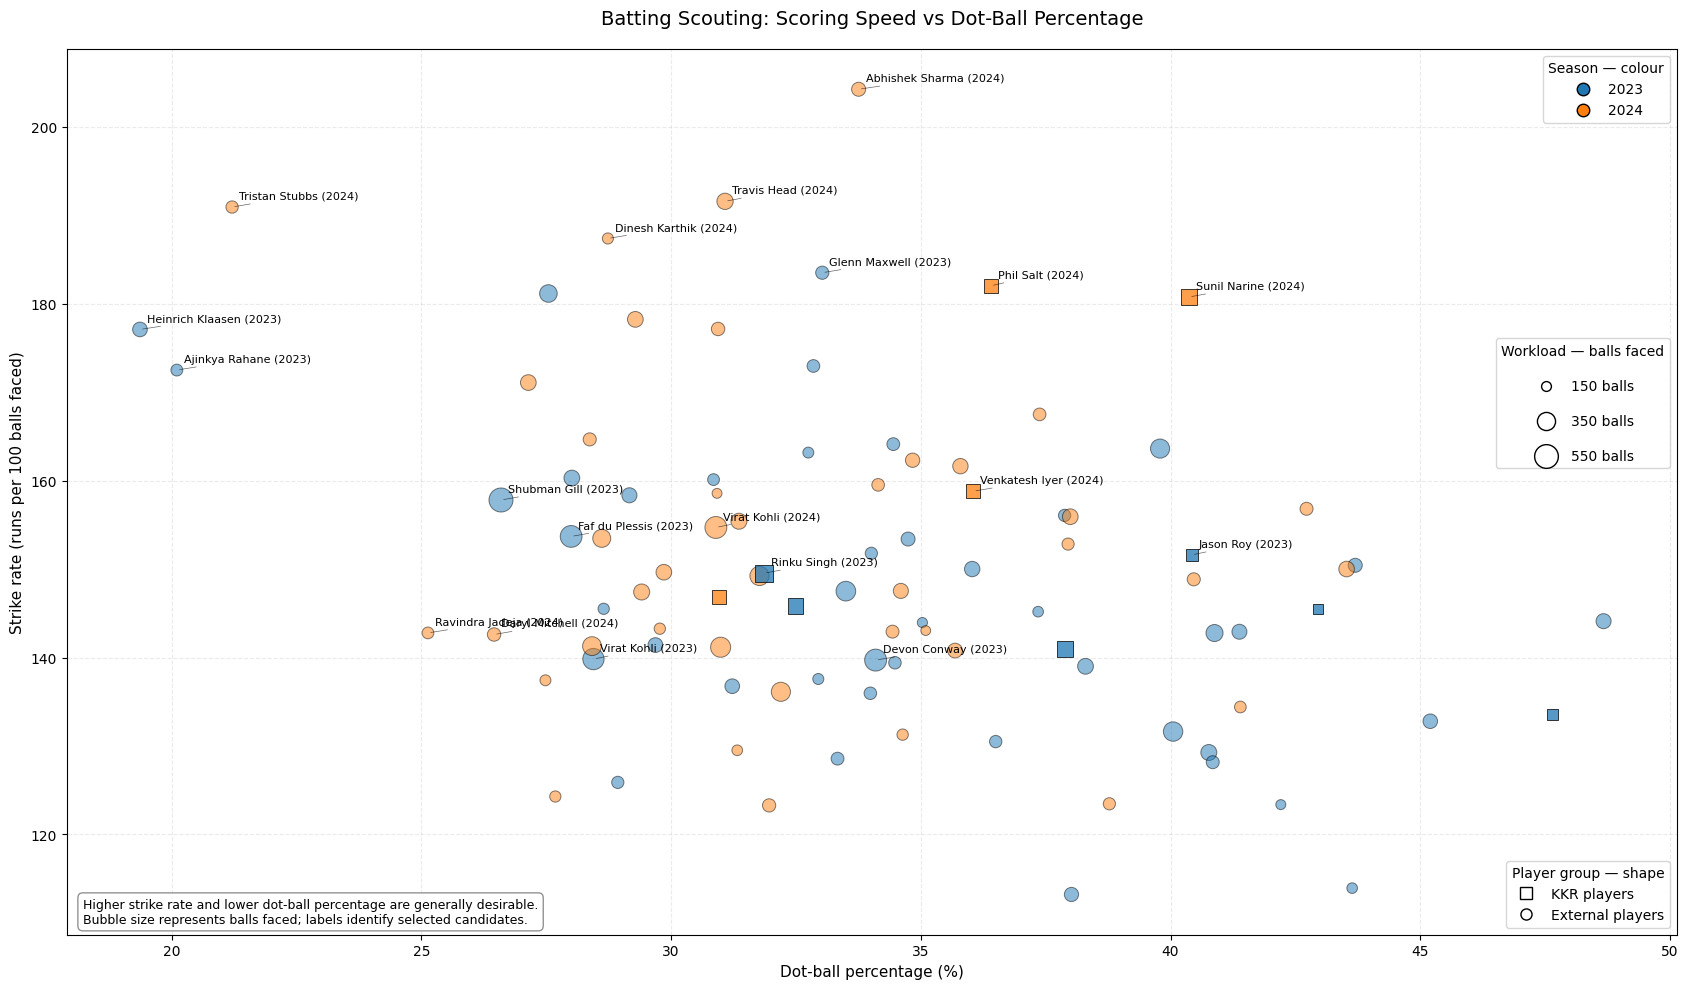

Batting scouting visualisation generated.
Records plotted: 94
2023 records: 49
2024 records: 45
KKR player-season records: 10
External player-season records: 84
Players selected for labelling: 19


In [162]:
# ============================================================
# Step 43.2: Batting Scouting — Player-Labelled Visualisation
#
# Colour:
#   2023 = Blue
#   2024 = Orange
#
# Marker:
#   KKR players     = Square
#   External players = Circle
#
# Bubble size:
#   Balls faced
# ============================================================

from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import importlib.util


# ------------------------------------------------------------
# 1. Prepare plotting data
# ------------------------------------------------------------

batting_plot_data = overall_batting_candidates.dropna(
    subset=[
        "year",
        "bat",
        "strike_rate",
        "dot_ball_pct",
        "runs",
        "balls_faced",
    ]
).copy()

# Ensure KKR classification exists and contains Boolean values.
if "is_kkr_player" not in batting_plot_data.columns:
    batting_plot_data["is_kkr_player"] = False

batting_plot_data["is_kkr_player"] = (
    batting_plot_data["is_kkr_player"]
    .fillna(False)
    .astype(bool)
)

# Retain only the seasons covered by the analysis.
batting_plot_data = batting_plot_data.loc[
    batting_plot_data["year"].isin([2023, 2024])
].copy()

assert not batting_plot_data.empty, (
    "No batting records are available for plotting."
)


# ------------------------------------------------------------
# 2. Establish the visual conventions
# ------------------------------------------------------------

SEASON_COLORS = {
    2023: "tab:blue",
    2024: "tab:orange",
}

PLAYER_MARKERS = {
    True: "s",   # KKR players
    False: "o",  # External players
}


# ------------------------------------------------------------
# 3. Scale bubble sizes by batting workload
# ------------------------------------------------------------

min_balls = batting_plot_data["balls_faced"].min()
max_balls = batting_plot_data["balls_faced"].max()

if max_balls > min_balls:
    batting_plot_data["bubble_size"] = (
        50
        + 250
        * (
            batting_plot_data["balls_faced"] - min_balls
        )
        / (max_balls - min_balls)
    )
else:
    batting_plot_data["bubble_size"] = 150


# ------------------------------------------------------------
# 4. Select players to label
# ------------------------------------------------------------

# Label candidates who stand out in at least one metric:
# - Highest strike rates
# - Highest run totals
# - Lowest dot-ball percentages
#
# Also include leading KKR players so that internal benchmarks
# are visible in the chart.

label_indices = set(
    batting_plot_data.nlargest(
        5, "strike_rate"
    ).index.tolist()
    + batting_plot_data.nlargest(
        5, "runs"
    ).index.tolist()
    + batting_plot_data.nsmallest(
        5, "dot_ball_pct"
    ).index.tolist()
)

kkr_standouts = (
    batting_plot_data.loc[
        batting_plot_data["is_kkr_player"]
    ]
    .sort_values(
        ["strike_rate", "runs"],
        ascending=[False, False],
    )
    .head(5)
)

label_indices.update(kkr_standouts.index.tolist())


# ------------------------------------------------------------
# 5. Plot the batting scouting chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(17, 10))

# Plot each season and player group separately.
# This ensures colour and marker shape have consistent meanings.

for year in [2023, 2024]:
    for is_kkr in [False, True]:

        subset = batting_plot_data.loc[
            batting_plot_data["year"].eq(year)
            & batting_plot_data["is_kkr_player"].eq(is_kkr)
        ]

        if subset.empty:
            continue

        ax.scatter(
            subset["dot_ball_pct"],
            subset["strike_rate"],
            s=subset["bubble_size"],
            c=SEASON_COLORS[year],
            marker=PLAYER_MARKERS[is_kkr],
            alpha=0.75 if is_kkr else 0.50,
            edgecolors="black",
            linewidths=0.7,
            zorder=3 if is_kkr else 2,
        )


# ------------------------------------------------------------
# 6. Label selected players
# ------------------------------------------------------------

texts = []

for idx in label_indices:

    if idx not in batting_plot_data.index:
        continue

    row = batting_plot_data.loc[idx]

    player_name = row["bat"]
    year = int(row["year"])

    label = f"{player_name} ({year})"

    annotation = ax.annotate(
        label,
        xy=(
            row["dot_ball_pct"],
            row["strike_rate"],
        ),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=8,
        arrowprops={
            "arrowstyle": "-",
            "linewidth": 0.5,
            "alpha": 0.6,
        },
        zorder=4,
    )

    texts.append(annotation)


# Reduce overlapping labels if adjustText is installed.
if (
    importlib.util.find_spec("adjustText") is not None
    and texts
):
    from adjustText import adjust_text

    adjust_text(
        texts,
        ax=ax,
        arrowprops={
            "arrowstyle": "-",
            "linewidth": 0.5,
            "alpha": 0.6,
        },
    )


# ------------------------------------------------------------
# 7. Chart titles, axes, and grid
# ------------------------------------------------------------

ax.set_xlabel(
    "Dot-ball percentage (%)",
    fontsize=11,
)

ax.set_ylabel(
    "Strike rate (runs per 100 balls faced)",
    fontsize=11,
)

ax.set_title(
    "Batting Scouting: Scoring Speed vs Dot-Ball Percentage",
    fontsize=14,
    pad=18,
)

ax.grid(
    True,
    alpha=0.25,
    linestyle="--",
)

ax.set_axisbelow(True)


# ------------------------------------------------------------
# 8. Legend 1: Season colours
# ------------------------------------------------------------

season_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor=SEASON_COLORS[2023],
        markeredgecolor="black",
        markersize=9,
        label="2023",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor=SEASON_COLORS[2024],
        markeredgecolor="black",
        markersize=9,
        label="2024",
    ),
]

season_legend = ax.legend(
    handles=season_handles,
    title="Season — colour",
    loc="upper right",
    frameon=True,
)

ax.add_artist(season_legend)


# ------------------------------------------------------------
# 9. Legend 2: Player-group markers
# ------------------------------------------------------------

player_handles = [
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=8,
        label="KKR players",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=8,
        label="External players",
    ),
]

player_legend = ax.legend(
    handles=player_handles,
    title="Player group — shape",
    loc="lower right",
    frameon=True,
)

ax.add_artist(player_legend)


# ------------------------------------------------------------
# 10. Legend 3: Workload / bubble size
# ------------------------------------------------------------

# Select reference workload values from the observed range.
workload_values = sorted(
    set(
        int(round(value / 50) * 50)
        for value in np.linspace(
            min_balls,
            max_balls,
            num=3,
        )
    )
)

workload_values = [
    value
    for value in workload_values
    if value > 0
]

if not workload_values:
    workload_values = [int(min_balls)]

workload_handles = []

for workload in workload_values:

    if max_balls > min_balls:
        reference_size = (
            50
            + 250
            * (workload - min_balls)
            / (max_balls - min_balls)
        )
    else:
        reference_size = 150

    workload_handles.append(
        ax.scatter(
            [],
            [],
            s=max(50, reference_size),
            marker="o",
            facecolors="white",
            edgecolors="black",
            label=f"{workload} balls",
        )
    )

ax.legend(
    handles=workload_handles,
    title="Workload — balls faced",
    loc="center right",
    bbox_to_anchor=(1.0, 0.60),
    frameon=True,
    labelspacing=1.5,
)


# ------------------------------------------------------------
# 11. Interpretation note
# ------------------------------------------------------------

ax.text(
    0.01,
    0.01,
    "Higher strike rate and lower dot-ball percentage are generally desirable.\n"
    "Bubble size represents balls faced; labels identify selected candidates.",
    transform=ax.transAxes,
    fontsize=9,
    va="bottom",
    ha="left",
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "grey",
        "alpha": 0.85,
    },
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Validation summary
# ------------------------------------------------------------

print("Batting scouting visualisation generated.")
print("Records plotted:", len(batting_plot_data))
print(
    "2023 records:",
    int(batting_plot_data["year"].eq(2023).sum()),
)
print(
    "2024 records:",
    int(batting_plot_data["year"].eq(2024).sum()),
)
print(
    "KKR player-season records:",
    int(batting_plot_data["is_kkr_player"].sum()),
)
print(
    "External player-season records:",
    int((~batting_plot_data["is_kkr_player"]).sum()),
)
print("Players selected for labelling:", len(label_indices))

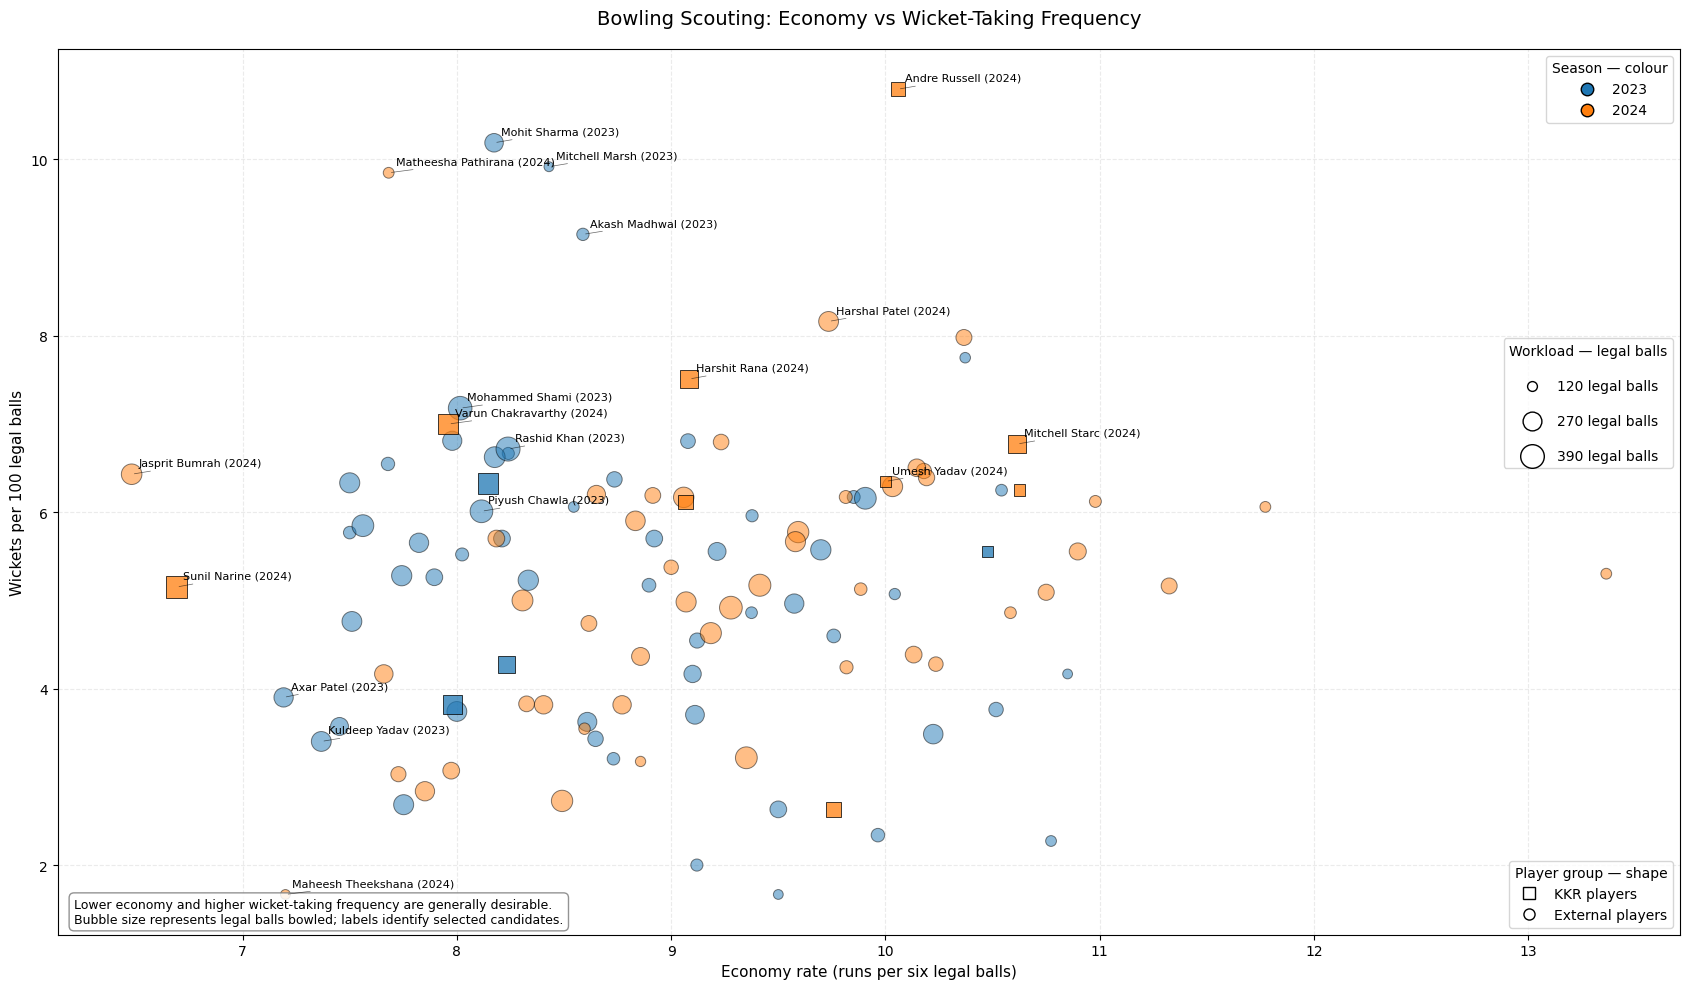

Bowling scouting visualisation generated.
Records plotted: 116
2023 records: 59
2024 records: 57
KKR player-season records: 13
External player-season records: 103
Players selected for labelling: 18


In [163]:
# ============================================================
# Step 43.3: Bowling Scouting — Player-Labelled Visualisation
#
# Colour:
#   2023 = Blue
#   2024 = Orange
#
# Marker:
#   KKR players      = Square
#   External players = Circle
#
# Bubble size:
#   Legal balls bowled
# ============================================================

from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import importlib.util


# ------------------------------------------------------------
# 1. Prepare plotting data
# ------------------------------------------------------------

bowling_plot_data = overall_bowling_candidates.dropna(
    subset=[
        "year",
        "bowl",
        "economy",
        "wickets_per_100_balls",
        "legal_balls",
        "wickets",
    ]
).copy()

# Ensure KKR classification exists and contains Boolean values.
if "is_kkr_player" not in bowling_plot_data.columns:
    bowling_plot_data["is_kkr_player"] = False

bowling_plot_data["is_kkr_player"] = (
    bowling_plot_data["is_kkr_player"]
    .fillna(False)
    .astype(bool)
)

# Retain only the seasons covered by the analysis.
bowling_plot_data = bowling_plot_data.loc[
    bowling_plot_data["year"].isin([2023, 2024])
].copy()

assert not bowling_plot_data.empty, (
    "No bowling records are available for plotting."
)


# ------------------------------------------------------------
# 2. Establish the visual conventions
# ------------------------------------------------------------

SEASON_COLORS = {
    2023: "tab:blue",
    2024: "tab:orange",
}

PLAYER_MARKERS = {
    True: "s",   # KKR players
    False: "o",  # External players
}


# ------------------------------------------------------------
# 3. Scale bubble sizes by bowling workload
# ------------------------------------------------------------

min_balls = bowling_plot_data["legal_balls"].min()
max_balls = bowling_plot_data["legal_balls"].max()

if max_balls > min_balls:
    bowling_plot_data["bubble_size"] = (
        50
        + 250
        * (
            bowling_plot_data["legal_balls"] - min_balls
        )
        / (max_balls - min_balls)
    )
else:
    bowling_plot_data["bubble_size"] = 150


# ------------------------------------------------------------
# 4. Select players to label
# ------------------------------------------------------------

# Label candidates who stand out in:
# - Wickets per 100 legal balls
# - Economy rate
# - Total wickets
#
# Include KKR's strongest bowlers as internal benchmarks.

label_indices = set(
    bowling_plot_data.nlargest(
        5, "wickets_per_100_balls"
    ).index.tolist()
    + bowling_plot_data.nsmallest(
        5, "economy"
    ).index.tolist()
    + bowling_plot_data.nlargest(
        5, "wickets"
    ).index.tolist()
)

kkr_standouts = (
    bowling_plot_data.loc[
        bowling_plot_data["is_kkr_player"]
    ]
    .sort_values(
        ["wickets_per_100_balls", "economy"],
        ascending=[False, True],
    )
    .head(5)
)

label_indices.update(kkr_standouts.index.tolist())


# ------------------------------------------------------------
# 5. Plot the bowling scouting chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(17, 10))

# Plot each season and player group separately.
# Colour represents season; shape represents player group.

for year in [2023, 2024]:
    for is_kkr in [False, True]:

        subset = bowling_plot_data.loc[
            bowling_plot_data["year"].eq(year)
            & bowling_plot_data["is_kkr_player"].eq(is_kkr)
        ]

        if subset.empty:
            continue

        ax.scatter(
            subset["economy"],
            subset["wickets_per_100_balls"],
            s=subset["bubble_size"],
            c=SEASON_COLORS[year],
            marker=PLAYER_MARKERS[is_kkr],
            alpha=0.75 if is_kkr else 0.50,
            edgecolors="black",
            linewidths=0.7,
            zorder=3 if is_kkr else 2,
        )


# ------------------------------------------------------------
# 6. Label selected players
# ------------------------------------------------------------

texts = []

for idx in label_indices:

    if idx not in bowling_plot_data.index:
        continue

    row = bowling_plot_data.loc[idx]

    player_name = row["bowl"]
    year = int(row["year"])

    label = f"{player_name} ({year})"

    annotation = ax.annotate(
        label,
        xy=(
            row["economy"],
            row["wickets_per_100_balls"],
        ),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=8,
        arrowprops={
            "arrowstyle": "-",
            "linewidth": 0.5,
            "alpha": 0.6,
        },
        zorder=4,
    )

    texts.append(annotation)


# Reduce overlapping labels if adjustText is installed.
if (
    importlib.util.find_spec("adjustText") is not None
    and texts
):
    from adjustText import adjust_text

    adjust_text(
        texts,
        ax=ax,
        arrowprops={
            "arrowstyle": "-",
            "linewidth": 0.5,
            "alpha": 0.6,
        },
    )


# ------------------------------------------------------------
# 7. Chart titles, axes, and grid
# ------------------------------------------------------------

ax.set_xlabel(
    "Economy rate (runs per six legal balls)",
    fontsize=11,
)

ax.set_ylabel(
    "Wickets per 100 legal balls",
    fontsize=11,
)

ax.set_title(
    "Bowling Scouting: Economy vs Wicket-Taking Frequency",
    fontsize=14,
    pad=18,
)

ax.grid(
    True,
    alpha=0.25,
    linestyle="--",
)

ax.set_axisbelow(True)


# ------------------------------------------------------------
# 8. Legend 1: Season colours
# ------------------------------------------------------------

season_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor=SEASON_COLORS[2023],
        markeredgecolor="black",
        markersize=9,
        label="2023",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor=SEASON_COLORS[2024],
        markeredgecolor="black",
        markersize=9,
        label="2024",
    ),
]

season_legend = ax.legend(
    handles=season_handles,
    title="Season — colour",
    loc="upper right",
    frameon=True,
)

ax.add_artist(season_legend)


# ------------------------------------------------------------
# 9. Legend 2: Player-group markers
# ------------------------------------------------------------

player_handles = [
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=8,
        label="KKR players",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=8,
        label="External players",
    ),
]

player_legend = ax.legend(
    handles=player_handles,
    title="Player group — shape",
    loc="lower right",
    frameon=True,
)

ax.add_artist(player_legend)


# ------------------------------------------------------------
# 10. Legend 3: Workload / bubble size
# ------------------------------------------------------------

# Select reference workload values from the observed range.
workload_values = sorted(
    set(
        int(round(value / 30) * 30)
        for value in np.linspace(
            min_balls,
            max_balls,
            num=3,
        )
    )
)

workload_values = [
    value
    for value in workload_values
    if value > 0
]

if not workload_values:
    workload_values = [int(min_balls)]

workload_handles = []

for workload in workload_values:

    if max_balls > min_balls:
        reference_size = (
            50
            + 250
            * (workload - min_balls)
            / (max_balls - min_balls)
        )
    else:
        reference_size = 150

    workload_handles.append(
        ax.scatter(
            [],
            [],
            s=max(50, reference_size),
            marker="o",
            facecolors="white",
            edgecolors="black",
            label=f"{workload} legal balls",
        )
    )

ax.legend(
    handles=workload_handles,
    title="Workload — legal balls",
    loc="center right",
    bbox_to_anchor=(1.0, 0.60),
    frameon=True,
    labelspacing=1.5,
)


# ------------------------------------------------------------
# 11. Interpretation note
# ------------------------------------------------------------

ax.text(
    0.01,
    0.01,
    "Lower economy and higher wicket-taking frequency are generally desirable.\n"
    "Bubble size represents legal balls bowled; labels identify selected candidates.",
    transform=ax.transAxes,
    fontsize=9,
    va="bottom",
    ha="left",
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "grey",
        "alpha": 0.85,
    },
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Validation summary
# ------------------------------------------------------------

print("Bowling scouting visualisation generated.")
print("Records plotted:", len(bowling_plot_data))
print(
    "2023 records:",
    int(bowling_plot_data["year"].eq(2023).sum()),
)
print(
    "2024 records:",
    int(bowling_plot_data["year"].eq(2024).sum()),
)
print(
    "KKR player-season records:",
    int(bowling_plot_data["is_kkr_player"].sum()),
)
print(
    "External player-season records:",
    int((~bowling_plot_data["is_kkr_player"]).sum()),
)
print("Players selected for labelling:", len(label_indices))

### 12.10 Final Scouting Recommendations

Shortlists are restricted to external players. KKR players are retained as
separate benchmarks, so the output clearly distinguishes a potential recruit
from an incumbent comparison point.

Each role score combines multiple role-relevant metrics, workload, and a small
bonus for two-season evidence. The result remains a transparent screening tool:
it does not establish availability, price, fitness, overseas eligibility, or
future performance.


In [164]:
# Step 44.2: External shortlists and separate KKR benchmarks.


def percentile(series, ascending=True):
    return series.rank(method="average", pct=True, ascending=ascending).fillna(0)


def evidence_label(workload, minimum, seasons_observed):
    if workload >= 2 * minimum and seasons_observed >= 2:
        return "Stronger: high workload, two-season evidence"
    if seasons_observed >= 2:
        return "Moderate: two-season evidence"
    if workload >= 2 * minimum:
        return "Moderate: high single-season workload"
    return "Minimum screened workload; validate further"


def add_batting_role_score(role, candidates):
    pool = candidates.copy()
    source = batting_scouting if role == "Top-order batter" else phase_batting_scouting.loc[
        phase_batting_scouting["match_phase"].eq(ROLE_BATTING_PHASES[role])
    ]
    seasons = source.groupby("p_bat")["year"].nunique().rename("seasons_observed")
    pool = pool.merge(seasons, on="p_bat", how="left", validate="many_to_one")
    pool["cross_season_evidence"] = pool["seasons_observed"].ge(2)
    pool["role_score"] = (
        0.35 * percentile(pool["strike_rate"])
        + 0.20 * percentile(pool["runs"])
        + 0.15 * percentile(pool["dot_ball_pct"], ascending=False)
        + 0.20 * percentile(pool["balls_faced"])
        + 0.10 * pool["cross_season_evidence"].astype(int)
    )
    pool["evidence_flag"] = [
        evidence_label(workload, MIN_OVERALL_BALLS if role == "Top-order batter" else MIN_PHASE_BALLS, seasons)
        for workload, seasons in zip(pool["balls_faced"], pool["seasons_observed"])
    ]
    return pool


def add_bowling_role_score(role, candidates):
    pool = candidates.copy()
    source = phase_bowling_scouting.loc[
        phase_bowling_scouting["match_phase"].eq(ROLE_BOWLING_PHASES[role])
    ]
    seasons = source.groupby("p_bowl")["year"].nunique().rename("seasons_observed")
    pool = pool.merge(seasons, on="p_bowl", how="left", validate="many_to_one")
    pool["cross_season_evidence"] = pool["seasons_observed"].ge(2)
    pool["role_score"] = (
        0.35 * percentile(pool["wickets_per_100_balls"])
        + 0.25 * percentile(pool["economy"], ascending=False)
        + 0.15 * percentile(pool["bowling_dot_pct"])
        + 0.15 * percentile(pool["legal_balls"])
        + 0.10 * pool["cross_season_evidence"].astype(int)
    )
    pool["evidence_flag"] = [
        evidence_label(workload, MIN_PHASE_LEGAL_BALLS, seasons)
        for workload, seasons in zip(pool["legal_balls"], pool["seasons_observed"])
    ]
    return pool


external_shortlist_records = []
kkr_benchmark_records = []

for role, candidates in role_batting_candidates.items():
    scored = add_batting_role_score(role, candidates)
    external = scored.loc[~scored["is_kkr_player"]].nlargest(3, "role_score")
    benchmarks = scored.loc[scored["is_kkr_player"]].nlargest(3, "role_score")
    for _, row in external.iterrows():
        external_shortlist_records.append({
            "role": role, "discipline": "Batting", "player": row["bat"], "year": row["year"],
            "workload": row["balls_faced"], "primary_metric": "Strike rate", "primary_value": row["strike_rate"],
            "supporting_metric": "Dot-ball percentage", "supporting_value": row["dot_ball_pct"],
            "role_score": row["role_score"], "seasons_observed": row["seasons_observed"],
            "evidence_flag": row["evidence_flag"],
        })
    for _, row in benchmarks.iterrows():
        kkr_benchmark_records.append({
            "role": role, "discipline": "Batting", "player": row["bat"], "year": row["year"],
            "workload": row["balls_faced"], "role_score": row["role_score"],
            "seasons_observed": row["seasons_observed"], "evidence_flag": row["evidence_flag"],
        })

for role, candidates in role_bowling_candidates.items():
    scored = add_bowling_role_score(role, candidates)
    external = scored.loc[~scored["is_kkr_player"]].nlargest(3, "role_score")
    benchmarks = scored.loc[scored["is_kkr_player"]].nlargest(3, "role_score")
    for _, row in external.iterrows():
        external_shortlist_records.append({
            "role": role, "discipline": "Bowling", "player": row["bowl"], "year": row["year"],
            "workload": row["legal_balls"], "primary_metric": "Wickets per 100 legal balls", "primary_value": row["wickets_per_100_balls"],
            "supporting_metric": "Economy", "supporting_value": row["economy"],
            "role_score": row["role_score"], "seasons_observed": row["seasons_observed"],
            "evidence_flag": row["evidence_flag"],
        })
    for _, row in benchmarks.iterrows():
        kkr_benchmark_records.append({
            "role": role, "discipline": "Bowling", "player": row["bowl"], "year": row["year"],
            "workload": row["legal_balls"], "role_score": row["role_score"],
            "seasons_observed": row["seasons_observed"], "evidence_flag": row["evidence_flag"],
        })

external_scouting_shortlist = pd.DataFrame(external_shortlist_records)
kkr_role_benchmarks = pd.DataFrame(kkr_benchmark_records)

assert not external_scouting_shortlist.empty
assert not kkr_role_benchmarks.empty
assert external_scouting_shortlist["player"].notna().all()

print("External scouting shortlist (ranked role screens):")
display(external_scouting_shortlist.sort_values(["discipline", "role", "role_score"], ascending=[True, True, False]))
print("\nKKR role benchmarks (not recruitment recommendations):")
display(kkr_role_benchmarks.sort_values(["discipline", "role", "role_score"], ascending=[True, True, False]))


External scouting shortlist (ranked role screens):


,role,discipline,player,year,workload,primary_metric,primary_value,supporting_metric,supporting_value,role_score,seasons_observed,evidence_flag
6,Death-overs batter,Batting,Tristan Stubbs,2024,96,Strike rate,262.500000,Dot-ball percentage,11.458333,0.947368,2,Moderate: two-season evidence
7,Death-overs batter,Batting,Dinesh Karthik,2024,116,Strike rate,214.655172,Dot-ball percentage,27.586207,0.880263,2,Moderate: two-season evidence
8,Death-overs batter,Batting,Heinrich Klaasen,2024,91,Strike rate,214.285714,Dot-ball percentage,23.076923,0.856579,2,Moderate: two-season evidence
3,Middle-order batter,Batting,Suryakumar Yadav,2023,246,Strike rate,182.926829,Dot-ball percentage,25.203252,0.956000,2,"Stronger: high workload, two-season evidence"
4,Middle-order batter,Batting,Shubman Gill,2023,272,Strike rate,157.720588,Dot-ball percentage,20.588235,0.917500,2,"Stronger: high workload, two-season evidence"
5,Middle-order batter,Batting,Sai Sudharsan,2024,205,Strike rate,152.195122,Dot-ball percentage,20.487805,0.881000,2,"Stronger: high workload, two-season evidence"
0,Top-order batter,Batting,Suryakumar Yadav,2023,334,Strike rate,181.137725,Dot-ball percentage,27.544910,0.924468,2,"Stronger: high workload, two-season evidence"
1,Top-order batter,Batting,Shubman Gill,2023,564,Strike rate,157.801418,Dot-ball percentage,26.595745,0.891489,2,"Stronger: high workload, two-season evidence"
2,Top-order batter,Batting,Nicholas Pooran,2024,280,Strike rate,178.214286,Dot-ball percentage,29.285714,0.856383,2,Moderate: two-season evidence
15,Death-overs bowler,Bowling,Matheesha Pathirana,2023,177,Wickets per 100 legal balls,10.169492,Economy,8.000000,0.921154,2,"Stronger: high workload, two-season evidence"



KKR role benchmarks (not recruitment recommendations):


,role,discipline,player,year,workload,role_score,seasons_observed,evidence_flag
6,Death-overs batter,Batting,Rinku Singh,2023,150,0.782895,2,"Stronger: high workload, two-season evidence"
7,Death-overs batter,Batting,Andre Russell,2024,64,0.571053,2,Moderate: two-season evidence
8,Death-overs batter,Batting,Andre Russell,2023,82,0.364474,2,Moderate: two-season evidence
3,Middle-order batter,Batting,Venkatesh Iyer,2023,146,0.845000,2,"Stronger: high workload, two-season evidence"
4,Middle-order batter,Batting,Sunil Narine,2024,93,0.698500,2,Moderate: two-season evidence
5,Middle-order batter,Batting,Nitish Rana,2023,193,0.672500,2,"Stronger: high workload, two-season evidence"
0,Top-order batter,Batting,Sunil Narine,2024,270,0.751064,2,Moderate: two-season evidence
1,Top-order batter,Batting,Phil Salt,2024,239,0.732447,2,Moderate: two-season evidence
2,Top-order batter,Batting,Rinku Singh,2023,317,0.710106,2,"Stronger: high workload, two-season evidence"
15,Death-overs bowler,Bowling,Harshit Rana,2024,85,0.708654,2,Moderate: two-season evidence


### 12.11 Limitations of the Scouting Analysis

The scouting results are constrained by the available dataset.

1. The analysis covers IPL 2023 and 2024, not current player form.
2. Workload thresholds reduce but do not eliminate small-sample uncertainty.
3. Player roles are inferred from phase-specific participation and
   performance; the dataset does not provide a definitive tactical role
   for every player.
4. The source bowling-runs field contains identified inconsistencies.
5. Team composition, player availability, auction price, salary,
   contractual status, fitness, and injury history are not established
   by this dataset.
6. Historical performance does not guarantee future performance.
7. The candidate rankings are descriptive and should not be interpreted
   as causal estimates of player value.

The recommendations should therefore be treated as a data-driven
scouting shortlist for further investigation, not as definitive
recruitment instructions.

### 12.12 Scouting Conclusion

The shortlist is now restricted to external players, with KKR incumbents kept
as role benchmarks. Scores are multi-metric and report workload and
cross-season evidence rather than elevating a single short burst of performance.

The next sections translate phase, opposition, venue, and match-state evidence
into tactical recommendations.


# 13. Tactical Analysis: Opposition, Venue, and Match State

This section uses complete KKR matches only. It is descriptive: opposition and
venue splits are flagged when the sample is below three matches, and win
probability is the supplied model estimate rather than a model trained here.


In [165]:
# 13.1 Build a complete-match KKR tactical table.

complete_kkr_match_ids = match_summary.loc[
    match_summary["represented_innings"].eq(2)
    & match_summary["represented_batting_teams"].eq(2)
    & match_summary["p_match"].isin(kkr_match_ids),
    "p_match",
]

match_teams = (
    team_match.loc[team_match["p_match"].isin(complete_kkr_match_ids)]
    .groupby("p_match")["team"]
    .agg(list)
)

def opponent_for_match(teams):
    opponents = [team for team in teams if team != KKR]
    return opponents[0] if len(opponents) == 1 else pd.NA

kkr_tactical_matches = (
    kkr_batting_order.loc[kkr_batting_order["p_match"].isin(complete_kkr_match_ids)]
    [["p_match", "year", "innings_score", "situation", "outcome"]]
    .rename(columns={"innings_score": "kkr_score"})
    .merge(match_summary[["p_match", "ground"]], on="p_match", how="left", validate="one_to_one")
)
kkr_tactical_matches["opponent"] = kkr_tactical_matches["p_match"].map(match_teams.map(opponent_for_match))

assert kkr_tactical_matches["p_match"].is_unique
assert kkr_tactical_matches["opponent"].notna().all()
assert len(kkr_tactical_matches) == len(kkr_batting_order)

opposition_summary = (
    kkr_tactical_matches.groupby("opponent")
    .agg(
        matches=("p_match", "nunique"),
        wins=("outcome", lambda s: int(s.eq("Win").sum())),
        losses=("outcome", lambda s: int(s.eq("Loss").sum())),
        mean_kkr_score=("kkr_score", "mean"),
    )
    .reset_index()
)
opposition_summary["win_pct"] = 100 * opposition_summary["wins"] / opposition_summary["matches"]
opposition_summary["evidence_flag"] = np.where(
    opposition_summary["matches"].ge(3), "Interpret with care", "Low sample: descriptive only"
)

venue_summary = (
    kkr_tactical_matches.groupby("ground")
    .agg(
        matches=("p_match", "nunique"),
        wins=("outcome", lambda s: int(s.eq("Win").sum())),
        mean_kkr_score=("kkr_score", "mean"),
    )
    .reset_index()
)
venue_summary["win_pct"] = 100 * venue_summary["wins"] / venue_summary["matches"]
venue_summary["evidence_flag"] = np.where(
    venue_summary["matches"].ge(3), "Interpret with care", "Low sample: descriptive only"
)

print("Opposition summary")
display(opposition_summary.sort_values(["matches", "win_pct"], ascending=[False, False]))
print("\nVenue summary")
display(venue_summary.sort_values(["matches", "win_pct"], ascending=[False, False]))


Opposition summary


,opponent,matches,wins,losses,mean_kkr_score,win_pct,evidence_flag
8,Sunrisers Hyderabad,5,4,1,172.200000,80.000000,Interpret with care
7,Royal Challengers Bengaluru,4,4,0,202.000000,100.000000,Interpret with care
1,Delhi Capitals,3,2,1,185.000000,66.666667,Interpret with care
3,Lucknow Super Giants,3,2,1,190.666667,66.666667,Interpret with care
4,Mumbai Indians,3,2,1,170.333333,66.666667,Interpret with care
0,Chennai Super Kings,3,1,2,156.666667,33.333333,Interpret with care
5,Punjab Kings,3,1,2,196.333333,33.333333,Interpret with care
2,Gujarat Titans,2,1,1,193.000000,50.000000,Low sample: descriptive only
6,Rajasthan Royals,2,0,2,186.000000,0.000000,Low sample: descriptive only



Venue summary


,ground,matches,wins,mean_kkr_score,win_pct,evidence_flag
3,"Eden Gardens, Kolkata",14,7,190.285714,50.000000,Interpret with care
5,"MA Chidambaram Stadium, Chepauk, Chennai",3,2,132.666667,66.666667,Interpret with care
4,"M Chinnaswamy Stadium, Bengaluru",2,2,193.000000,100.000000,Low sample: descriptive only
6,"Narendra Modi Stadium, Ahmedabad",2,2,185.500000,100.000000,Low sample: descriptive only
9,"Wankhede Stadium, Mumbai",2,1,177.000000,50.000000,Low sample: descriptive only
1,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,1,1,235.000000,100.000000,Low sample: descriptive only
2,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,1,1,272.000000,100.000000,Low sample: descriptive only
8,"Rajiv Gandhi International Stadium, Uppal, Hyd...",1,1,171.000000,100.000000,Low sample: descriptive only
0,"Arun Jaitley Stadium, Delhi",1,0,127.000000,0.000000,Low sample: descriptive only
7,"Punjab Cricket Association IS Bindra Stadium, ...",1,0,146.000000,0.000000,Low sample: descriptive only


In [166]:
# 13.2 Capture KKR's state at the end of 10 and 15 overs.


def state_at_legal_ball_limit(limit):
    eligible = df_analysis.loc[
        df_analysis["p_match"].isin(complete_kkr_match_ids)
        & df_analysis["team_bat"].eq(KKR)
        & df_analysis["legal_delivery"]
        & df_analysis["inns_balls"].le(limit)
    ].copy()
    state = (
        eligible.sort_values(["p_match", "inns_balls", "ball_id"])
        .groupby("p_match", as_index=False)
        .tail(1)
        [["p_match", "inns_runs", "inns_wkts", "inns_balls", "wprob"]]
        .rename(columns={
            "inns_runs": f"runs_at_{limit}_balls",
            "inns_wkts": f"wkts_at_{limit}_balls",
            "inns_balls": f"balls_at_{limit}",
            "wprob": f"wprob_at_{limit}_balls",
        })
    )
    return state

state_at_10 = state_at_legal_ball_limit(60)
state_at_15 = state_at_legal_ball_limit(90)

match_state_summary = (
    kkr_tactical_matches[["p_match", "year", "opponent", "situation", "outcome"]]
    .merge(state_at_10, on="p_match", how="left", validate="one_to_one")
    .merge(state_at_15, on="p_match", how="left", validate="one_to_one")
)

assert match_state_summary["p_match"].is_unique
assert match_state_summary["runs_at_60_balls"].notna().sum() > 0

state_outcome_summary = (
    match_state_summary.groupby("outcome")
    .agg(
        matches=("p_match", "nunique"),
        mean_runs_at_10=("runs_at_60_balls", "mean"),
        mean_wkts_at_10=("wkts_at_60_balls", "mean"),
        mean_wprob_at_10=("wprob_at_60_balls", "mean"),
        mean_runs_at_15=("runs_at_90_balls", "mean"),
        mean_wkts_at_15=("wkts_at_90_balls", "mean"),
    )
    .reset_index()
)

print("KKR match-state summary: end of 10 and 15 overs")
display(match_state_summary.sort_values(["year", "p_match"]))
print("\nMatch-state patterns by outcome")
display(state_outcome_summary)


KKR match-state summary: end of 10 and 15 overs


,p_match,year,opponent,situation,outcome,runs_at_60_balls,wkts_at_60_balls,balls_at_60,wprob_at_60_balls,runs_at_90_balls,wkts_at_90_balls,balls_at_90,wprob_at_90_balls
0,1359476,2023,Punjab Kings,Chased,Loss,80,4,60,15.18,136,6,90,17.87
1,1359483,2023,Royal Challengers Bengaluru,Batted first,Win,79,3,60,74.15,140,5,90,83.87
2,1359487,2023,Gujarat Titans,Chased,Win,86,2,60,20.45,149,3,90,47.86
3,1359493,2023,Sunrisers Hyderabad,Chased,Loss,96,4,60,2.48,142,5,90,0.71
4,1359496,2023,Mumbai Indians,Batted first,Loss,90,3,60,78.12,140,4,90,78.12
5,1359502,2023,Delhi Capitals,Batted first,Loss,64,4,60,53.67,94,8,90,10.69
6,1359507,2023,Chennai Super Kings,Chased,Loss,76,4,60,0.51,137,5,90,0.18
7,1359510,2023,Royal Challengers Bengaluru,Batted first,Win,88,2,60,66.62,131,2,90,67.64
8,1359513,2023,Gujarat Titans,Batted first,Loss,84,2,60,56.30,134,4,90,71.11
9,1359521,2023,Sunrisers Hyderabad,Batted first,Win,90,3,60,83.42,129,5,90,61.61



Match-state patterns by outcome


,outcome,matches,mean_runs_at_10,mean_wkts_at_10,mean_wprob_at_10,mean_runs_at_15,mean_wkts_at_15
0,Loss,11,86.818182,2.818182,49.635455,133.000000,4.545455
1,Win,17,95.882353,2.647059,74.923529,143.705882,3.529412


# 14. Phase-Specific Tactical Recommendations

Recommendations below follow directly from the descriptive phase and match-state
analysis. They are not causal claims, and they retain the documented 2024
fixture-coverage limitation.


In [167]:
# 14.1 Produce an evidence-linked tactical recommendation table.

phase_lookup = kkr_batting_phase.set_index(["year", "match_phase"])
bowling_lookup = kkr_bowling_phase.set_index(["year", "match_phase"])

recommendation_rows = [
    {
        "priority": 1,
        "area": "Powerplay batting",
        "evidence": (
            f"Runs per over faced increased from {phase_lookup.loc[(2023, 'Powerplay'), 'runs_per_over']:.2f} "
            f"to {phase_lookup.loc[(2024, 'Powerplay'), 'runs_per_over']:.2f}."
        ),
        "recommended action": "Retain an aggressive top-order blueprint; evaluate recruits against this existing scoring benchmark.",
        "caveat": "Season comparison is descriptive and fixture sets differ.",
    },
    {
        "priority": 2,
        "area": "Powerplay bowling",
        "evidence": (
            f"Economy moved from {bowling_lookup.loc[(2023, 'Powerplay'), 'economy_rate']:.2f} "
            f"to {bowling_lookup.loc[(2024, 'Powerplay'), 'economy_rate']:.2f}, while wickets per 20 overs rose from "
            f"{bowling_lookup.loc[(2023, 'Powerplay'), 'wickets_per_20_overs']:.2f} to "
            f"{bowling_lookup.loc[(2024, 'Powerplay'), 'wickets_per_20_overs']:.2f}."
        ),
        "recommended action": "Keep the wicket-seeking intent, but use line, length, and boundary review to reduce the cost of attacking spells.",
        "caveat": "Requires delivery-type analysis before changing personnel.",
    },
    {
        "priority": 3,
        "area": "Middle-overs bowling",
        "evidence": (
            f"Economy was stable ({bowling_lookup.loc[(2023, 'Middle'), 'economy_rate']:.2f} to "
            f"{bowling_lookup.loc[(2024, 'Middle'), 'economy_rate']:.2f}) while wickets per 20 overs increased "
            f"({bowling_lookup.loc[(2023, 'Middle'), 'wickets_per_20_overs']:.2f} to "
            f"{bowling_lookup.loc[(2024, 'Middle'), 'wickets_per_20_overs']:.2f})."
        ),
        "recommended action": "Preserve wicket-taking middle-over matchups and use opposition splits only where at least three matches are available.",
        "caveat": "Opponent tables are descriptive; do not overfit to one or two fixtures.",
    },
    {
        "priority": 4,
        "area": "Death overs",
        "evidence": (
            f"Bowling economy improved from {bowling_lookup.loc[(2023, 'Death'), 'economy_rate']:.2f} "
            f"to {bowling_lookup.loc[(2024, 'Death'), 'economy_rate']:.2f}; death batting rate rose from "
            f"{phase_lookup.loc[(2023, 'Death'), 'runs_per_over']:.2f} to "
            f"{phase_lookup.loc[(2024, 'Death'), 'runs_per_over']:.2f}."
        ),
        "recommended action": "Retain specialised death roles and require stronger phase workloads before treating a scouting candidate as a replacement option.",
        "caveat": "2024 death batting covers 12 represented matches, versus 14 in 2023.",
    },
    {
        "priority": 5,
        "area": "In-match monitoring",
        "evidence": "The new 10-over and 15-over tables link runs, wickets, and supplied batting-team win probability to eventual outcome.",
        "recommended action": "Use the 10-over state as a review trigger for batting intent, bowling matchups, and the next phase's risk level.",
        "caveat": "Supplied win probability is descriptive model output, not a causal prescription.",
    },
]

tactical_recommendations = pd.DataFrame(recommendation_rows)
assert tactical_recommendations["recommended action"].notna().all()
display(tactical_recommendations)


,priority,area,evidence,recommended action,caveat
0,1,Powerplay batting,Runs per over faced increased from 7.70 to 10.05.,Retain an aggressive top-order blueprint; eval...,Season comparison is descriptive and fixture s...
1,2,Powerplay bowling,"Economy moved from 9.60 to 9.73, while wickets...","Keep the wicket-seeking intent, but use line, ...",Requires delivery-type analysis before changin...
2,3,Middle-overs bowling,Economy was stable (8.13 to 8.11) while wicket...,Preserve wicket-taking middle-over matchups an...,Opponent tables are descriptive; do not overfi...
3,4,Death overs,Bowling economy improved from 10.59 to 9.82; d...,Retain specialised death roles and require str...,2024 death batting covers 12 represented match...
4,5,In-match monitoring,"The new 10-over and 15-over tables link runs, ...",Use the 10-over state as a review trigger for ...,Supplied win probability is descriptive model ...


### Tactical Conclusion

The analysis supports an aggressive Powerplay batting baseline, continued
wicket-taking intent in the middle overs, and specialised death-over roles.
Opposition and venue results should guide preparation only when their sample
flags permit it; otherwise, they remain hypotheses for the next season rather
than prescriptive matchup rules.


# 15. Machine Learning: Player Performance Clustering

This section applies unsupervised K-Means clustering to player-season batting and
bowling records. It complements the descriptive and scouting analysis above by grouping
player-seasons with similar statistical profiles. The clusters are exploratory
decision-support tools, not predictive models.

It reuses the player-season and player-season-phase aggregates built in Section 8.

In [168]:
# ============================================================
# 15.1 Machine-Learning Imports and Compatibility Bridge
# ============================================================
# The clustering code below expects `batter_name` and `bowler_name`.
# In this notebook the same fields are named `bat` and `bowl`, so
# alias columns are added. Existing columns are not changed.
# ============================================================

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

player_season_batting = player_season_batting.assign(
    batter_name=player_season_batting["bat"]
)
player_season_phase_batting = player_season_phase_batting.assign(
    batter_name=player_season_phase_batting["bat"]
)
player_season_bowling = player_season_bowling.assign(
    bowler_name=player_season_bowling["bowl"]
)

print("Machine-learning setup completed.")

Machine-learning setup completed.


In [169]:
# Minimum workload thresholds
MIN_BATTING_BALLS = 60
MIN_PHASE_BATTING_BALLS = 12

# Core season-level batting metrics
batting_base = player_season_batting.loc[
    player_season_batting["balls_faced"].ge(MIN_BATTING_BALLS)
].copy()

# Phase-level batting metrics
batting_phase_features = (
    player_season_phase_batting
    .pivot(
        index=["p_bat", "year", "batter_name"],
        columns="match_phase",
        values="strike_rate",
    )
    .rename(
        columns={
            "Powerplay": "powerplay_strike_rate",
            "Middle": "middle_strike_rate",
            "Death": "death_strike_rate",
        }
    )
    .reset_index()
)

# Independently calculate phase workload
batting_phase_balls = (
    player_season_phase_batting
    .pivot(
        index=["p_bat", "year", "batter_name"],
        columns="match_phase",
        values="balls_faced",
    )
    .rename(
        columns={
            "Powerplay": "powerplay_balls",
            "Middle": "middle_balls",
            "Death": "death_balls",
        }
    )
    .reset_index()
)

# Combine the core and phase-level metrics
batting_features = batting_base.merge(
    batting_phase_features,
    on=["p_bat", "year", "batter_name"],
    how="left",
    validate="one_to_one",
)

batting_features = batting_features.merge(
    batting_phase_balls,
    on=["p_bat", "year", "batter_name"],
    how="left",
    validate="one_to_one",
)

# Keep only records with sufficient observations in every phase
batting_features = batting_features.loc[
    batting_features["powerplay_balls"].ge(MIN_PHASE_BATTING_BALLS)
    & batting_features["middle_balls"].ge(MIN_PHASE_BATTING_BALLS)
    & batting_features["death_balls"].ge(MIN_PHASE_BATTING_BALLS)
].copy()

batting_cluster_columns = [
    "strike_rate",
    "dot_ball_pct",
    "boundary_ball_pct",
    "powerplay_strike_rate",
    "middle_strike_rate",
    "death_strike_rate",
]

print("Eligible player-season batting records:", len(batting_features))
print("Unique players:", batting_features["p_bat"].nunique())
print("Seasons represented:", sorted(batting_features["year"].unique()))

display(
    batting_features[
        ["batter_name", "year", "runs", "balls_faced"] + batting_cluster_columns
    ]
    .head(10)
)

Eligible player-season batting records: 67
Unique players: 51
Seasons represented: [np.int64(2023), np.int64(2024)]


,batter_name,year,runs,balls_faced,strike_rate,dot_ball_pct,boundary_ball_pct,powerplay_strike_rate,middle_strike_rate,death_strike_rate
0,Moeen Ali,2023,124,91,136.263736,40.659341,19.780220,135.294118,124.000000,162.500000
1,Shikhar Dhawan,2023,373,261,142.911877,41.379310,23.371648,137.068966,132.673267,181.818182
5,Faf du Plessis,2023,730,475,153.684211,28.000000,20.210526,168.544601,135.087719,185.294118
6,David Warner,2023,516,392,131.632653,40.051020,20.153061,145.853659,117.834395,106.666667
8,Virat Kohli,2023,639,457,139.824945,28.446389,17.724289,136.818182,134.010152,185.000000
13,Manish Pandey,2023,160,146,109.589041,37.671233,12.328767,105.714286,113.265306,92.307692
16,Jos Buttler,2023,392,282,139.007092,38.297872,19.858156,131.205674,138.596491,181.481481
17,Rilee Rossouw,2023,209,141,148.226950,36.170213,19.858156,123.333333,140.000000,219.047619
19,Marcus Stoinis,2023,408,272,150.000000,36.029412,20.220588,158.064516,130.601093,206.896552
20,Glenn Maxwell,2023,400,218,183.486239,33.027523,27.522936,180.434783,176.595745,219.354839


In [170]:
print("Batting feature dataset shape:", batting_features.shape)

print("\nMissing values in clustering features:")
display(
    batting_features[batting_cluster_columns]
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

print("\nRecords per season:")
display(
    batting_features["year"]
    .value_counts()
    .sort_index()
    .rename_axis("year")
    .reset_index(name="player_season_records")
)

Batting feature dataset shape: (67, 20)

Missing values in clustering features:


,missing_count
strike_rate,0
dot_ball_pct,0
boundary_ball_pct,0
powerplay_strike_rate,0
middle_strike_rate,0
death_strike_rate,0



Records per season:


,year,player_season_records
0,2023,38
1,2024,29


In [171]:
# Remove the overall strike rate to avoid over-weighting scoring rate.
batting_cluster_columns = [
    "dot_ball_pct",
    "boundary_ball_pct",
    "powerplay_strike_rate",
    "middle_strike_rate",
    "death_strike_rate",
]

# Extract and standardise features.
X_batting = batting_features[batting_cluster_columns].copy()

batting_scaler = StandardScaler()
X_batting_scaled = batting_scaler.fit_transform(X_batting)

# Evaluate candidate cluster counts.
batting_cluster_results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_batting_scaled)

    score = silhouette_score(X_batting_scaled, labels)

    batting_cluster_results.append(
        {
            "n_clusters": k,
            "inertia": model.inertia_,
            "silhouette_score": score,
            "smallest_cluster_size": pd.Series(labels).value_counts().min(),
        }
    )

batting_cluster_evaluation = pd.DataFrame(batting_cluster_results)

display(
    batting_cluster_evaluation.round(3)
)

,n_clusters,inertia,silhouette_score,smallest_cluster_size
0,2,238.316,0.232,30
1,3,200.643,0.219,14
2,4,173.665,0.193,8
3,5,151.718,0.190,7
4,6,134.280,0.211,2


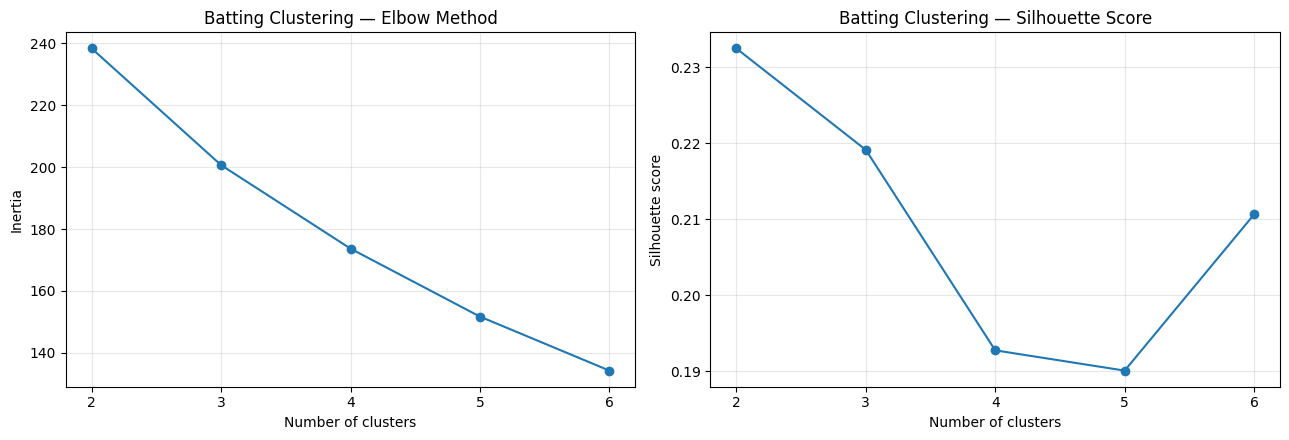

In [172]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    batting_cluster_evaluation["n_clusters"],
    batting_cluster_evaluation["inertia"],
    marker="o",
)
axes[0].set_title("Batting Clustering — Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(batting_cluster_evaluation["n_clusters"])
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    batting_cluster_evaluation["n_clusters"],
    batting_cluster_evaluation["silhouette_score"],
    marker="o",
)
axes[1].set_title("Batting Clustering — Silhouette Score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(batting_cluster_evaluation["n_clusters"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [173]:
# Fit the selected batting clustering model.
BATTER_N_CLUSTERS = 2

batting_kmeans = KMeans(
    n_clusters=BATTER_N_CLUSTERS,
    random_state=42,
    n_init=20,
)

batting_features["batting_cluster"] = batting_kmeans.fit_predict(
    X_batting_scaled
)

# K-Means label numbers are arbitrary and can differ between machines
# and library versions. Relabel so that Cluster 0 is always the
# higher-tempo group (higher mean overall strike rate).
cluster_mean_sr = batting_features.groupby("batting_cluster")["strike_rate"].mean()
relabel_map = {
    old_label: new_label
    for new_label, old_label in enumerate(
        cluster_mean_sr.sort_values(ascending=False).index
    )
}
batting_features["batting_cluster"] = batting_features["batting_cluster"].map(
    relabel_map
)

# Inspect cluster sizes.
print("BATTING CLUSTER SIZES")
display(
    batting_features["batting_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("batting_cluster")
    .reset_index(name="player_season_records")
)

# Profile clusters using interpretable, original-scale metrics.
batting_cluster_profiles = (
    batting_features
    .groupby("batting_cluster")
    .agg(
        player_season_records=("p_bat", "size"),
        distinct_players=("p_bat", "nunique"),
        mean_runs=("runs", "mean"),
        mean_balls_faced=("balls_faced", "mean"),
        mean_strike_rate=("strike_rate", "mean"),
        mean_dot_ball_pct=("dot_ball_pct", "mean"),
        mean_boundary_ball_pct=("boundary_ball_pct", "mean"),
        mean_powerplay_sr=("powerplay_strike_rate", "mean"),
        mean_middle_sr=("middle_strike_rate", "mean"),
        mean_death_sr=("death_strike_rate", "mean"),
    )
    .round(2)
)

print("BATTING CLUSTER PROFILES")
display(batting_cluster_profiles)

BATTING CLUSTER SIZES


,batting_cluster,player_season_records
0,0,30
1,1,37


BATTING CLUSTER PROFILES


,player_season_records,distinct_players,mean_runs,mean_balls_faced,mean_strike_rate,mean_dot_ball_pct,mean_boundary_ball_pct,mean_powerplay_sr,mean_middle_sr,mean_death_sr
batting_cluster,,,,,,,,,,
0,30,26,420.13,262.57,160.66,33.76,23.53,156.76,153.00,206.92
1,37,30,340.86,247.78,135.03,34.20,17.12,113.42,132.27,160.68


In [174]:
# Identify player-season combinations representing KKR batting records.
kkr_batter_seasons = (
    df_features.loc[
        df_features["team_bat"].eq("Kolkata Knight Riders"),
        ["p_bat", "year", "bat"],
    ]
    .drop_duplicates()
    .rename(columns={"bat": "kkr_batter_name"})
)

# Match KKR player-seasons to the clustering results.
kkr_batting_clusters = batting_features.merge(
    kkr_batter_seasons,
    on=["p_bat", "year"],
    how="inner",
    validate="one_to_one",
)

print("KKR PLAYER-SEASON CLUSTER ASSIGNMENTS")
display(
    kkr_batting_clusters[
        [
            "year",
            "kkr_batter_name",
            "runs",
            "balls_faced",
            "strike_rate",
            "powerplay_strike_rate",
            "middle_strike_rate",
            "death_strike_rate",
            "batting_cluster",
        ]
    ]
    .sort_values(["year", "batting_cluster", "runs"], ascending=[True, True, False])
    .reset_index(drop=True)
)

print("KKR CLUSTER DISTRIBUTION BY SEASON")
display(
    kkr_batting_clusters
    .groupby(["year", "batting_cluster"])
    .agg(
        player_season_records=("p_bat", "size"),
        distinct_players=("p_bat", "nunique"),
    )
    .reset_index()
)

KKR PLAYER-SEASON CLUSTER ASSIGNMENTS


,year,kkr_batter_name,runs,balls_faced,strike_rate,powerplay_strike_rate,middle_strike_rate,death_strike_rate,batting_cluster
0,2023,Nitish Rana,413,293,140.955631,132.394366,139.378238,172.413793,1
1,2023,Venkatesh Iyer,404,277,145.848375,130.275229,160.273973,127.272727,1
2,2024,Sunil Narine,488,270,180.740741,170.303030,190.322581,250.000000,0
3,2024,Venkatesh Iyer,370,233,158.798283,222.000000,142.142857,139.534884,0
4,2024,Shreyas Iyer,351,239,146.861925,69.230769,140.127389,201.785714,1


KKR CLUSTER DISTRIBUTION BY SEASON


,year,batting_cluster,player_season_records,distinct_players
0,2023,1,2,2
1,2024,0,2,2
2,2024,1,1,1


In [175]:
# Minimum season-level workload: 60 legal balls (10 overs).
MIN_BOWLING_BALLS = 60

bowling_features = player_season_bowling.loc[
    player_season_bowling["legal_balls"].ge(MIN_BOWLING_BALLS)
].copy()

bowling_cluster_columns = [
    "economy_rate",
    "bowling_dot_pct",
    "wickets_per_100_balls",
    "boundary_balls_per_100_legal_balls",
    "extras_per_20_overs",
]

print("Eligible player-season bowling records:", len(bowling_features))
print("Unique players:", bowling_features["p_bowl"].nunique())
print("Seasons represented:", sorted(bowling_features["year"].unique()))

print("\nMissing values in clustering features:")
display(
    bowling_features[bowling_cluster_columns]
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

print("\nBowling feature sample:")
display(
    bowling_features[
        ["bowler_name", "year", "legal_balls", "wickets"]
        + bowling_cluster_columns
    ].head(10)
)

Eligible player-season bowling records: 164
Unique players: 111
Seasons represented: [np.int64(2023), np.int64(2024)]

Missing values in clustering features:


,missing_count
economy_rate,0
bowling_dot_pct,0
wickets_per_100_balls,0
boundary_balls_per_100_legal_balls,0
extras_per_20_overs,0



Bowling feature sample:


,bowler_name,year,legal_balls,wickets,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,extras_per_20_overs
0,Moeen Ali,2023,156,9,7.500000,34.615385,5.769231,12.820513,0.769231
1,Ravichandran Ashwin,2023,294,14,7.510204,29.931973,4.761905,11.564626,6.530612
2,Karn Sharma,2023,129,10,10.372093,28.682171,7.751938,22.480620,2.790698
3,Amit Mishra,2023,114,7,7.842105,26.315789,6.140351,14.035088,1.052632
4,Piyush Chawla,2023,366,22,8.114754,32.786885,6.010929,16.666667,1.639344
6,Sunil Narine,2023,288,11,7.979167,29.166667,3.819444,13.888889,3.750000
9,Ravindra Jadeja,2023,342,20,7.561404,30.994152,5.847953,11.988304,3.859649
10,Ishant Sharma,2023,150,10,8.240000,43.333333,6.666667,22.000000,7.200000
12,Wayne Parnell,2023,151,9,9.377483,36.423841,5.960265,23.178808,4.768212
13,Mitchell Marsh,2023,121,12,8.429752,28.099174,9.917355,13.223140,10.909091


In [176]:
X_bowling = bowling_features[bowling_cluster_columns].copy()

bowling_scaler = StandardScaler()
X_bowling_scaled = bowling_scaler.fit_transform(X_bowling)

bowling_cluster_results = []

for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_bowling_scaled)

    bowling_cluster_results.append(
        {
            "n_clusters": k,
            "inertia": model.inertia_,
            "silhouette_score": silhouette_score(
                X_bowling_scaled,
                labels,
            ),
            "smallest_cluster_size": pd.Series(labels).value_counts().min(),
        }
    )

bowling_cluster_evaluation = pd.DataFrame(bowling_cluster_results)

display(bowling_cluster_evaluation.round(3))

,n_clusters,inertia,silhouette_score,smallest_cluster_size
0,2,584.368,0.253,78
1,3,468.336,0.248,53
2,4,413.544,0.240,10
3,5,362.585,0.242,7


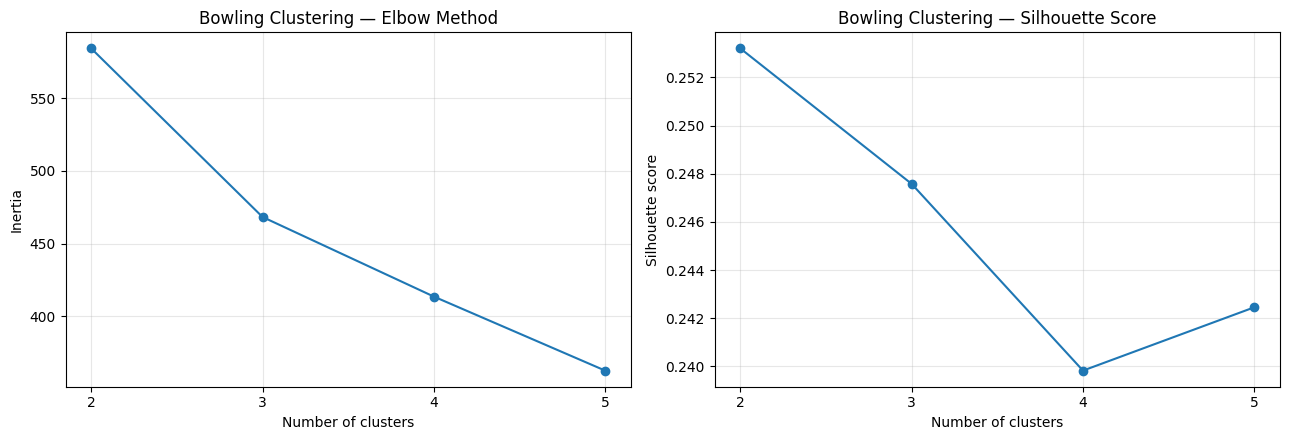

In [177]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    bowling_cluster_evaluation["n_clusters"],
    bowling_cluster_evaluation["inertia"],
    marker="o",
)
axes[0].set_title("Bowling Clustering — Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(bowling_cluster_evaluation["n_clusters"])
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    bowling_cluster_evaluation["n_clusters"],
    bowling_cluster_evaluation["silhouette_score"],
    marker="o",
)
axes[1].set_title("Bowling Clustering — Silhouette Score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(bowling_cluster_evaluation["n_clusters"])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [178]:
BOWLER_N_CLUSTERS = 2

bowling_kmeans = KMeans(
    n_clusters=BOWLER_N_CLUSTERS,
    random_state=42,
    n_init=20,
)

bowling_features["bowling_cluster"] = bowling_kmeans.fit_predict(
    X_bowling_scaled
)

print("BOWLING CLUSTER SIZES")
display(
    bowling_features["bowling_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("bowling_cluster")
    .reset_index(name="player_season_records")
)

bowling_cluster_profiles = (
    bowling_features
    .groupby("bowling_cluster")
    .agg(
        player_season_records=("p_bowl", "size"),
        distinct_players=("p_bowl", "nunique"),
        mean_legal_balls=("legal_balls", "mean"),
        mean_wickets=("wickets", "mean"),
        mean_economy=("economy_rate", "mean"),
        mean_dot_pct=("bowling_dot_pct", "mean"),
        mean_wickets_per_100_balls=("wickets_per_100_balls", "mean"),
        mean_boundary_balls_per_100=(
            "boundary_balls_per_100_legal_balls", "mean"
        ),
        mean_extras_per_20_overs=("extras_per_20_overs", "mean"),
    )
    .round(2)
)

print("BOWLING CLUSTER PROFILES")
display(bowling_cluster_profiles)

BOWLING CLUSTER SIZES


,bowling_cluster,player_season_records
0,0,86
1,1,78


BOWLING CLUSTER PROFILES


,player_season_records,distinct_players,mean_legal_balls,mean_wickets,mean_economy,mean_dot_pct,mean_wickets_per_100_balls,mean_boundary_balls_per_100,mean_extras_per_20_overs
bowling_cluster,,,,,,,,,
0,86,64,207.05,10.86,8.24,34.40,5.25,16.67,4.60
1,78,61,164.99,8.50,10.27,32.81,4.93,24.81,8.71


In [179]:
# Identify KKR bowler-season combinations from the delivery-level data.
kkr_bowler_seasons = (
    df_features.loc[
        df_features["team_bowl"].eq("Kolkata Knight Riders"),
        ["p_bowl", "year", "bowl"],
    ]
    .drop_duplicates()
    .rename(columns={"bowl": "kkr_bowler_name"})
)

# Join the KKR records to the league-wide cluster assignments.
kkr_bowling_clusters = bowling_features.merge(
    kkr_bowler_seasons,
    on=["p_bowl", "year"],
    how="inner",
    validate="one_to_one",
)

print("KKR BOWLER-SEASON CLUSTER ASSIGNMENTS")
display(
    kkr_bowling_clusters[
        [
            "year",
            "kkr_bowler_name",
            "legal_balls",
            "wickets",
            "economy_rate",
            "bowling_dot_pct",
            "wickets_per_100_balls",
            "boundary_balls_per_100_legal_balls",
            "extras_per_20_overs",
            "bowling_cluster",
        ]
    ]
    .sort_values(
        ["year", "bowling_cluster", "wickets"],
        ascending=[True, True, False],
    )
    .reset_index(drop=True)
)

print("KKR BOWLING CLUSTER DISTRIBUTION BY SEASON")
display(
    kkr_bowling_clusters
    .groupby(["year", "bowling_cluster"])
    .agg(
        player_season_records=("p_bowl", "size"),
        distinct_players=("p_bowl", "nunique"),
    )
    .reset_index()
)

KKR BOWLER-SEASON CLUSTER ASSIGNMENTS


,year,kkr_bowler_name,legal_balls,wickets,economy_rate,bowling_dot_pct,wickets_per_100_balls,boundary_balls_per_100_legal_balls,extras_per_20_overs,bowling_cluster
0,2023,Varun Chakravarthy,316,20,8.145570,36.392405,6.329114,17.405063,4.556962,0
1,2023,Sunil Narine,288,11,7.979167,29.166667,3.819444,13.888889,3.750000,0
2,2023,Suyash Sharma,234,10,8.230769,34.188034,4.273504,17.094017,2.564103,0
3,2023,Harshit Rana,102,5,8.647059,43.137255,4.901961,23.529412,7.058824,0
4,2023,Andre Russell,91,7,11.340659,34.065934,7.692308,28.571429,10.549451,1
5,2023,Shardul Thakur,126,7,10.476190,25.396825,5.555556,25.396825,5.714286,1
6,2023,Vaibhav Arora,96,5,9.125000,31.250000,5.208333,19.791667,15.000000,1
7,2023,Umesh Yadav,114,1,9.947368,35.964912,0.877193,25.438596,2.105263,1
8,2024,Varun Chakravarthy,300,21,7.960000,40.333333,7.000000,16.333333,3.600000,0
9,2024,Harshit Rana,253,19,9.083004,36.758893,7.509881,20.553360,5.217391,0


KKR BOWLING CLUSTER DISTRIBUTION BY SEASON


,year,bowling_cluster,player_season_records,distinct_players
0,2023,0,4,4
1,2023,1,4,4
2,2024,0,3,3
3,2024,1,3,3


In [180]:
kkr_bowling_cluster_mix = pd.crosstab(
    kkr_bowling_clusters["year"],
    kkr_bowling_clusters["bowling_cluster"],
)

kkr_bowling_cluster_pct = (
    pd.crosstab(
        kkr_bowling_clusters["year"],
        kkr_bowling_clusters["bowling_cluster"],
        normalize="index",
    )
    .mul(100)
    .round(1)
)

print("KKR BOWLER-SEASON COUNTS")
display(kkr_bowling_cluster_mix)

print("KKR BOWLER-SEASON DISTRIBUTION (%)")
display(kkr_bowling_cluster_pct)

KKR BOWLER-SEASON COUNTS


bowling_cluster,0,1
year,,
2023,4,4
2024,3,3


KKR BOWLER-SEASON DISTRIBUTION (%)


bowling_cluster,0,1
year,,
2023,50.0,50.0
2024,50.0,50.0


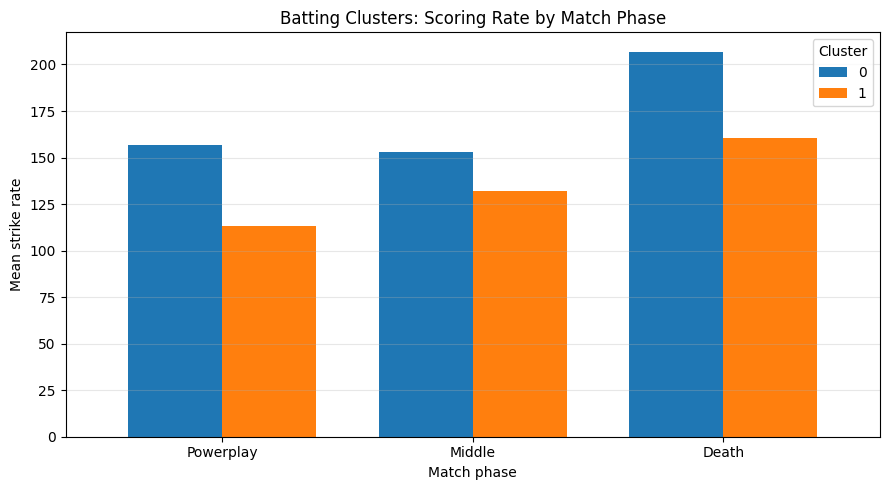

In [181]:
batting_plot_data = (
    batting_cluster_profiles[
        ["mean_powerplay_sr", "mean_middle_sr", "mean_death_sr"]
    ]
    .rename(
        columns={
            "mean_powerplay_sr": "Powerplay",
            "mean_middle_sr": "Middle",
            "mean_death_sr": "Death",
        }
    )
)

ax = batting_plot_data.T.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75,
)

ax.set_title("Batting Clusters: Scoring Rate by Match Phase")
ax.set_xlabel("Match phase")
ax.set_ylabel("Mean strike rate")
ax.legend(title="Cluster")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

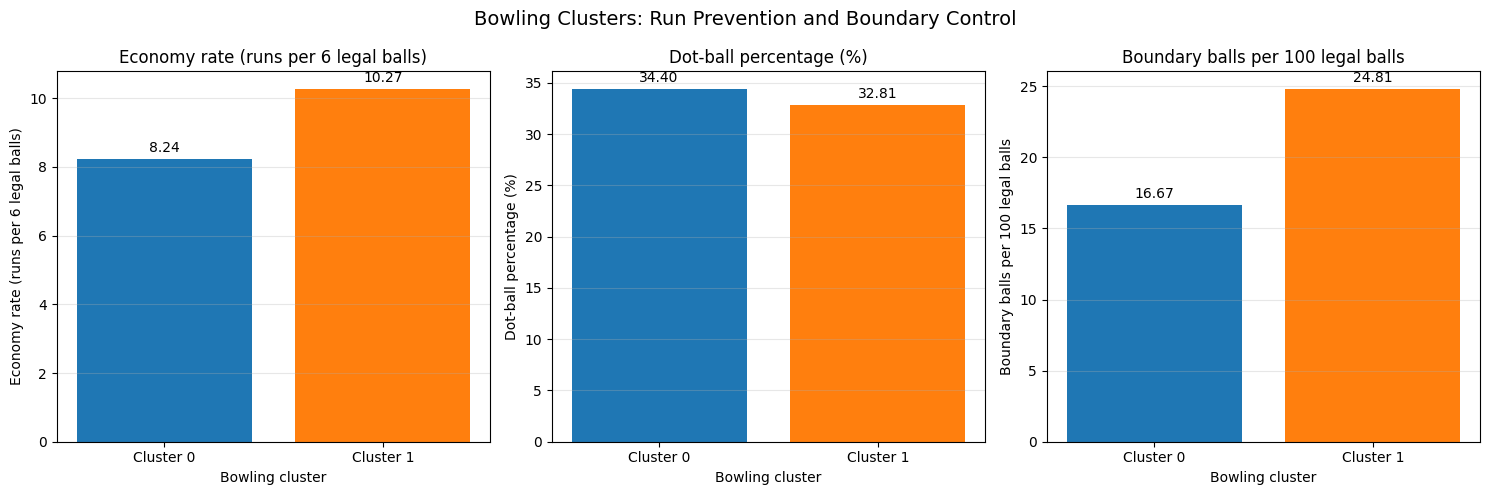

In [182]:
# Plot bowling cluster metrics in their original units.
bowling_control_metrics = [
    ("mean_economy", "Economy rate (runs per 6 legal balls)"),
    ("mean_dot_pct", "Dot-ball percentage (%)"),
    ("mean_boundary_balls_per_100", "Boundary balls per 100 legal balls"),
]

# Reuse the default Matplotlib colour cycle used in the batting chart.
cluster_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (metric, title) in zip(axes, bowling_control_metrics):
    values = bowling_cluster_profiles[metric]

    bars = ax.bar(
        values.index.astype(str),
        values.values,
        color=[
            cluster_colors[int(cluster)]
            for cluster in values.index
        ],
    )

    ax.set_title(title)
    ax.set_xlabel("Bowling cluster")
    ax.set_ylabel(title)
    ax.set_xticks(range(len(values)))
    ax.set_xticklabels(
        [f"Cluster {cluster}" for cluster in values.index]
    )
    ax.grid(axis="y", alpha=0.3)
    ax.bar_label(bars, fmt="%.2f", padding=3)

fig.suptitle(
    "Bowling Clusters: Run Prevention and Boundary Control",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## Interpretation of Player Performance Clusters

### Batting Clusters

The batting analysis identified two broad player-season profiles using K-Means clustering. The model uses standardised overall dot-ball percentage, boundary-ball percentage, and strike rates across the Powerplay, Middle Overs, and Death Overs.

**Cluster 0 — Higher-tempo, boundary-oriented batting**
- Higher average overall strike rate and boundary-ball percentage.
- Higher average strike rates across all three match phases.
- Average overall strike rate: approximately 160.66.
- Average boundary-ball percentage: approximately 23.53%.

**Cluster 1 — Lower-tempo batting**
- Lower average overall strike rate and boundary-ball percentage.
- Lower average strike rates across all three match phases.
- Average overall strike rate: approximately 135.03.
- Average boundary-ball percentage: approximately 17.12%.

The average dot-ball percentages are similar across the two clusters, suggesting that the distinction is driven more by scoring tempo and boundary frequency than by dot-ball avoidance alone.

The silhouette score for the selected two-cluster solution was approximately 0.232. This indicates relatively weak separation between clusters, so the profiles should be interpreted as broad tendencies rather than sharply distinct player types.

Only 67 player-season records met the batting eligibility criteria. Players needed at least 60 balls faced overall and at least 12 balls faced in each of the three match phases. This excludes some phase specialists and limits the population represented by the clusters.

### Bowling Clusters

The bowling analysis identified two broad player-season profiles using standardised economy rate, bowling dot-ball percentage, wickets per 100 legal balls, boundary balls per 100 legal balls, and extras per 20 overs.

**Cluster 0 — More controlled bowling**
- Average economy rate: 8.24 runs per six legal balls.
- Average dot-ball percentage: 34.40%.
- Average wickets per 100 legal balls: 5.25.
- Average boundary balls per 100 legal balls: 16.67.
- Average extras per 20 overs: 4.60.

**Cluster 1 — Higher-concession bowling**
- Average economy rate: 10.27 runs per six legal balls.
- Average dot-ball percentage: 32.81%.
- Average wickets per 100 legal balls: 4.93.
- Average boundary balls per 100 legal balls: 24.81.
- Average extras per 20 overs: 8.71.

Cluster 0 exhibits stronger run-control indicators: lower economy, fewer boundary balls, and fewer extras. Its average wicket rate is also modestly higher. These are cluster-level averages, not guarantees of individual performance.

The silhouette score for the selected two-cluster solution was approximately 0.253. As with batting, the separation is modest, and the clusters should be treated as descriptive profiles rather than definitive classifications.

The bowling analysis included 164 eligible player-season records, with a minimum of 60 legal balls bowled per player-season.

### KKR Player Profiles Across Seasons

Among the KKR batting records that met the clustering eligibility criteria, the distribution changed between seasons:
- **2023:** Two qualifying player-season records belonged to Cluster 1.
- **2024:** Two qualifying records belonged to Cluster 0 and one to Cluster 1.

The qualifying batting sample is small and should not be interpreted as a complete assessment of KKR's batting unit.

For bowling, the eligible KKR player-season records were evenly distributed across the two clusters in both seasons:
- **2023:** Four records in each cluster.
- **2024:** Three records in each cluster.

Varun Chakravarthy and Sunil Narine remained in Cluster 0 across the two seasons. Andre Russell remained in Cluster 1, although his individual wicket rate improved and his economy rate declined in 2024.

These examples illustrate why cluster labels must be interpreted alongside the underlying metrics. A player can improve substantially without changing clusters, and a cluster assignment does not by itself establish a player's value to the team.

### Limitations and Responsible Interpretation

1. **Limited time coverage:** The analysis covers only the 2023 and 2024 IPL seasons.
2. **Repeated player observations:** A player appearing in both seasons contributes two player-season records. These observations are not statistically independent.
3. **Role differences:** Batting position, match phase, bowling role, workload, opposition quality, and match situation can affect performance.
4. **Eligibility filters:** Minimum-ball thresholds improve the reliability of rate statistics but exclude low-workload players and some specialists.
5. **Modest cluster separation:** The silhouette scores indicate that the clusters are broad descriptive groupings, not naturally separated categories.
6. **Data-quality limitations:** The previously identified inconsistencies in the source `bowlruns` field may affect bowling-related metrics derived from it.
7. **No predictive or causal claims:** The clustering does not predict future performance, establish causality, or independently determine player selection and recruitment decisions.

### Conclusion

Player performance clustering provides a compact way to explore broad differences in batting tempo and bowling control. It complements the earlier descriptive analysis and scouting work by grouping player-season observations with similar statistical profiles.

However, the clusters should be used as an exploratory decision-support tool. Any player comparison or tactical recommendation should also consider role, workload, match context, sample size, and the underlying performance metrics.